In [ ]:
https://github.com/rishabhCMS/decaf/commit/52d7d5112c8911e4fd76bb2703019498a456d359
working commit with corrected jet and met
['#003f5c'
,'#2f4b7c'
,'#665191'
,'#a05195'
,'#d45087'
,'#f95d6a'
,'#ff7c43'
,'#ffa600']

In [1]:

from __future__ import print_function, division
from collections import defaultdict, OrderedDict
import gzip
import pickle
import json
import os
import uproot
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from coffea import hist, processor 
from coffea.hist import plot
from coffea.util import load, save

In [2]:
hists = load('../../../hists/UL_lep_monotop_v1_test_2018.scaled')
data={
    '2018':{
        'sre': 'EGamma',
        'srm': 'SingleMuon',
        'wjetm': 'SingleMuon',
        'ttbarm': 'SingleMuon',
        'wjete': 'EGamma',
        'ttbare': 'EGamma',
#         'zmcr': 'MET',
#         'zecr': 'EGamma',
#         'gcr': 'EGamma'
    }
}

data_hists   = hists['data']
bkg_hists    = hists['bkg']
signal_hists = hists['sig']

In [3]:
data_hists['mT_corrected'].integrate("systematic").integrate('region','wjete')[data['2018']['sre']].values()

{('EGamma',): array([    0.,     0., 23906., 16461., 14013.,  8750.,  5565.,  4900.,
         3255.,  1527.,  1494.])}

In [26]:
signal_hists['mT_corrected'].integrate('region','wjete').integrate('systematic', 'nominal').values()

{('Mphi-1000_Mchi-1000',): array([0.        , 0.        , 0.00044543, 0.00039987, 0.00061094,
        0.0006325 , 0.00061819, 0.00087165, 0.0009217 , 0.00069145,
        0.00149327]),
 ('Mphi-1000_Mchi-150',): array([0.        , 0.        , 2.73158417, 2.63861914, 3.8715903 ,
        4.03717384, 2.6876828 , 3.67992971, 4.09001447, 4.00814994,
        6.8209668 ]),
 ('Mphi-1250_Mchi-150',): array([0.        , 0.        , 1.05630434, 1.06205431, 1.62444822,
        1.85260573, 1.08899066, 1.74835232, 1.77214253, 1.25735204,
        3.62642106]),
 ('Mphi-1495_Mchi-750',): array([0.        , 0.        , 0.06536425, 0.09833555, 0.11788569,
        0.07986187, 0.10379545, 0.14253165, 0.17605291, 0.13084924,
        0.23676335]),
 ('Mphi-1500_Mchi-1000',): array([0.        , 0.        , 0.00079989, 0.00075048, 0.00126533,
        0.0009434 , 0.00050639, 0.00128326, 0.00119682, 0.00127128,
        0.00283255]),
 ('Mphi-1500_Mchi-150',): array([0.        , 0.        , 0.53543127, 0.55002546, 0.

In [ ]:
data_hists['mT_corrected'].integrate('region','wjete').integrate('systematic', 'nominal').values()[('EGamma',)]/bkg_hists['mT_corrected'].integrate('region','wjete').integrate('systematic', 'nominal').sum('process').values()[()]

In [5]:
bkg_hists['mT_corrected']

<Hist (process,region,systematic,mT_corrected) instance at 0x7f3b5bdc1b00>

In [4]:
signal_hists['mT_corrected']

<Hist (process,region,systematic,mT_corrected) instance at 0x7f3b593eedd8>

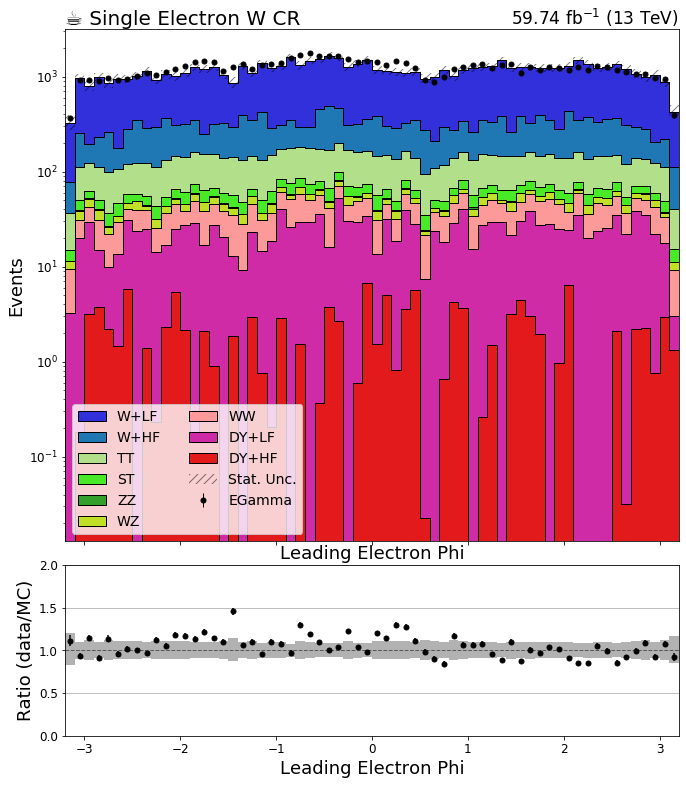

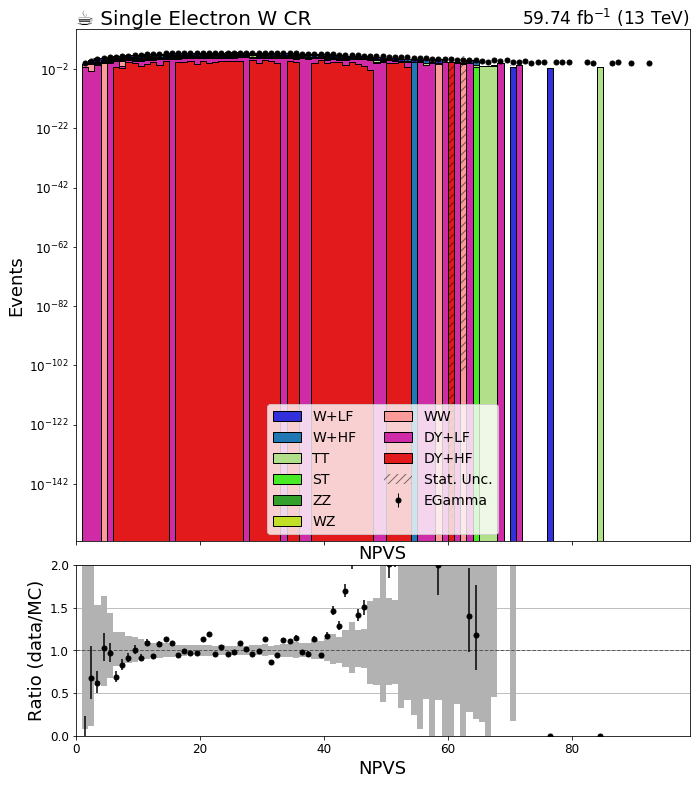

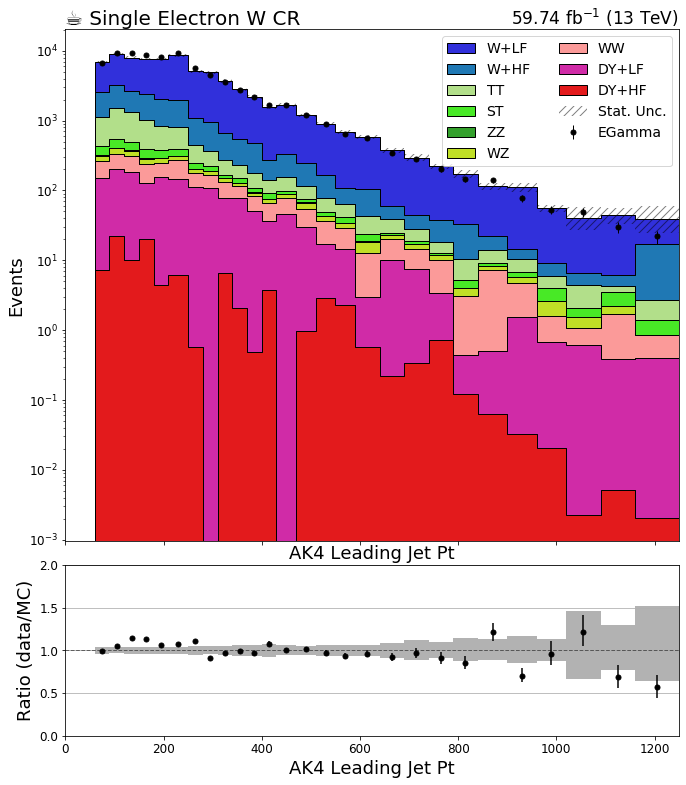

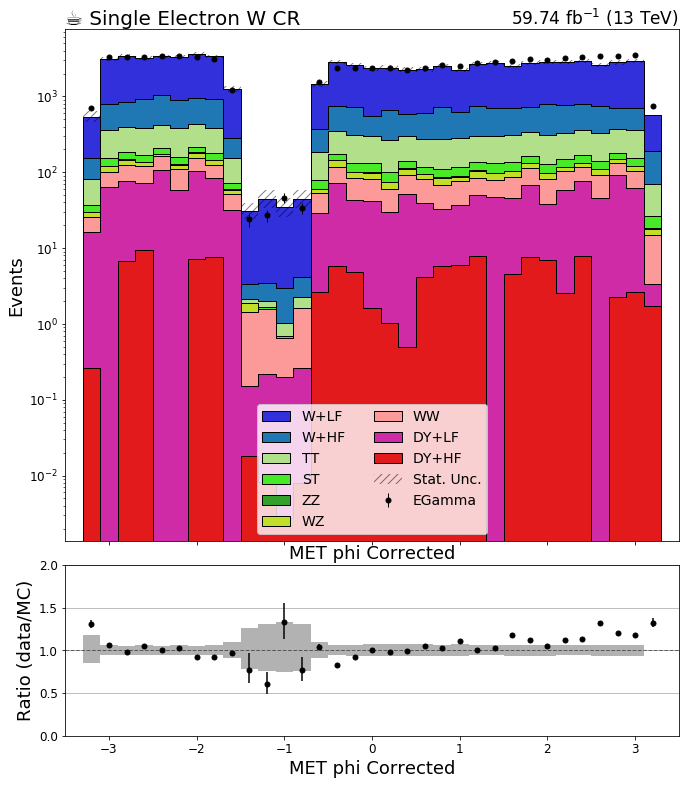

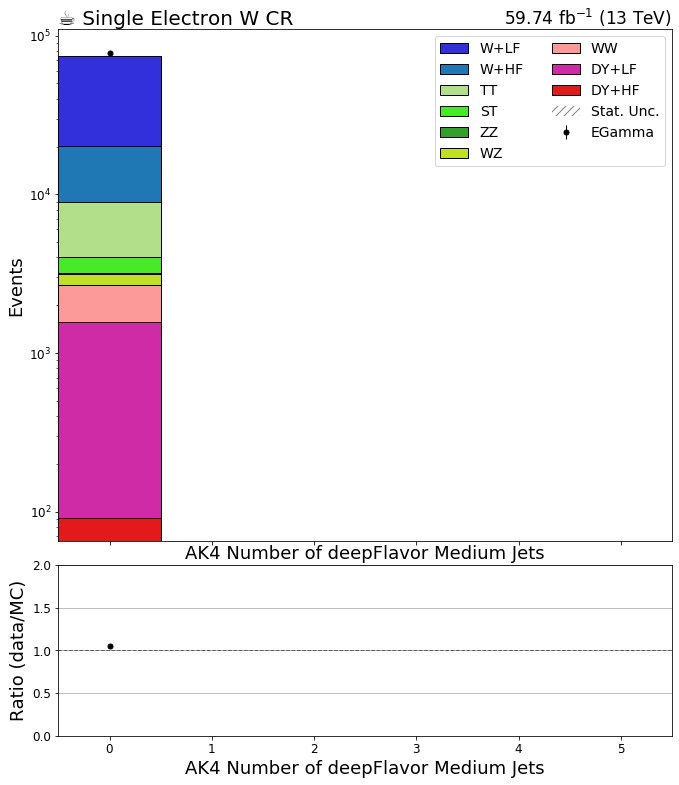

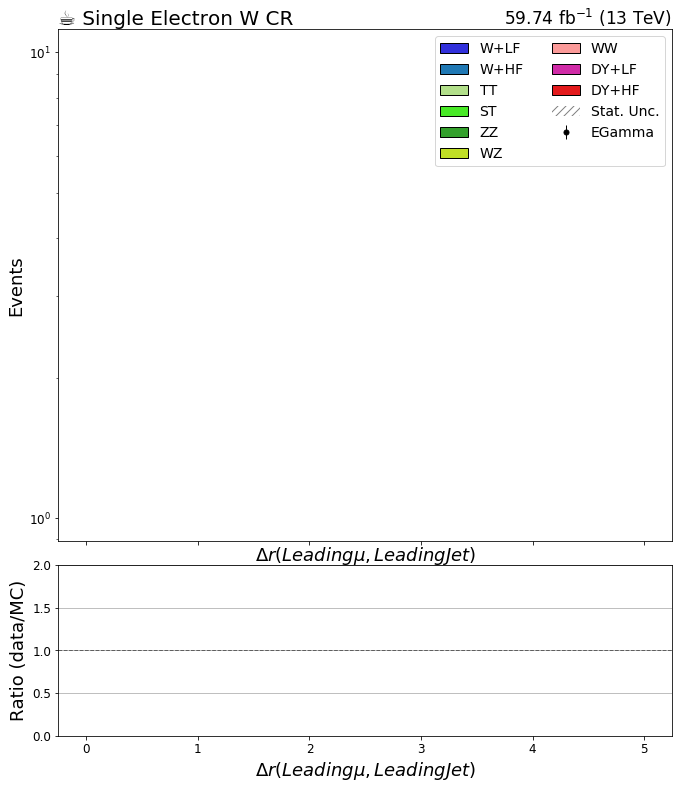

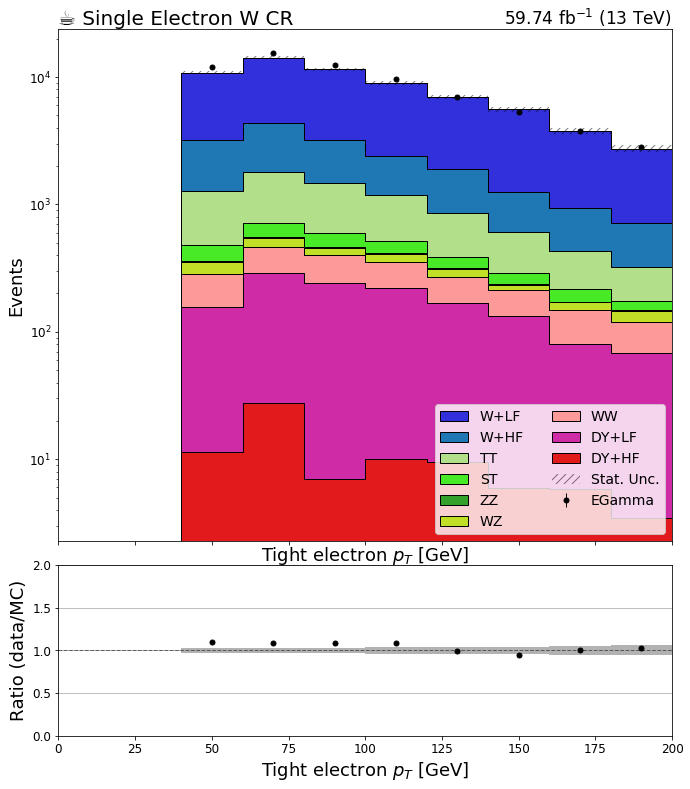

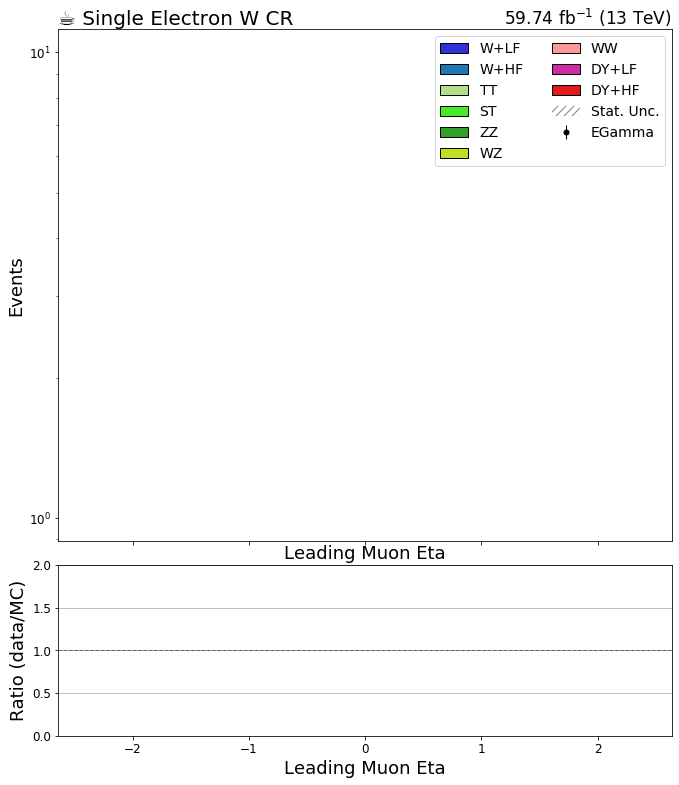

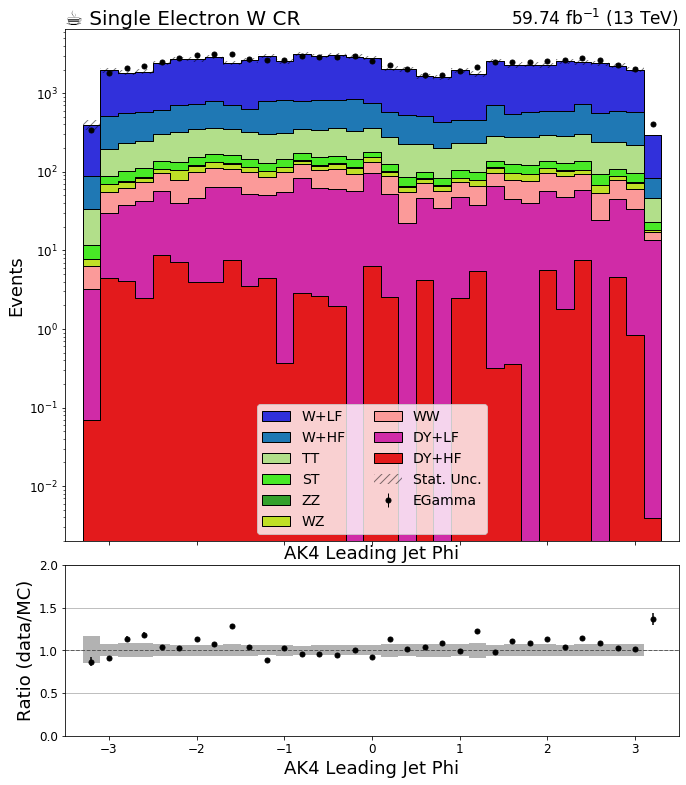

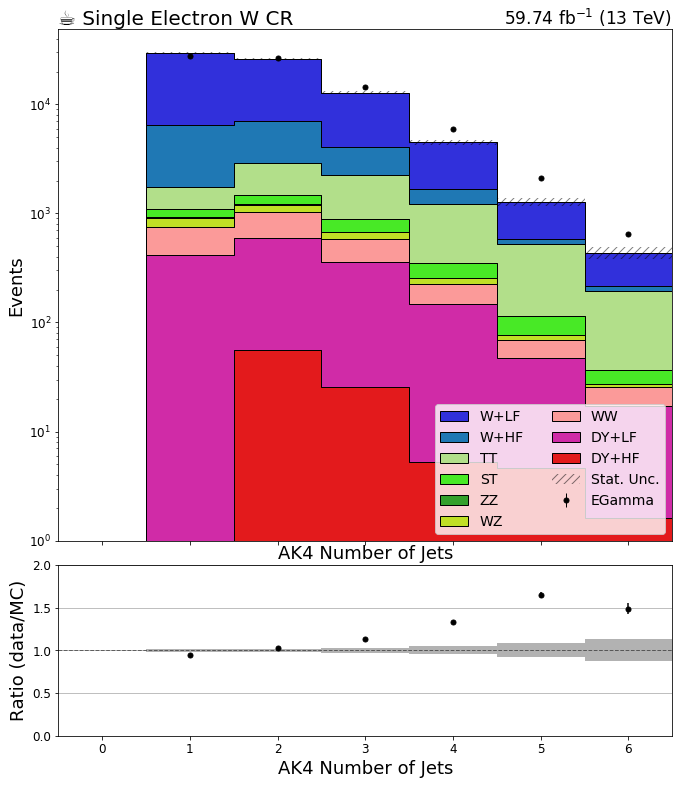

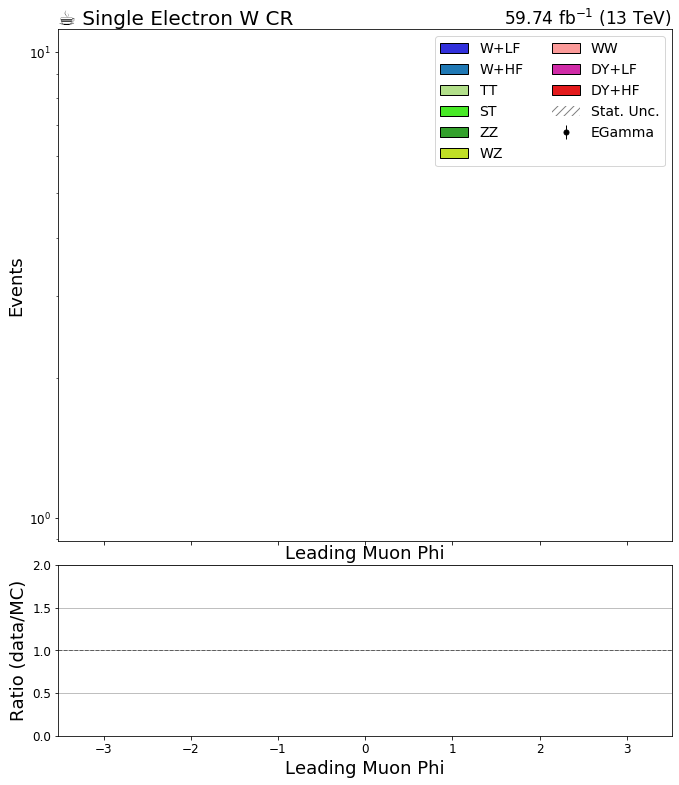

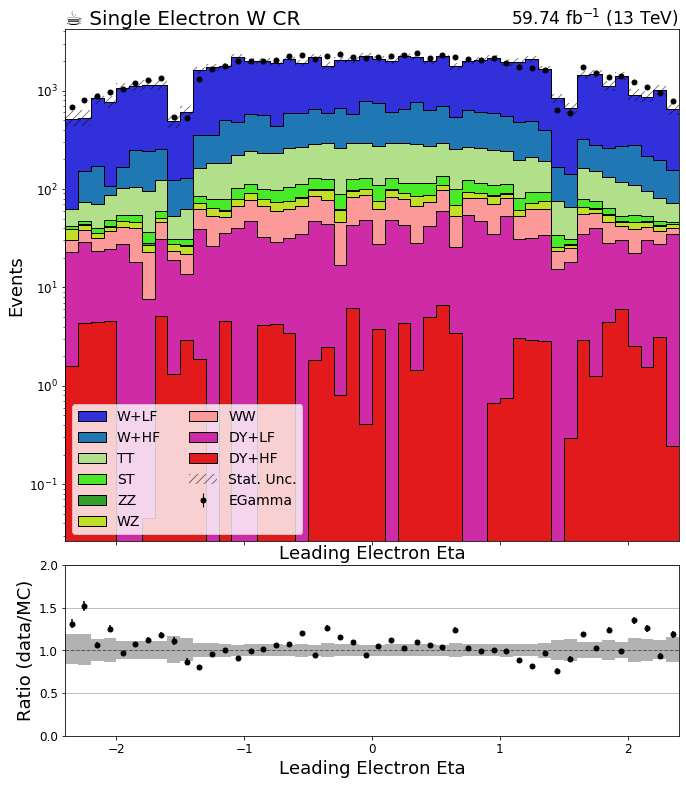

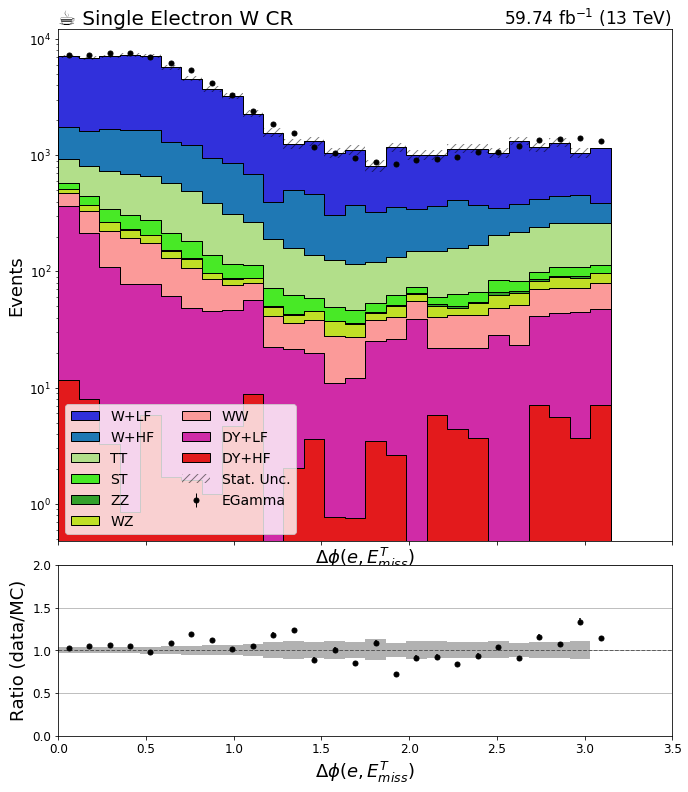

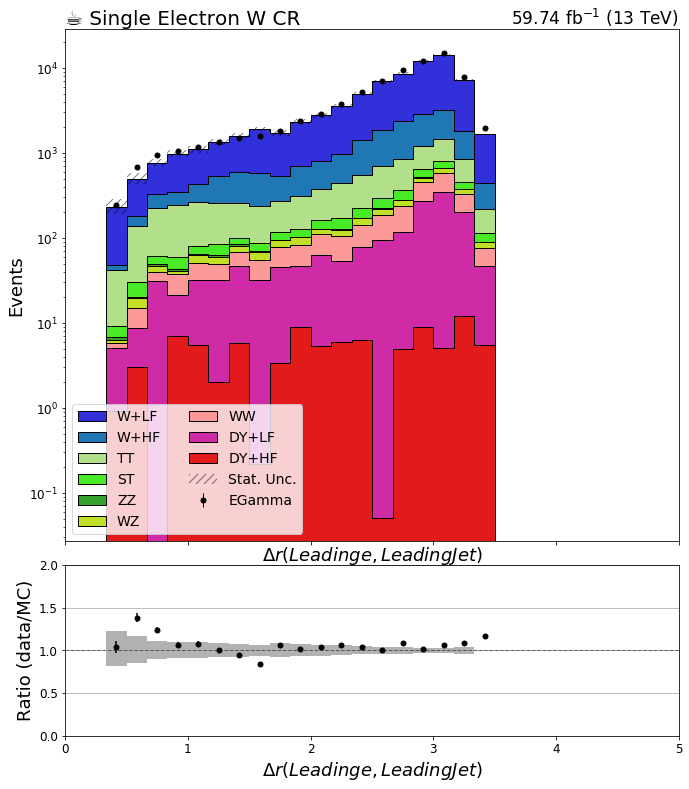

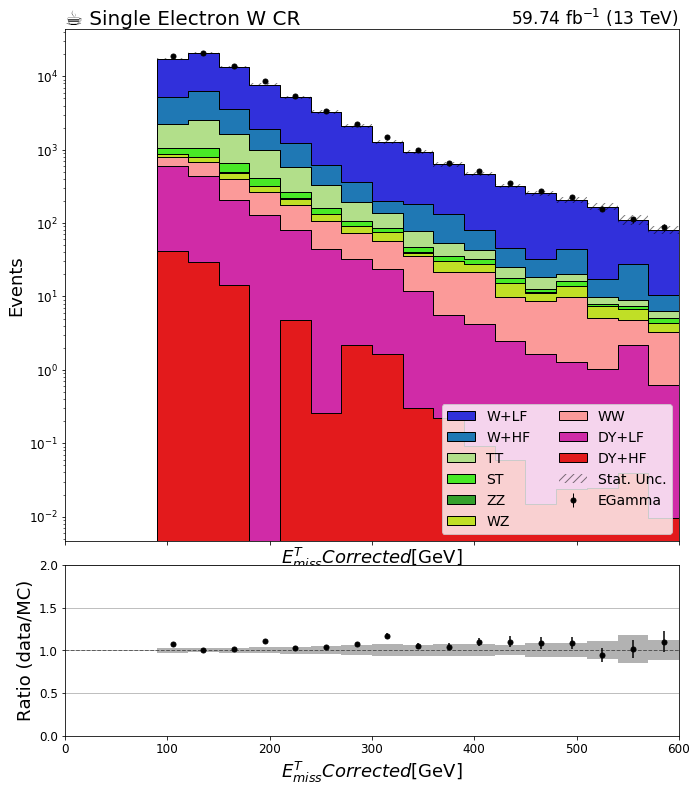

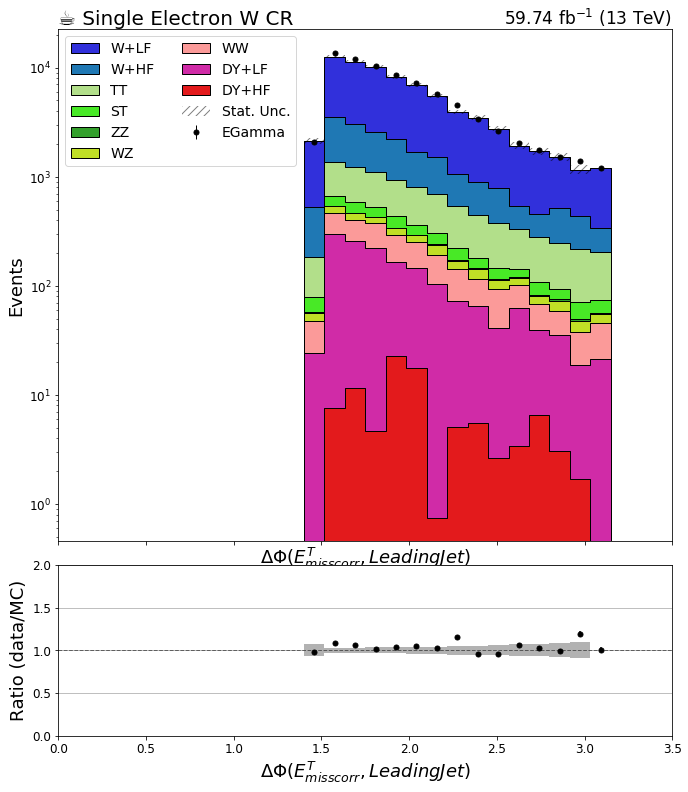

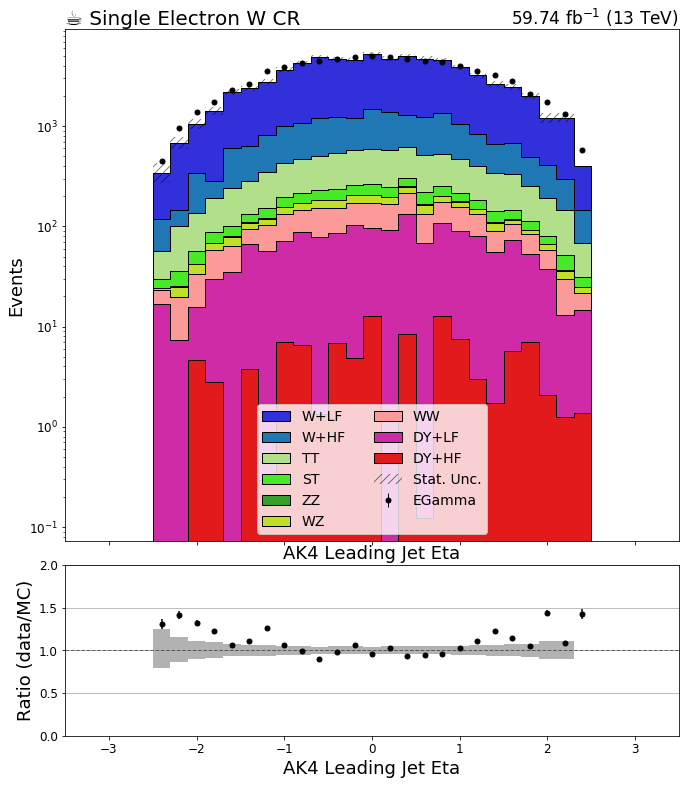

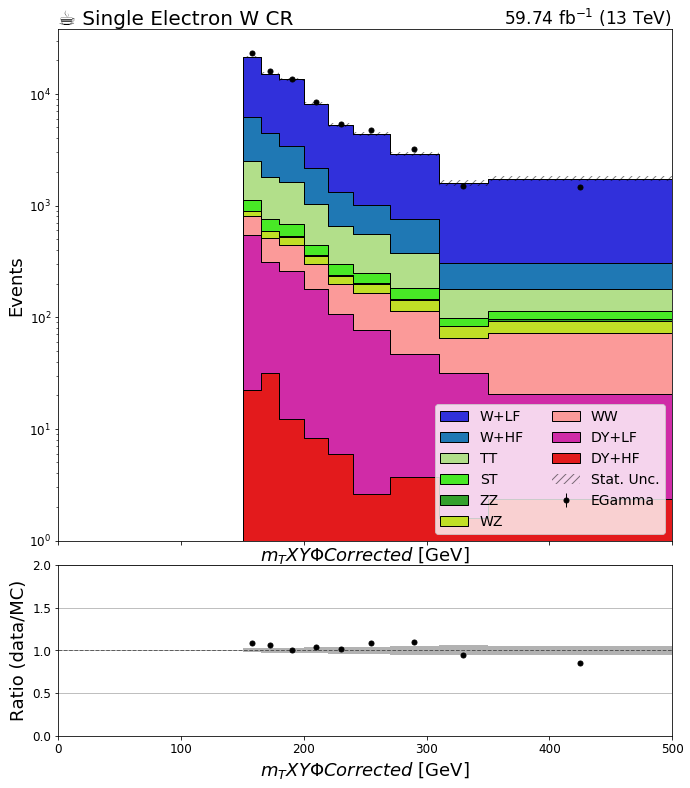

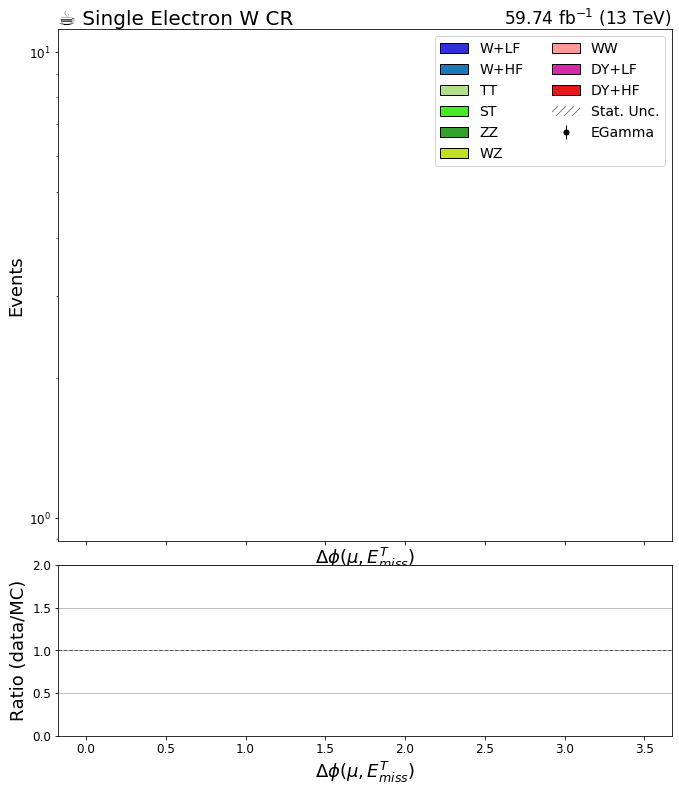

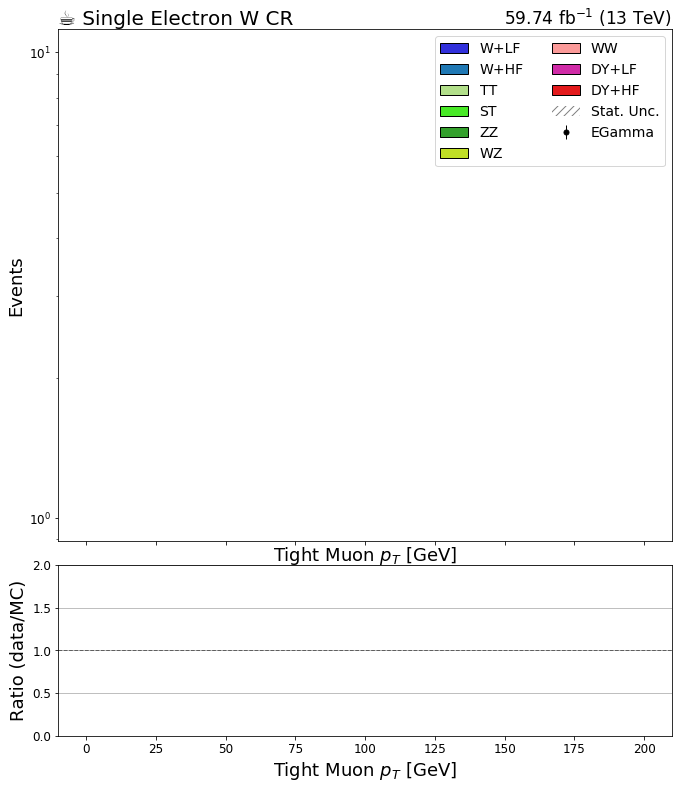

In [3]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'wjete'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi' in key: continue
#     if key!='mT_corrected': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region) : continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']
# '#a6cee3'

        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('systematic','nominal').integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
#                     overflow='all',
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('systematic','nominal').integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
#                     overflow='all',
                fill_opts=fill_opts,
                error_opts=error_opts
                   )

        plot.plotratio(data_hists[key].integrate('systematic','nominal').integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('systematic','nominal').integrate('region',j).sum('process'),
                   ax=rax,
#                    overflow='all',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
#         mphi200_Mchi50= signal_hists['template'].integrate('region','sre').integrate('systematic', 'nominal').integrate('npvs').integrate('process','Mphi-1250_Mchi-150').values()[()]
#         hep.histplot(mphi200_Mchi50*877, bins, color='cyan',label="mphi200_Mchi50* 877",ax=ax)        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.,2.)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
#         if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
#         cms = plt.text(0.05, .85, r"CMS", fontsize=25, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes, color='black', backgroundcolor='yellow')
#         wip = plt.text(0.01, .80, r"Work in Progress", fontsize=15, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes, color='black', backgroundcolor='yellow')
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

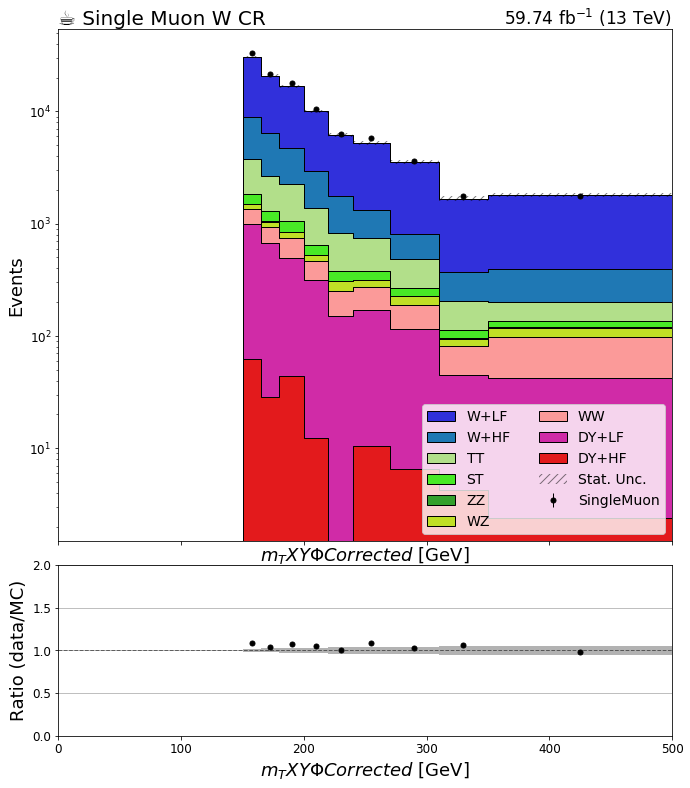

In [4]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'wjetm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    if key!='mT_corrected': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j).integrate('systematic', 'nominal')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('systematic', 'nominal').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

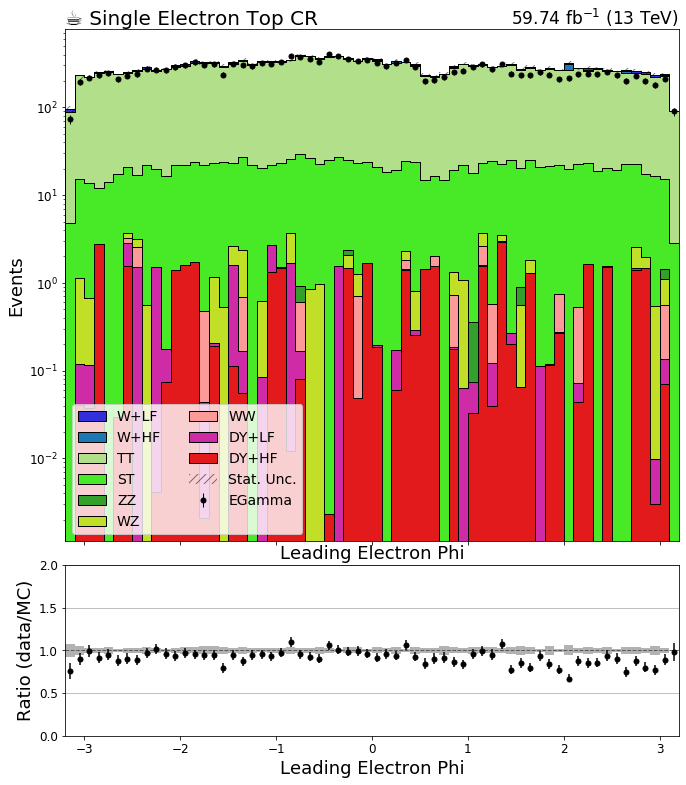

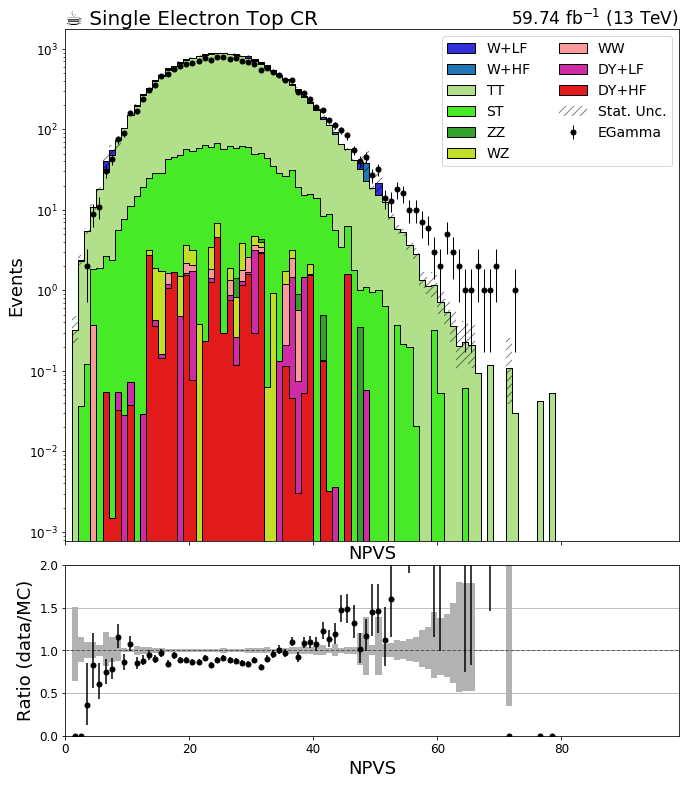

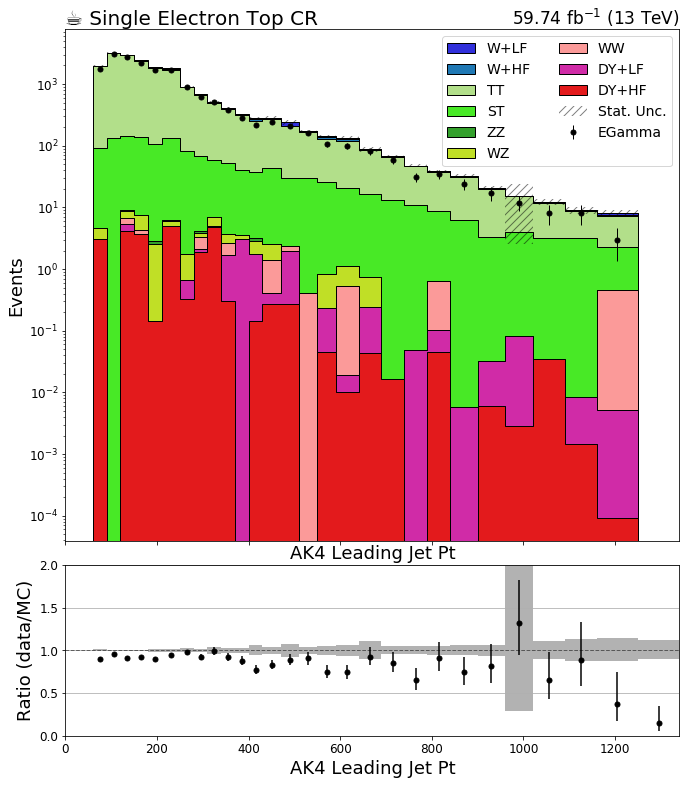

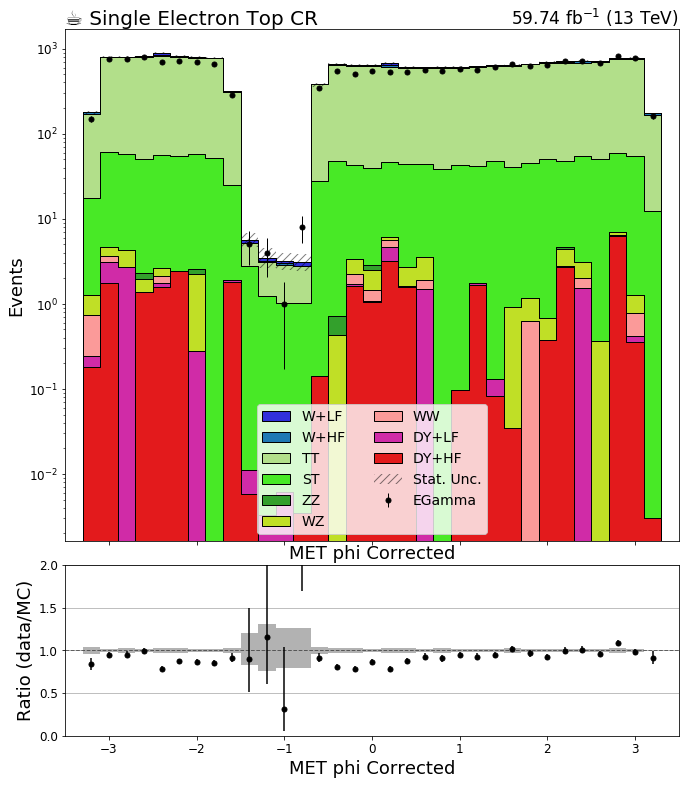

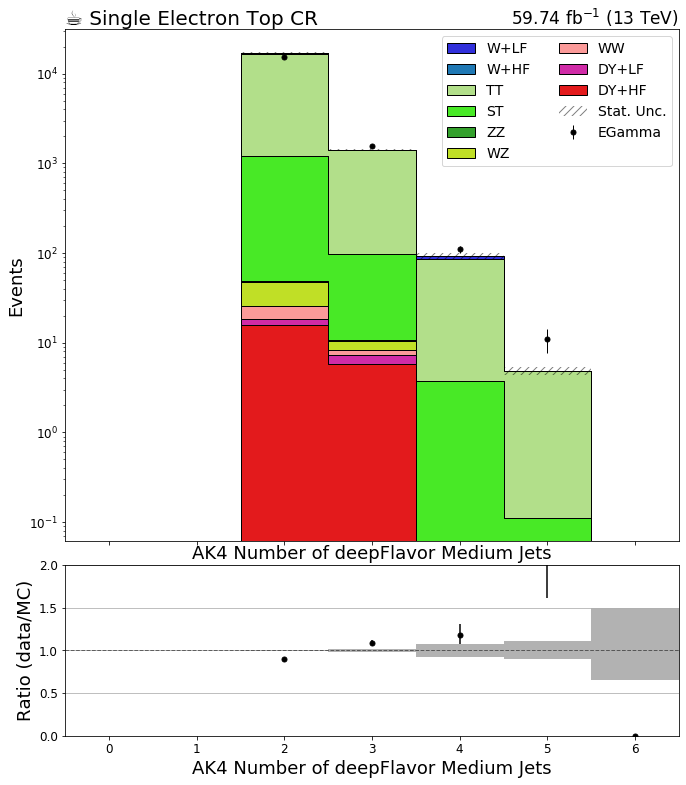

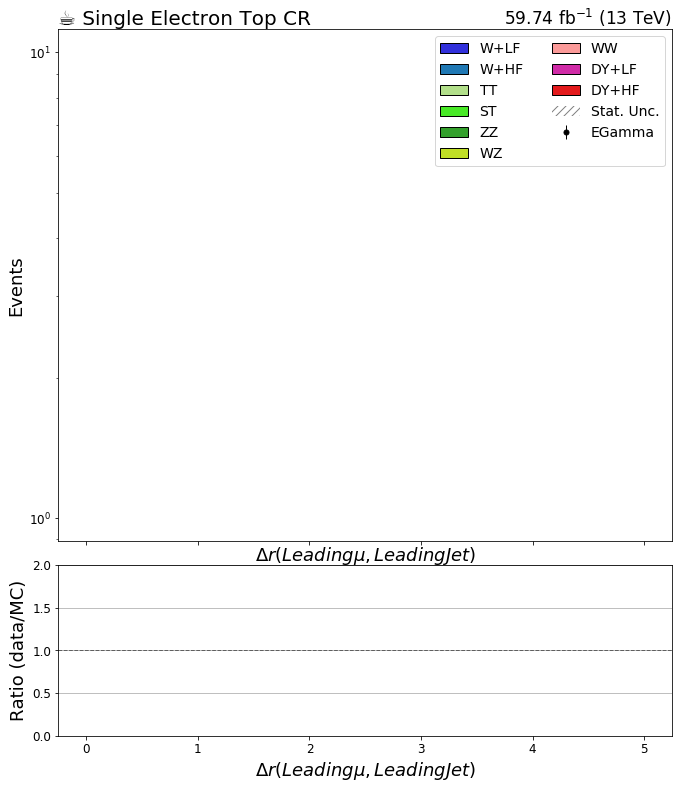

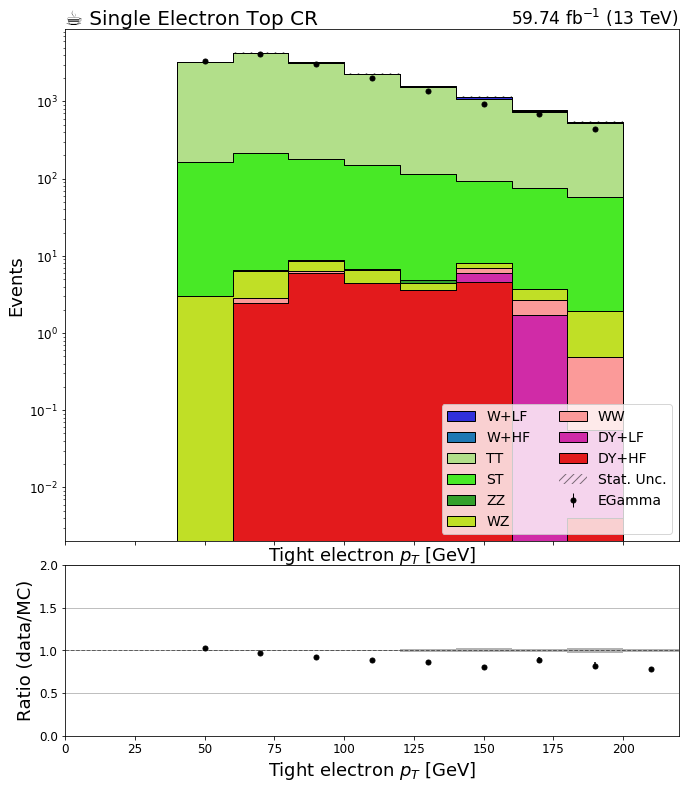

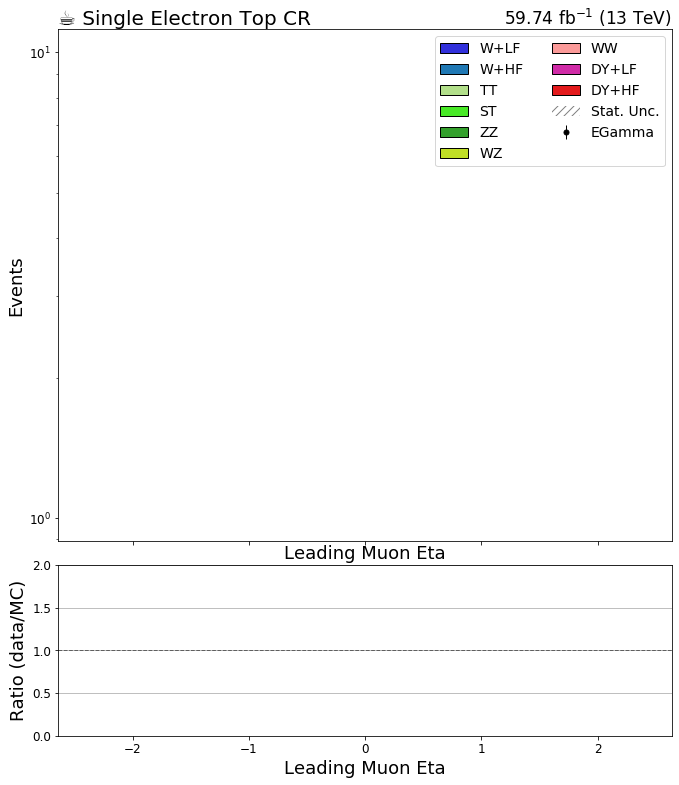

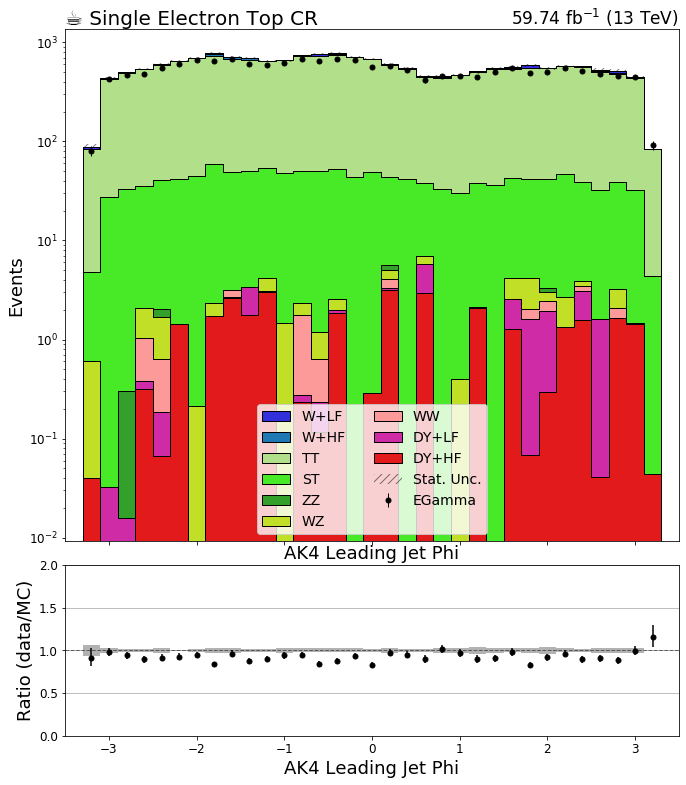

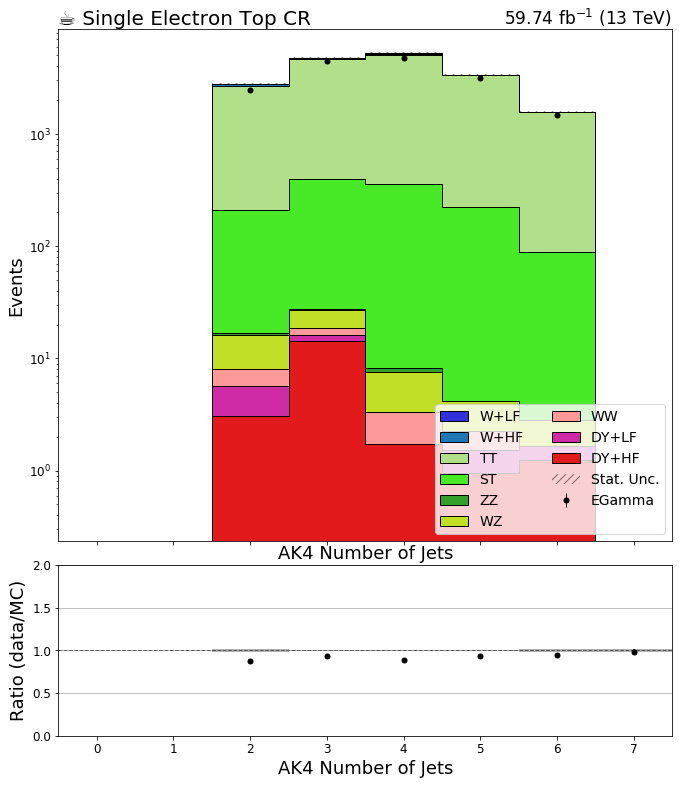

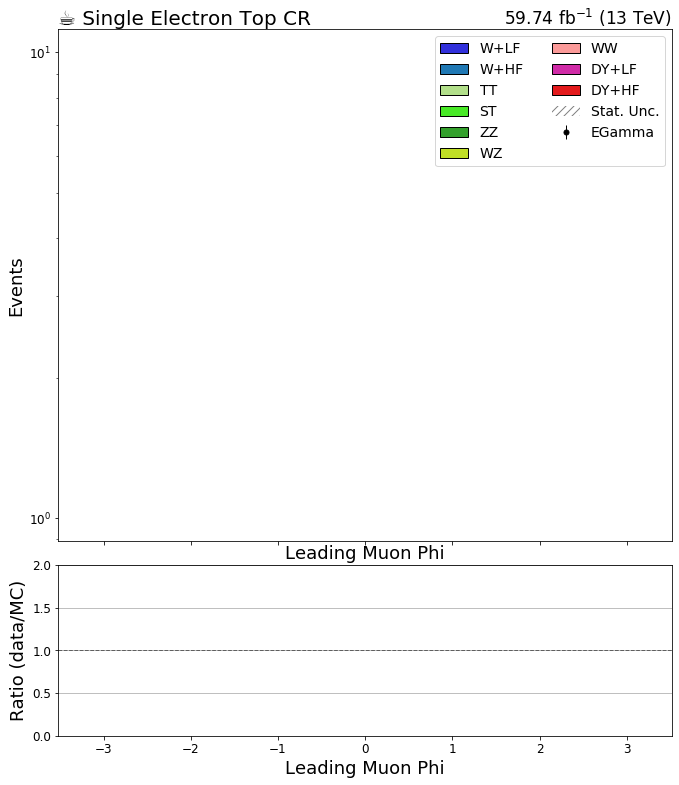

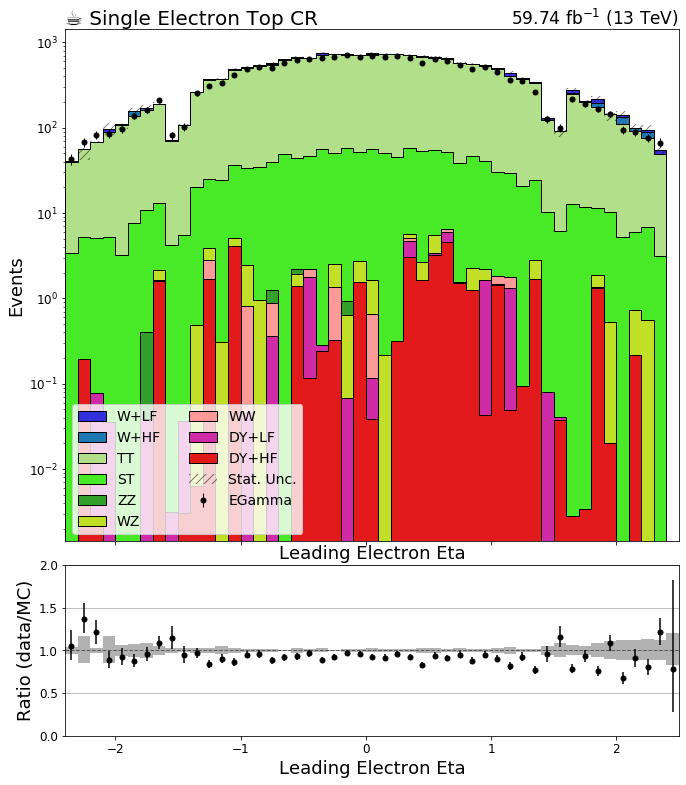

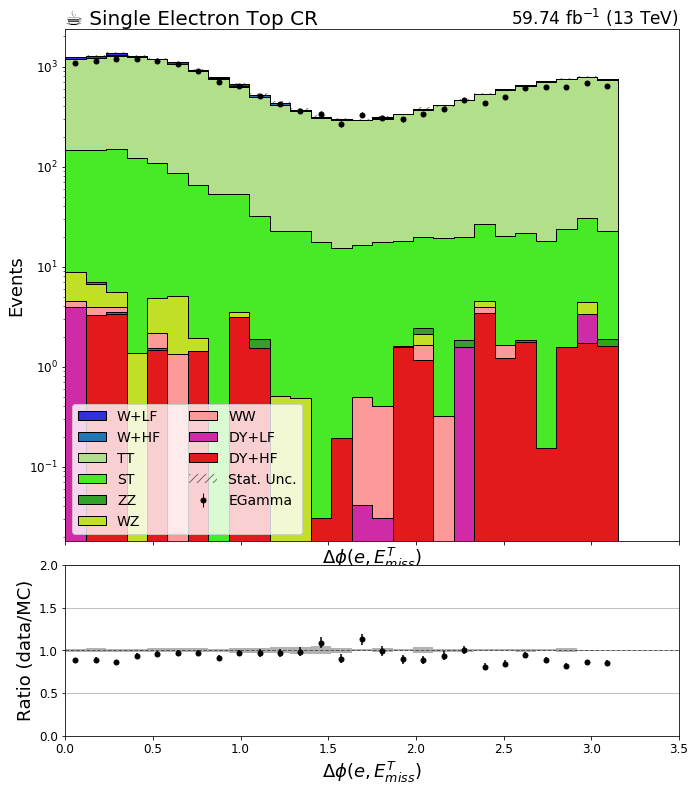

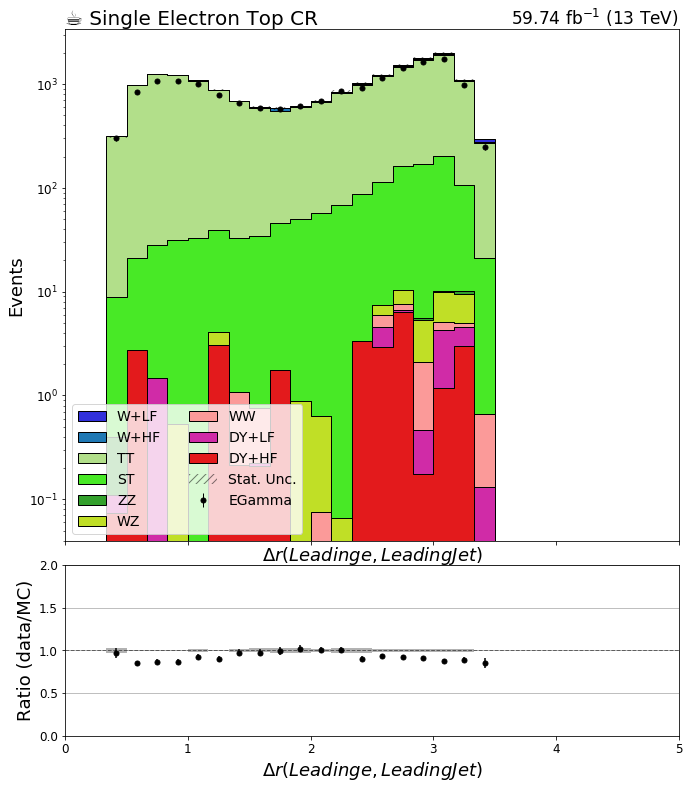

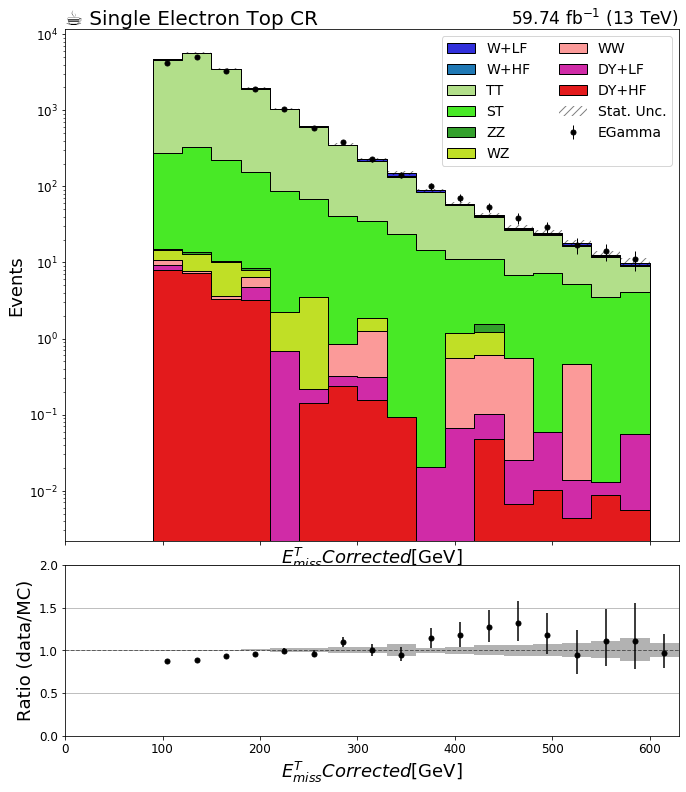

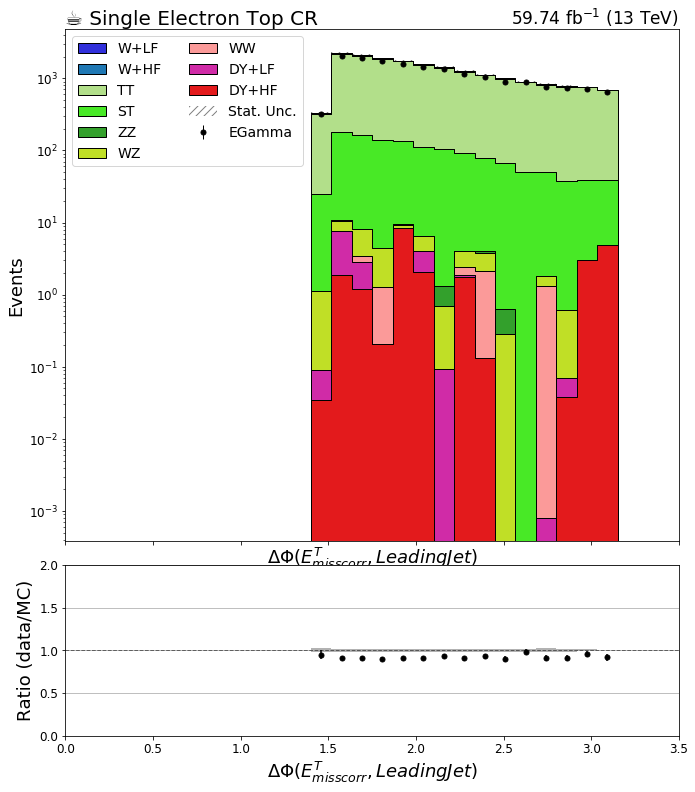

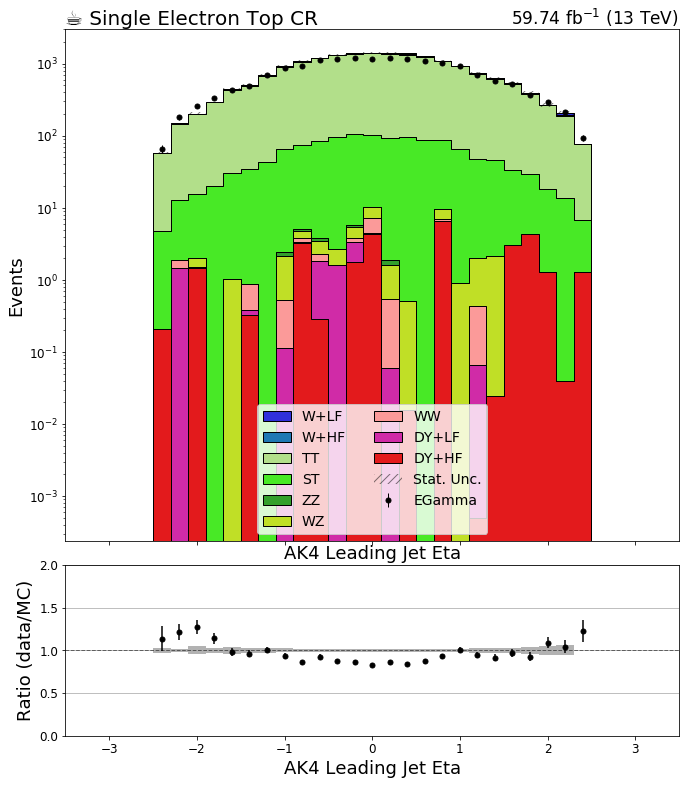

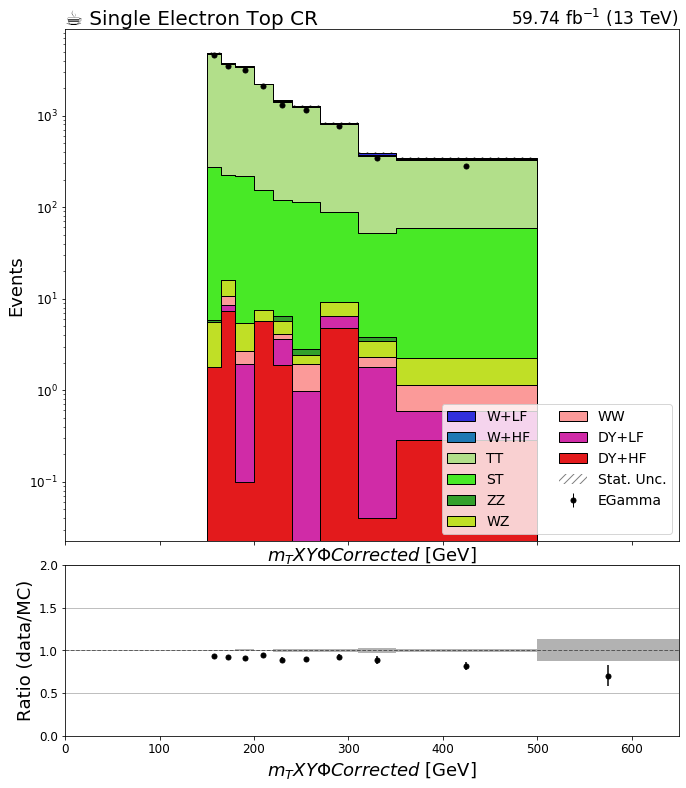

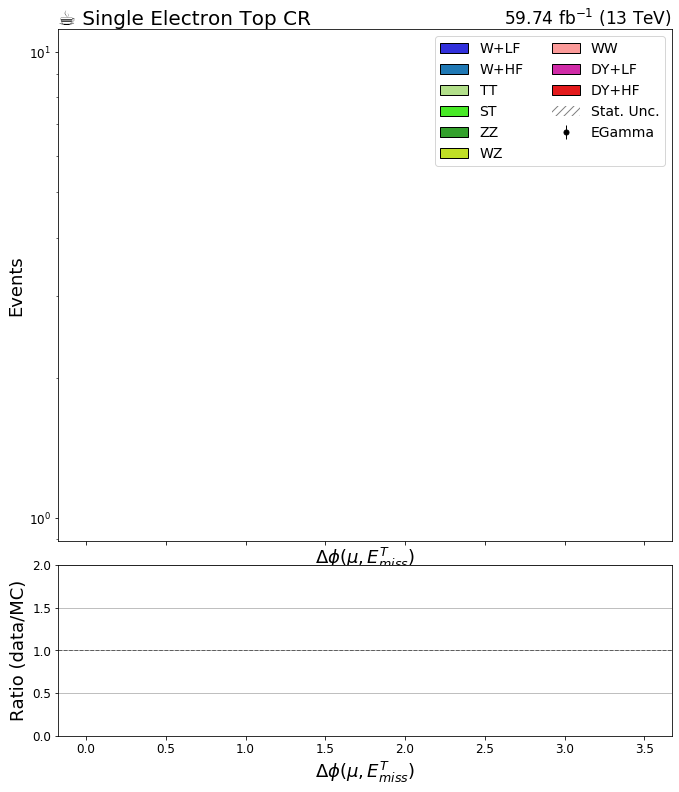

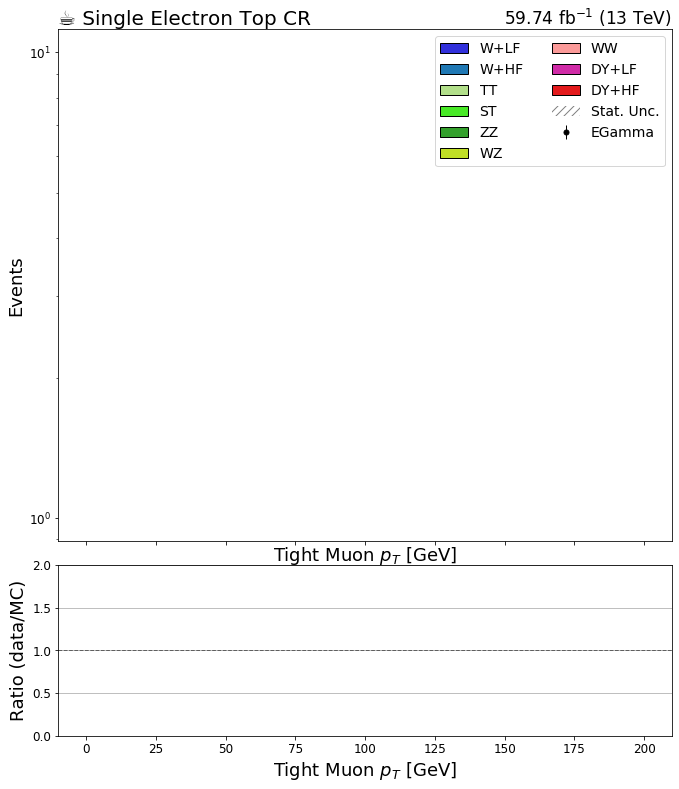

In [5]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'ttbare'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if key!='mT_corrected': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j).integrate('systematic', 'nominal')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('systematic', 'nominal').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal').sum('process'),
                   ax=rax,
                   overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

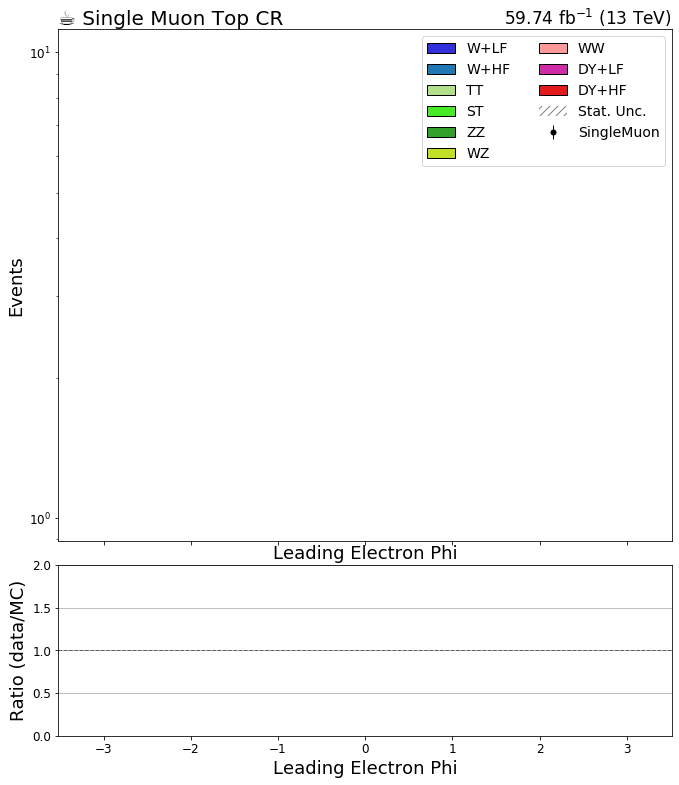

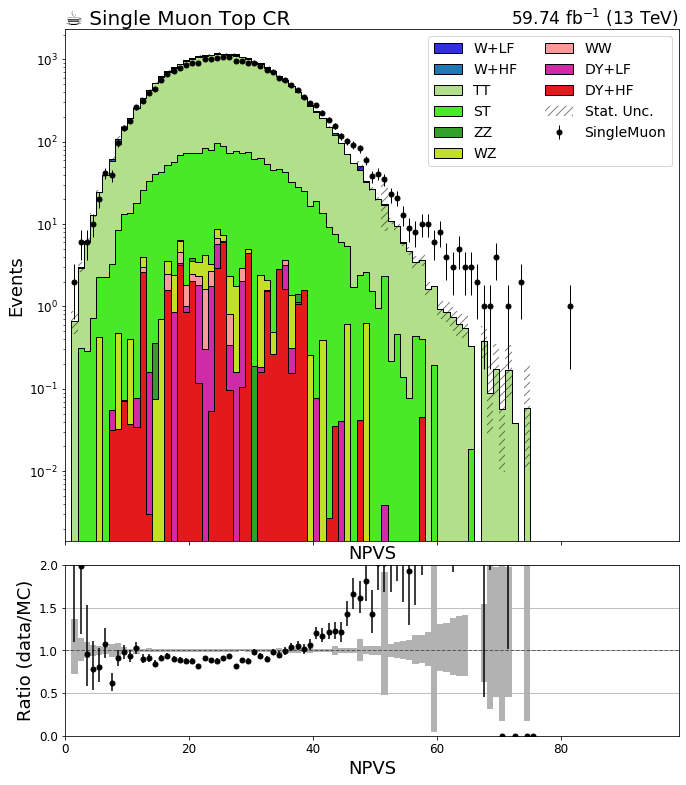

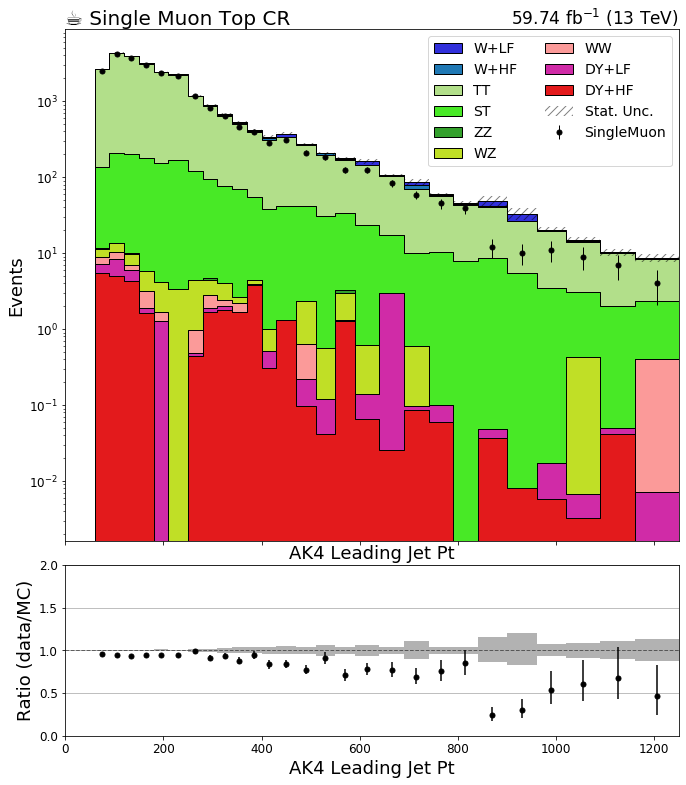

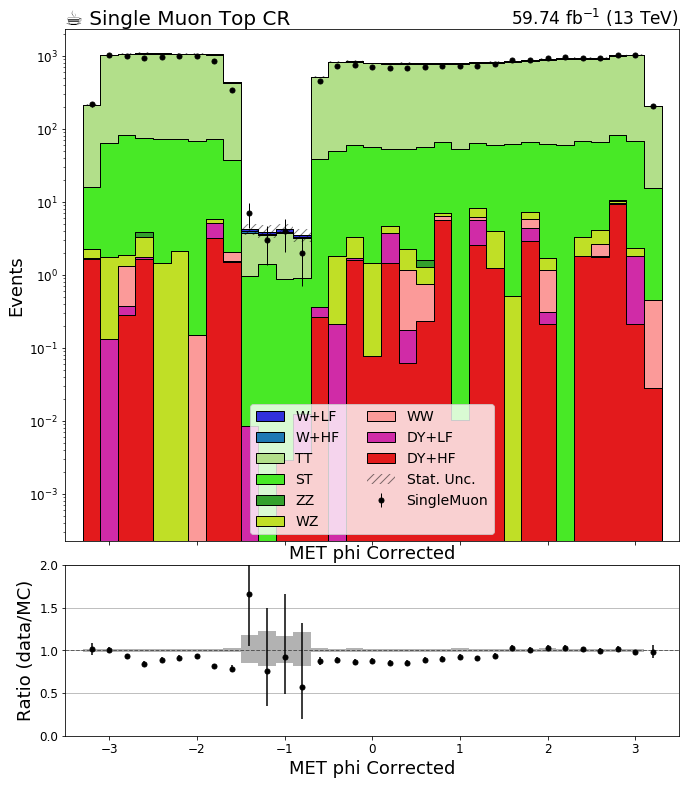

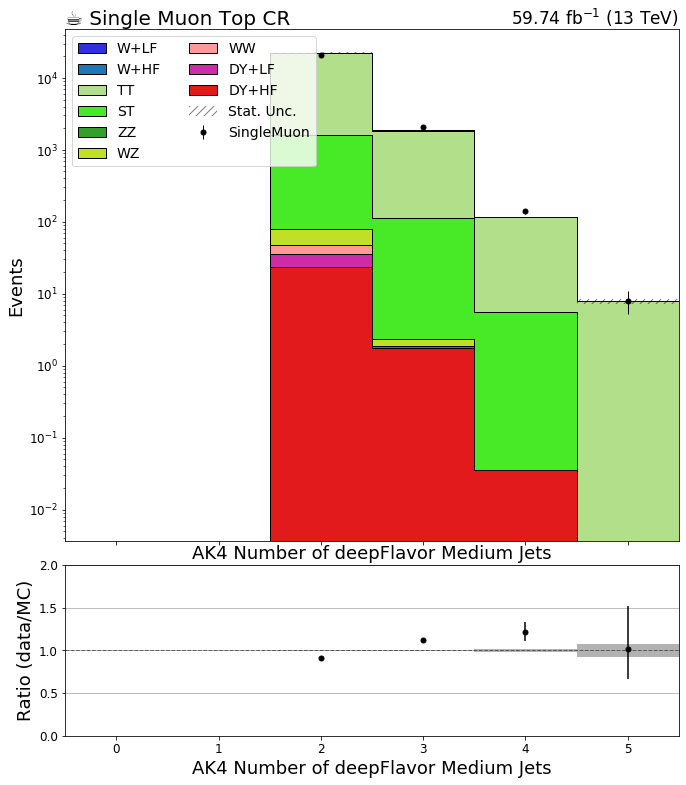

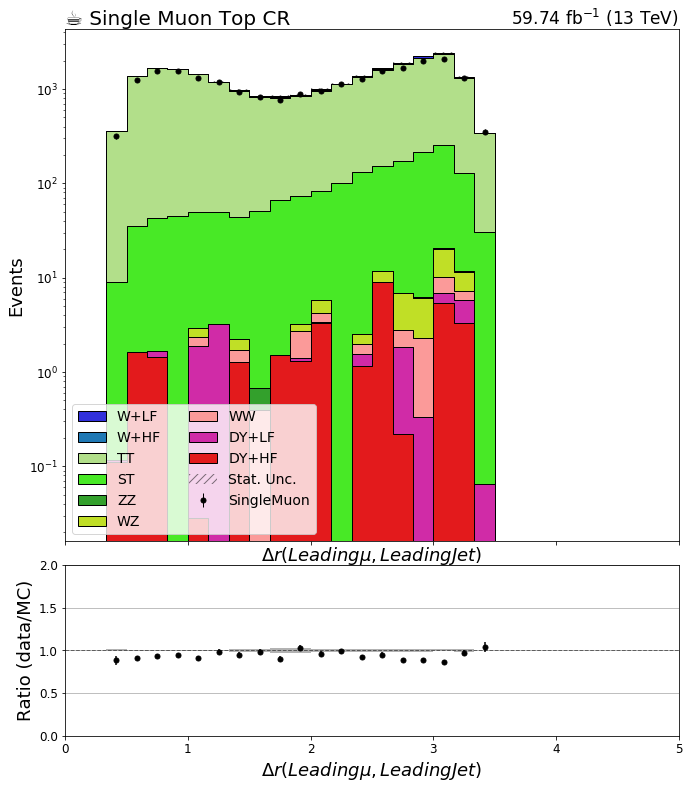

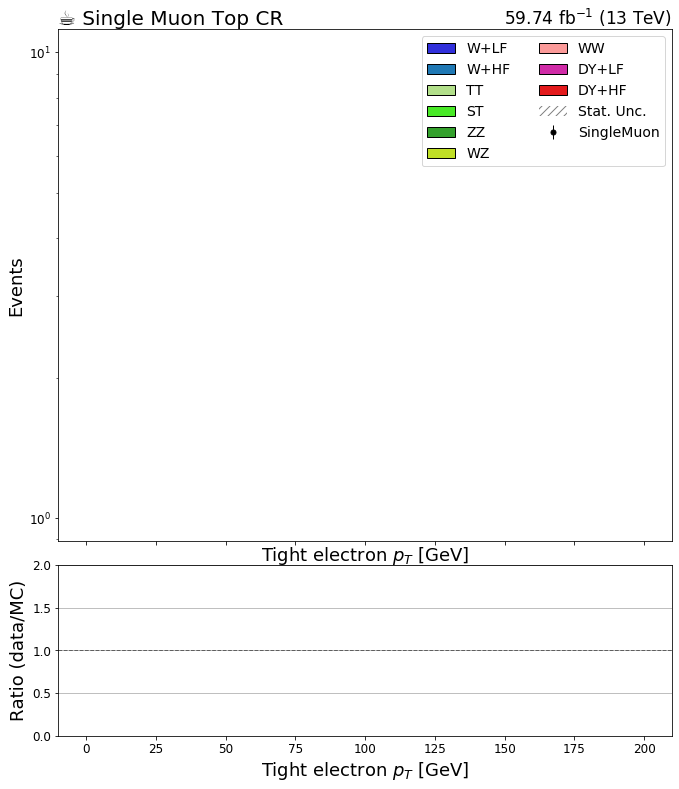

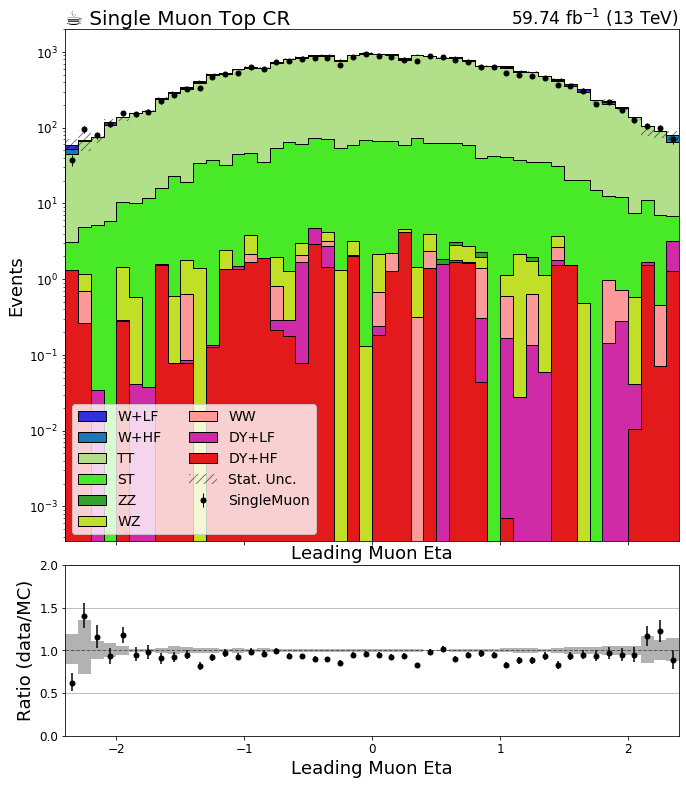

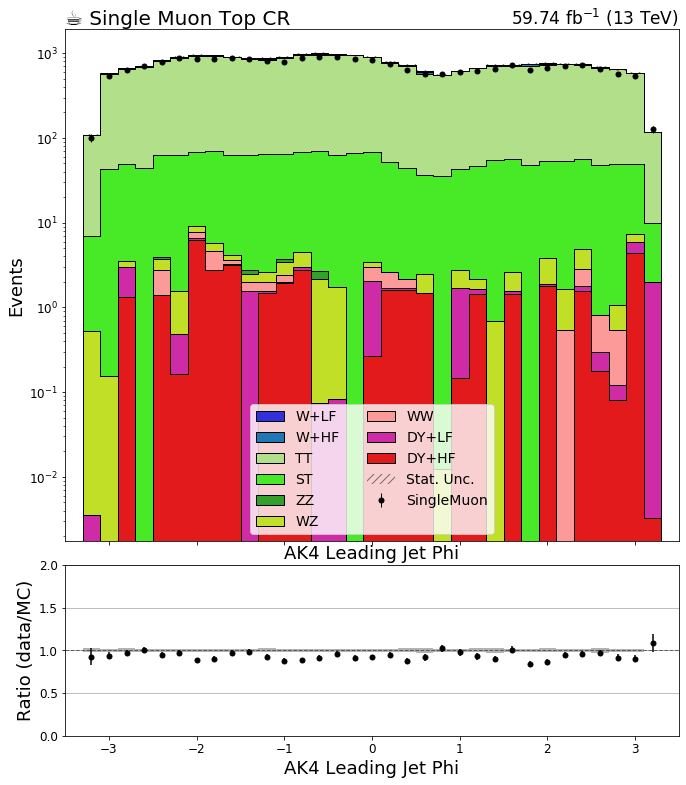

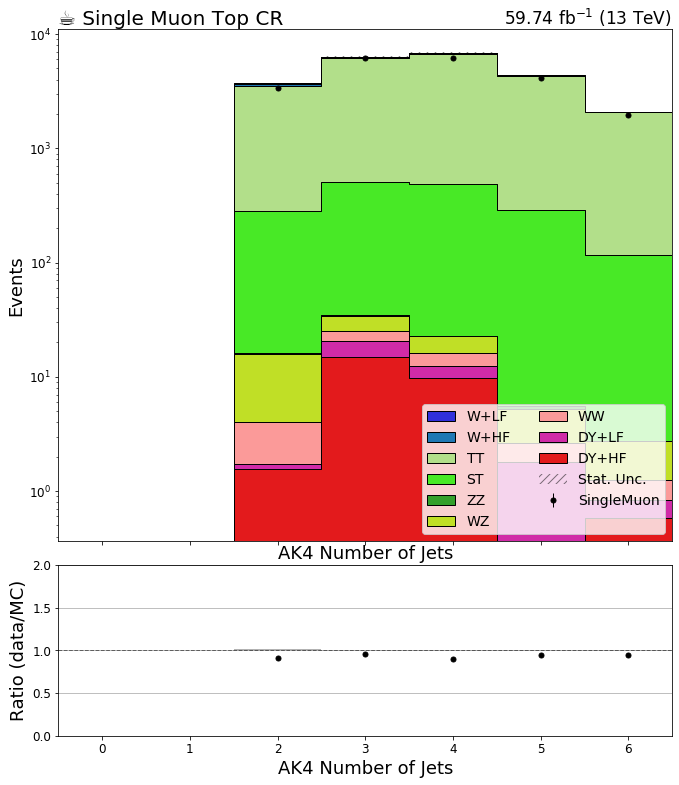

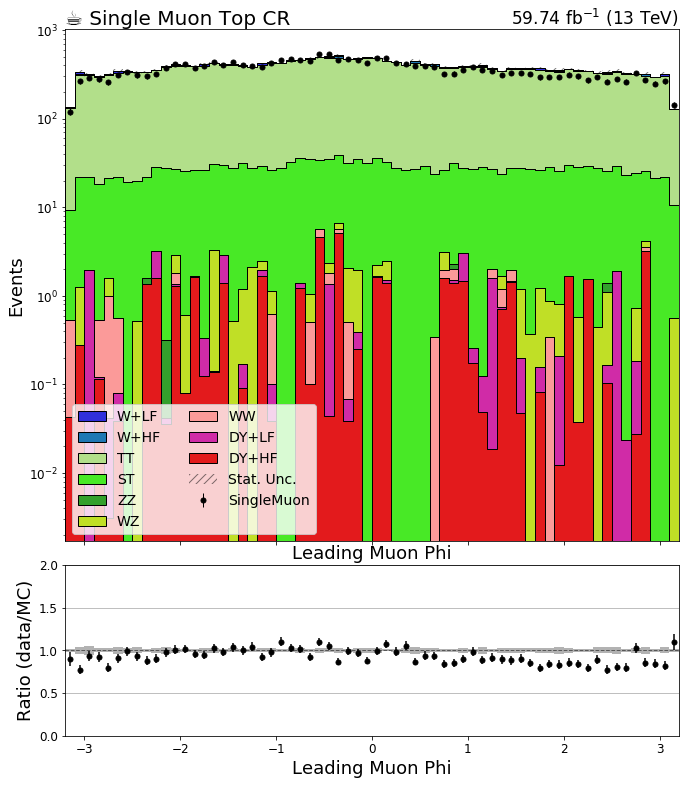

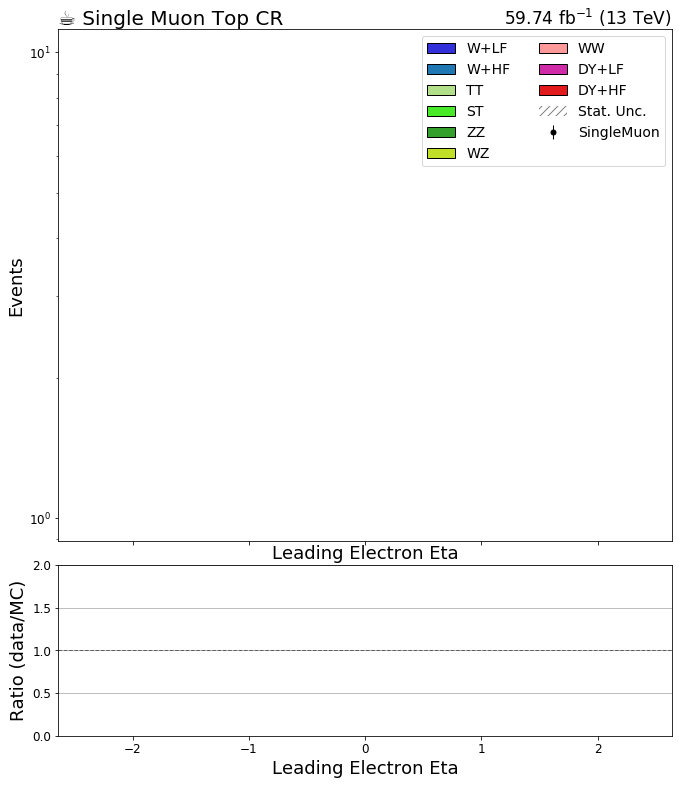

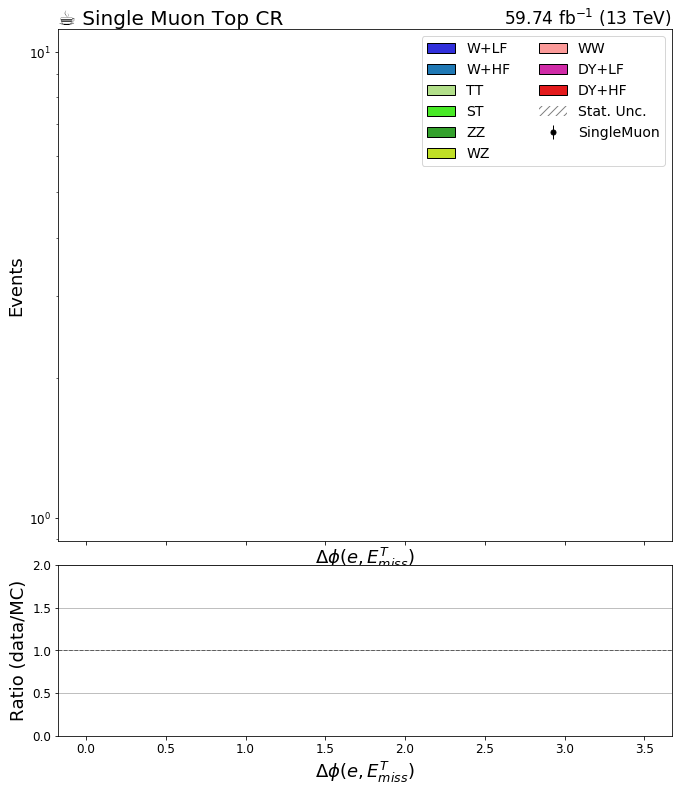

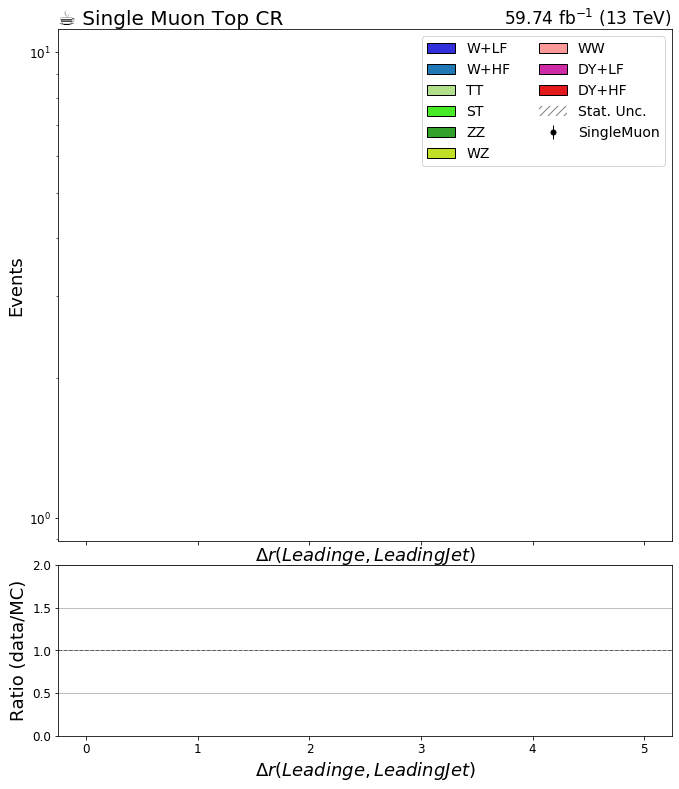

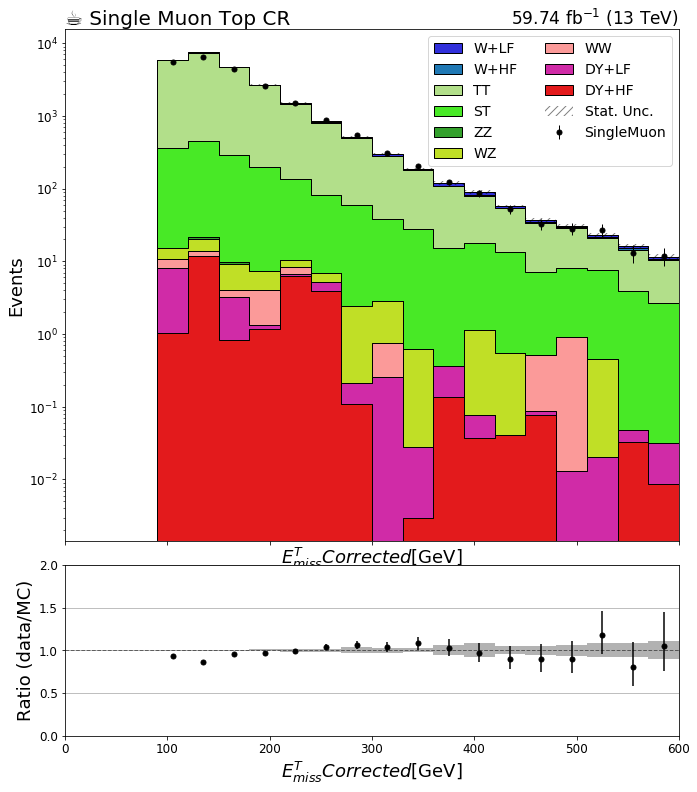

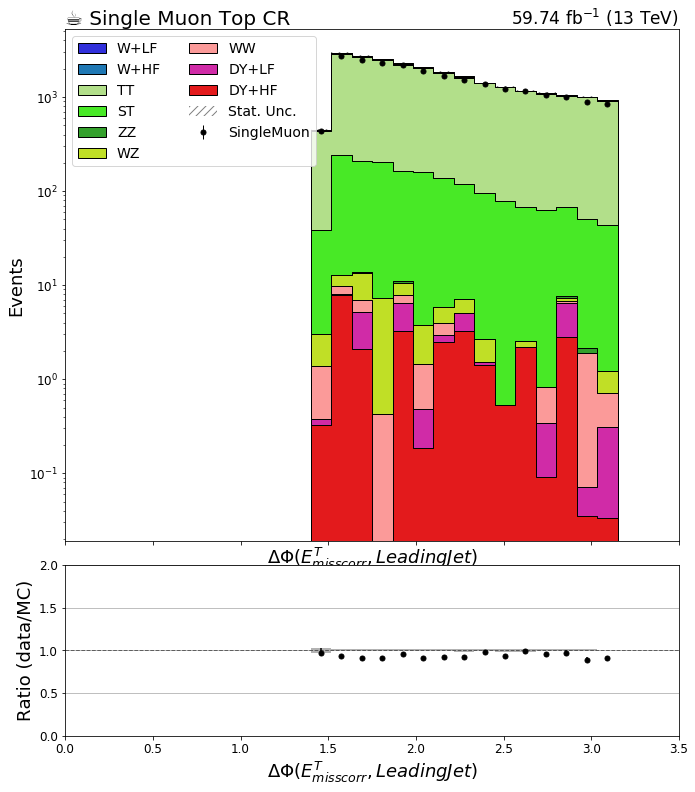

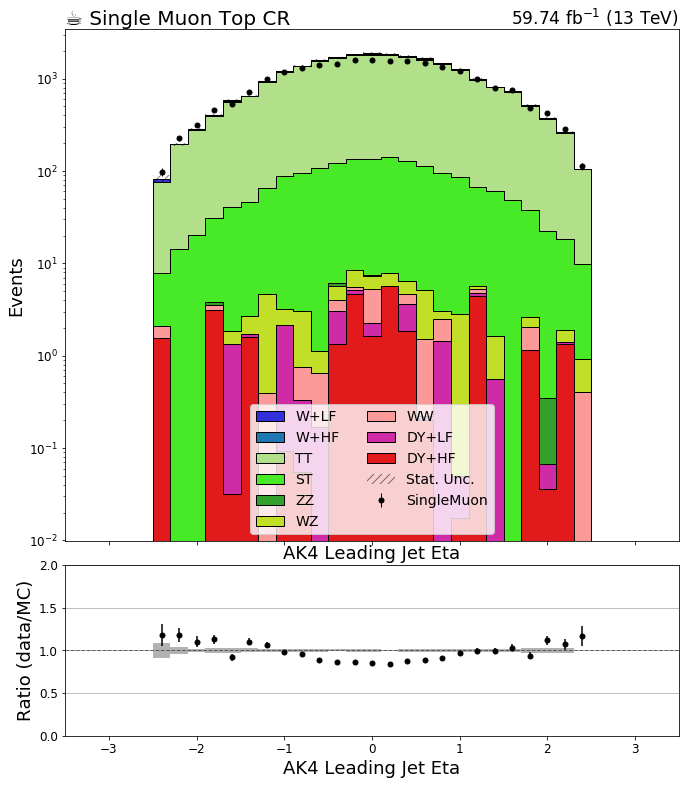

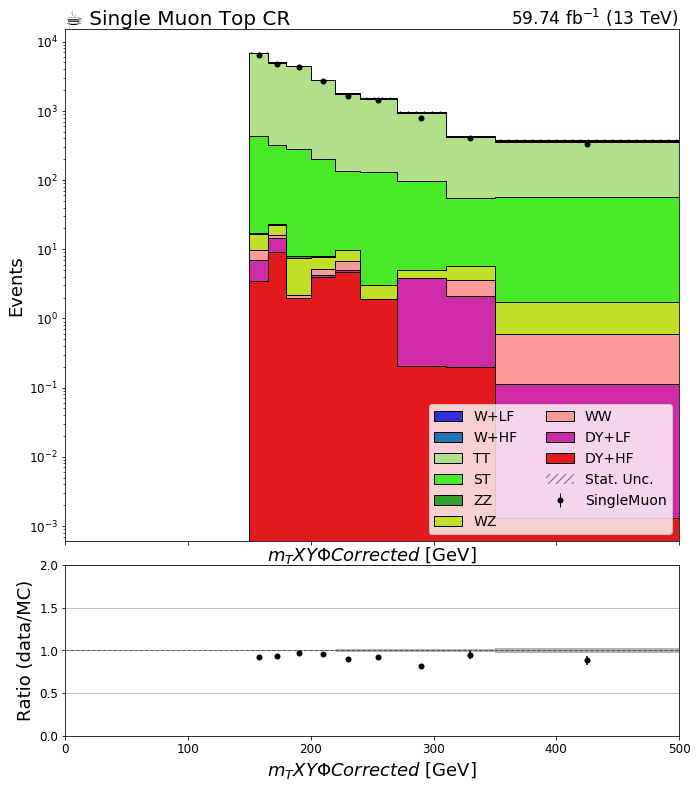

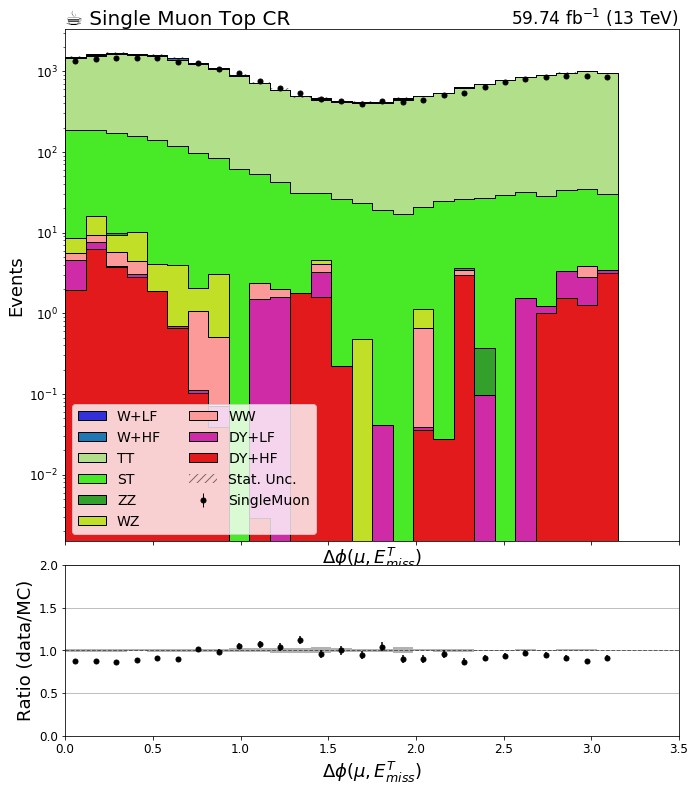

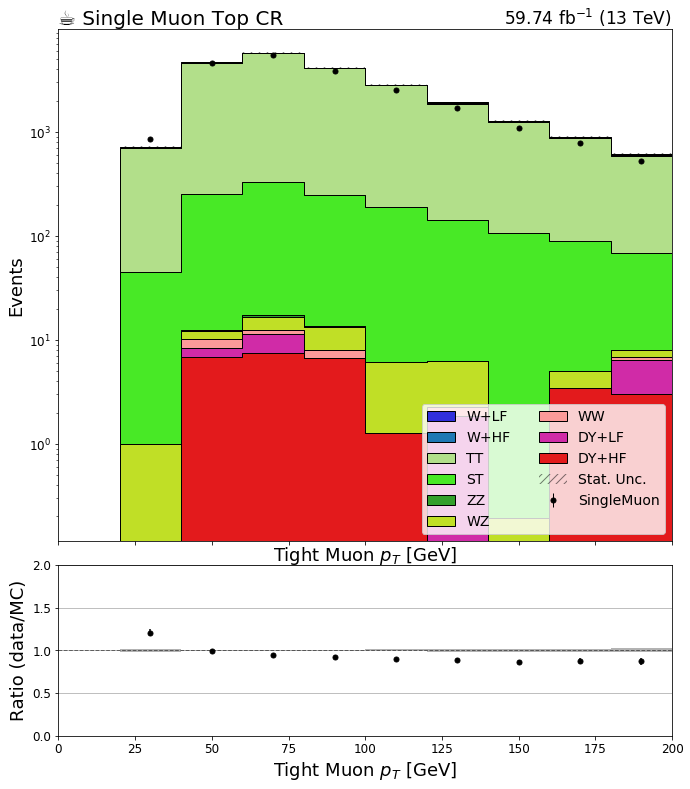

In [6]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'ttbarm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j).integrate('systematic', 'nominal')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('systematic', 'nominal').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

ttbarm
ttbarm
ttbarm
ttbarm


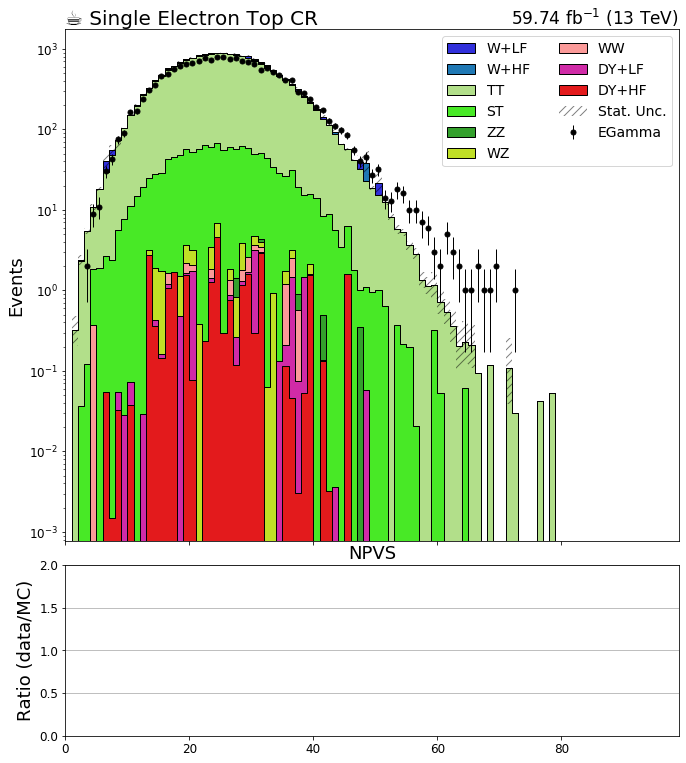

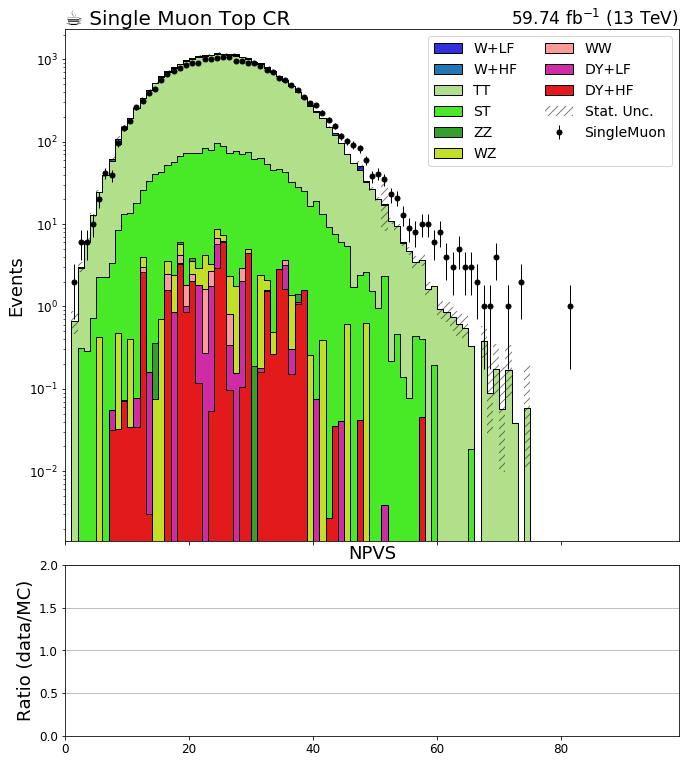

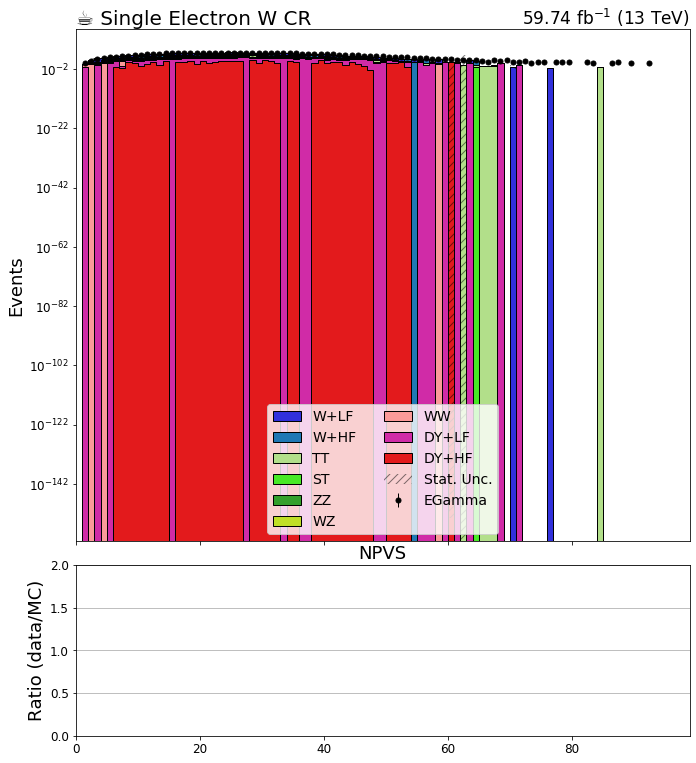

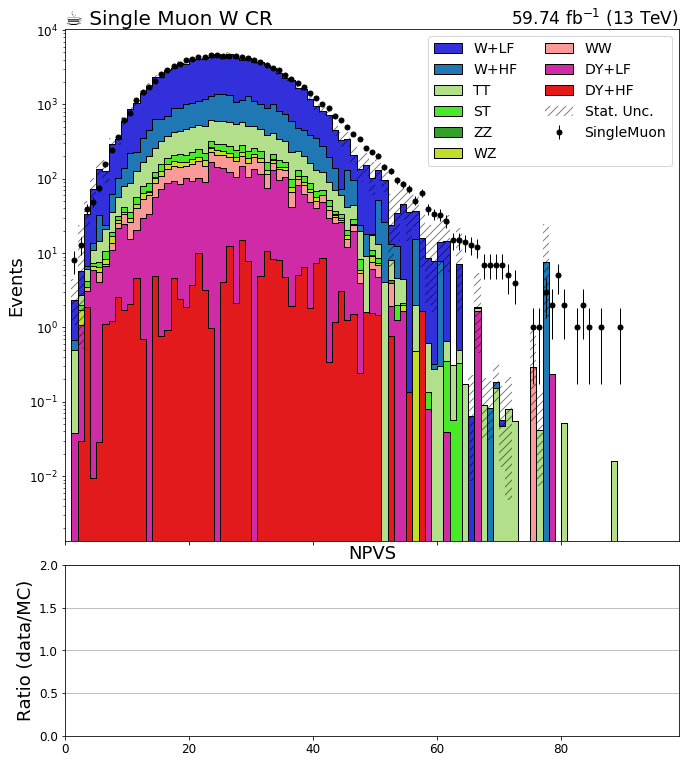

In [7]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
# region = 'ttbare'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'


for j in bkg_hists[key].identifiers('region'):
    if not (str(j) not  in ['sre', 'srm']): continue
#     legend_opts = {'W+HF':"hi"}

    plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
    fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
    error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
    nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
    data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
    #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
    colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
              '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
              '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


    fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
    fig.subplots_adjust(hspace=.07)
    ax.set_prop_cycle(cycler(color=colors))

    print(region)
    plot.plot1d(data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('mT_corrected')[data[year][str(j)]],            
            overlay="process",
            ax=ax,
            clear=False,
            error_opts=data_err_opts
               )

    plot.plot1d(bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('mT_corrected'),
            overlay="process",
            ax=ax,
            clear=False,
            stack=True,
            fill_opts=fill_opts,
#             legend_opts=legend_opts,
            error_opts=error_opts
               )

#     plot.plotratio(data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('mT_corrected').integrate('process',data[year][str(j)]), 
#                bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal').sum('process'),
#                ax=rax,
#                #overflow='over',
#                error_opts=data_err_opts,
#                denom_fill_opts={},
#                guide_opts={},
#                unc='num'
#                )

    rax.set_ylabel('Ratio (data/MC)')
    rax.set_ylim(0.0,2.0)
    rax.grid(axis='y')

    ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
    args = {'linestyle':'--', 'linewidth': 5}
    ax.autoscale(axis='x', tight=True)
    ax.set_yscale('log')
    if(key=='dilepmass'): ax.set_xlim(50, 130)
    ax.set_ylim(.1, None)
    ax.autoscale()
    leg = ax.legend(ncol=2, loc='best')

    coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
    lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
#     os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
#     plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
#     plot_name = 'stack_'+key+'.png'
#     fig.savefig(os.path.join(plot_path, plot_name))

In [45]:
data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('mT_corrected').integrate('process').values()[()]

array([0.000e+00, 1.000e+00, 7.000e+00, 2.700e+01, 4.900e+01, 8.200e+01,
       1.320e+02, 2.000e+02, 3.270e+02, 4.550e+02, 5.920e+02, 9.040e+02,
       1.079e+03, 1.408e+03, 1.732e+03, 2.021e+03, 2.236e+03, 2.543e+03,
       2.732e+03, 2.999e+03, 3.195e+03, 3.276e+03, 3.421e+03, 3.543e+03,
       3.570e+03, 3.563e+03, 3.563e+03, 3.511e+03, 3.348e+03, 3.236e+03,
       3.049e+03, 2.824e+03, 2.591e+03, 2.378e+03, 2.217e+03, 1.830e+03,
       1.599e+03, 1.446e+03, 1.250e+03, 1.071e+03, 9.840e+02, 8.310e+02,
       6.660e+02, 5.890e+02, 4.840e+02, 4.010e+02, 3.240e+02, 2.930e+02,
       2.430e+02, 1.750e+02, 1.460e+02, 1.110e+02, 1.140e+02, 8.800e+01,
       6.800e+01, 6.400e+01, 5.400e+01, 3.300e+01, 3.300e+01, 2.400e+01,
       2.100e+01, 1.500e+01, 1.600e+01, 1.300e+01, 8.000e+00, 6.000e+00,
       3.000e+00, 1.100e+01, 5.000e+00, 8.000e+00, 2.000e+00, 3.000e+00,
       4.000e+00, 1.000e+00, 4.000e+00, 2.000e+00, 0.000e+00, 2.000e+00,
       2.000e+00, 3.000e+00, 0.000e+00, 0.000e+00, 

In [27]:
j = 'wjete'
bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('mT_corrected').integrate('process').values()[()]

array([ 0.00000000e+00,  3.05400782e+00,  4.06405519e+00,  2.84321795e+01,
        9.86580633e+01,  7.47302768e+01,  1.83233128e+02,  2.07453826e+02,
        3.76221970e+02,  5.08520702e+02,  6.86307001e+02,  1.08837545e+03,
        1.16695379e+03,  1.47650487e+03,  1.86426744e+03,  2.34671342e+03,
        2.76584004e+03,  2.84519084e+03,  3.17899909e+03,  3.41841852e+03,
        3.62820173e+03,  3.78181687e+03,  4.13781361e+03,  4.76969880e+03,
        4.10220963e+03,  4.20112878e+03,  4.12510553e+03,  4.55604732e+03,
        3.93502420e+03,  4.84225292e+03,  3.36137646e+03,  3.53613677e+03,
        2.94548135e+03,  2.75740149e+03,  3.44145798e+03,  1.90318193e+03,
        2.33809502e+03,  1.61749955e+03,  1.32296902e+03,  1.18716534e+03,
        8.74029484e+02,  7.69779536e+02,  5.19989040e+02,  3.59827801e+02,
        3.54672855e+02,  3.55786996e+02,  2.68346872e+02,  1.75440326e+02,
        1.22533009e+02,  1.00026493e+02,  3.15259193e+01,  1.28394626e+01,
        5.56657159e+01,  

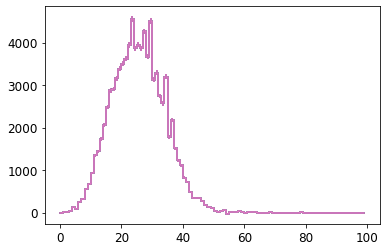

In [46]:


from coffea.hist import plot
import matplotlib.pyplot as plt

R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
for _region in bkg_hists['template'].identifiers('region'):
    if not (str(_region) not  in ['sre', 'srm']): continue
    data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('mT_corrected').integrate('process').values()[()]
    down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'pileupDown').integrate('mT_corrected').integrate('process').values()[()]
    nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('mT_corrected').integrate('process').values()[()]
    up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'pileupUp').integrate('mT_corrected').integrate('process').values()[()]
    
    hep.histplot(up, bins, yerr=True,
    label="up")

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ROOT)

j = 'wjete'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","pileupDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'pileupDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'pileupUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="Egamma")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2018 "+j)

KeyError: ()

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ROOT)

j = 'wjete'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","FSRDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process', "W+jets").values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'FSRDown').integrate('npvs').integrate('process',"W+jets").values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process',"W+jets").values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'FSRUp').integrate('npvs').integrate('process',"W+jets").values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="SingleMuon")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]$")
ax.set_title("2018 "+j)

KeyError: ()

In [14]:

print(systematics)

['FSR', 'ISR', 'L1Prefiring', 'PDF', 'btag', 'ew1', 'ew2G', 'ew2W', 'ew2Z', 'ew3G', 'ew3W', 'ew3Z', 'id_e', 'id_m', 'isolation_e', 'isolation_m', 'mix', 'muF', 'muR', 'pileup', 'qcd1', 'qcd2', 'qcd3', 'reco_e', 'reco_m', 'trig_e', 'trig_m']


Text(0.5, 1.0, '2018 ttbarm')

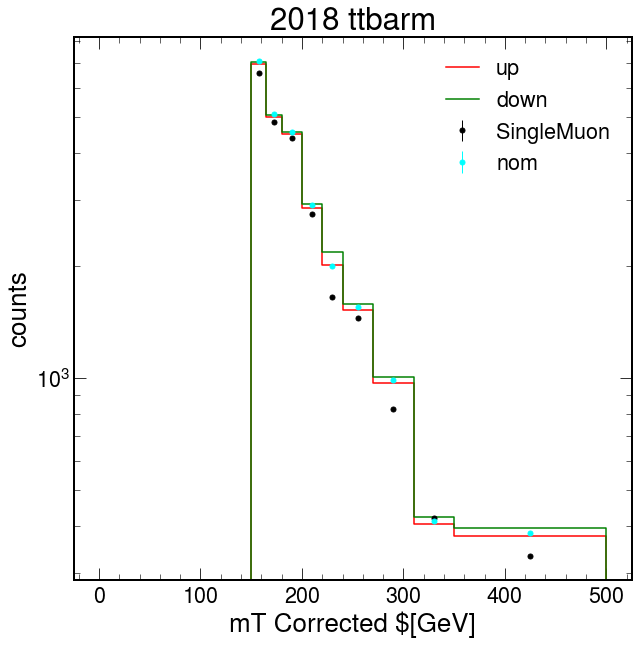

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ROOT)

j = 'ttbarm'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","pileupDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'pileupDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'pileupUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="SingleMuon")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2018 "+j)

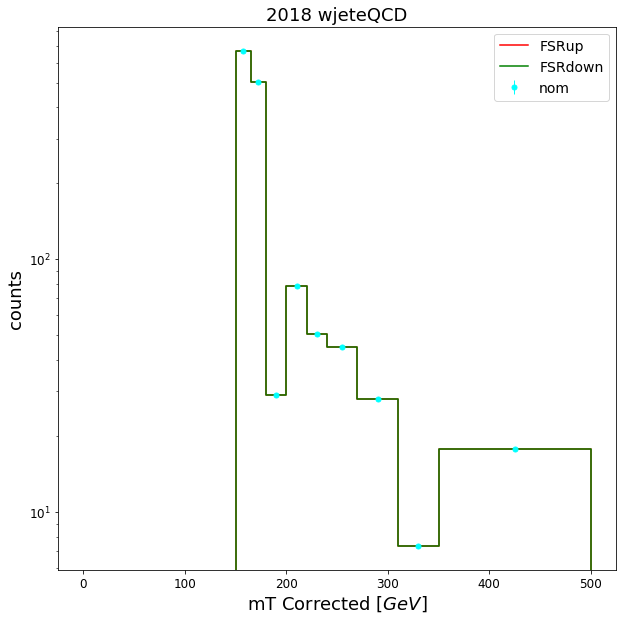

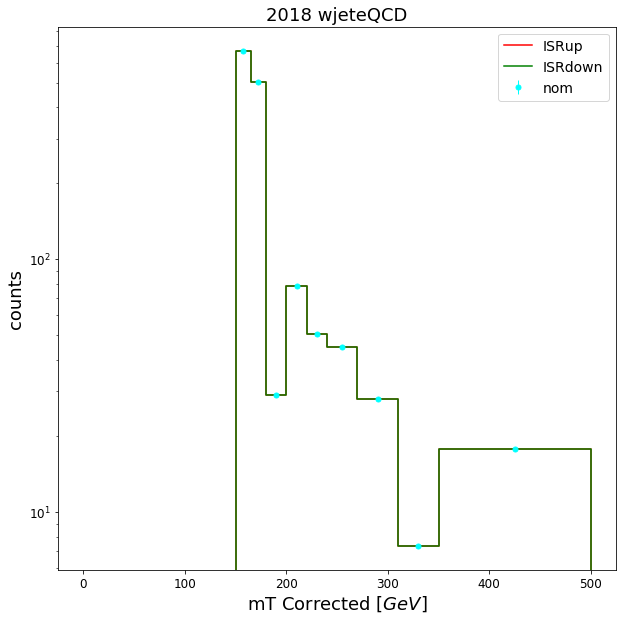

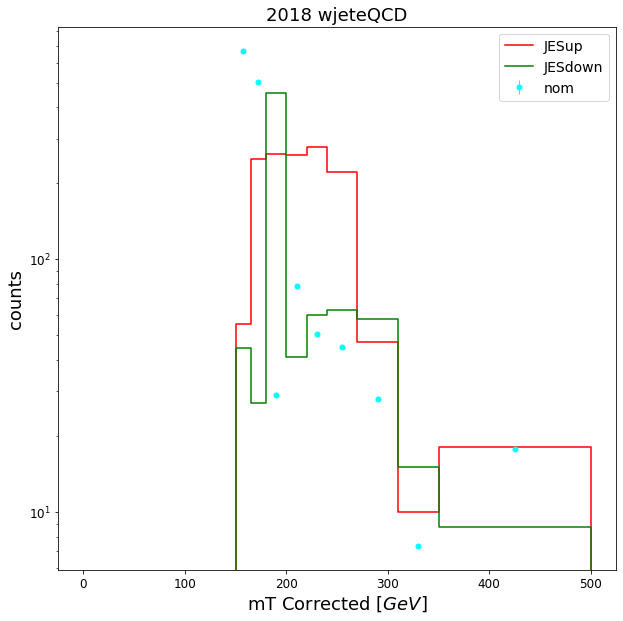

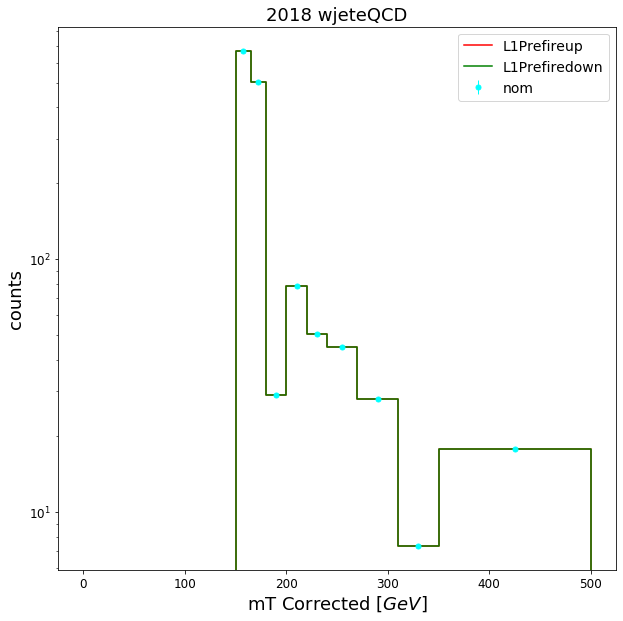

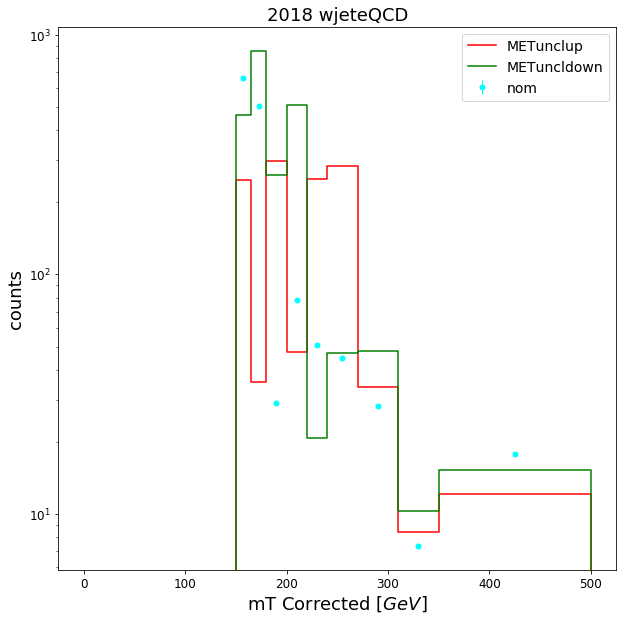

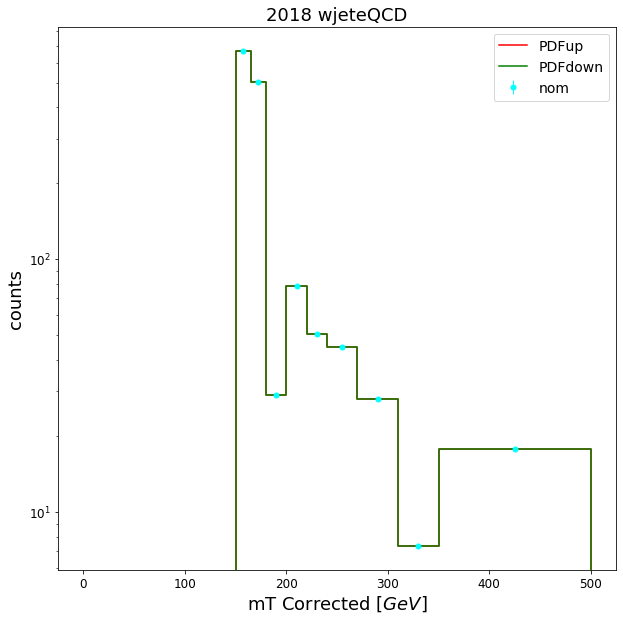

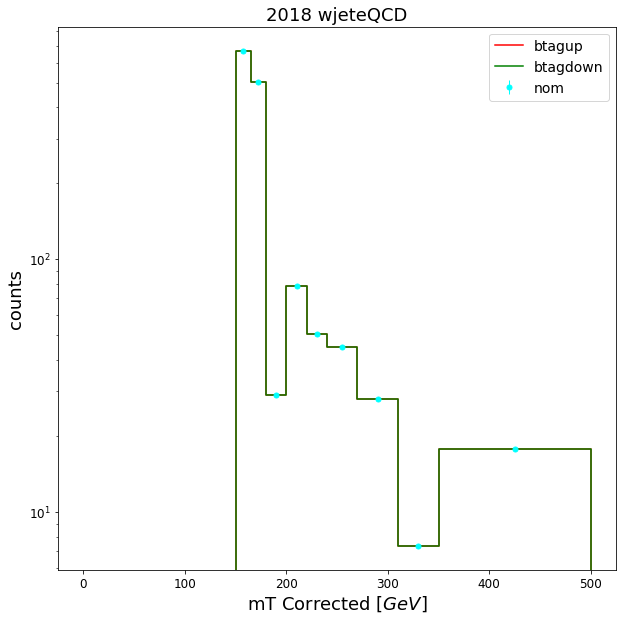

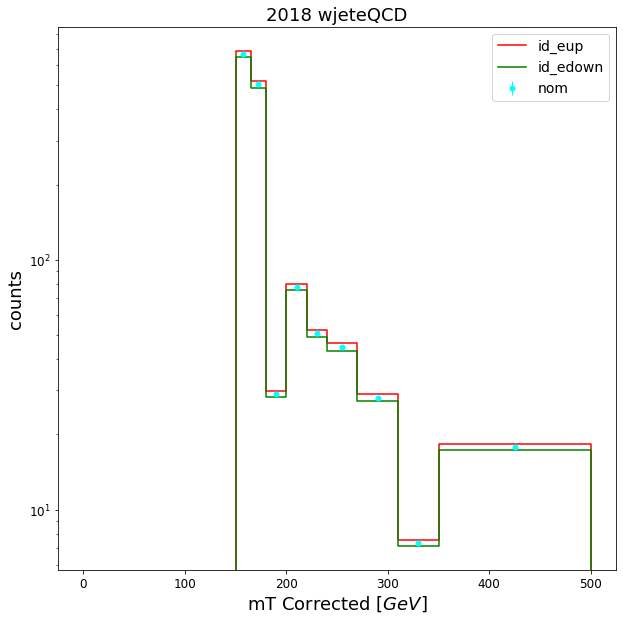

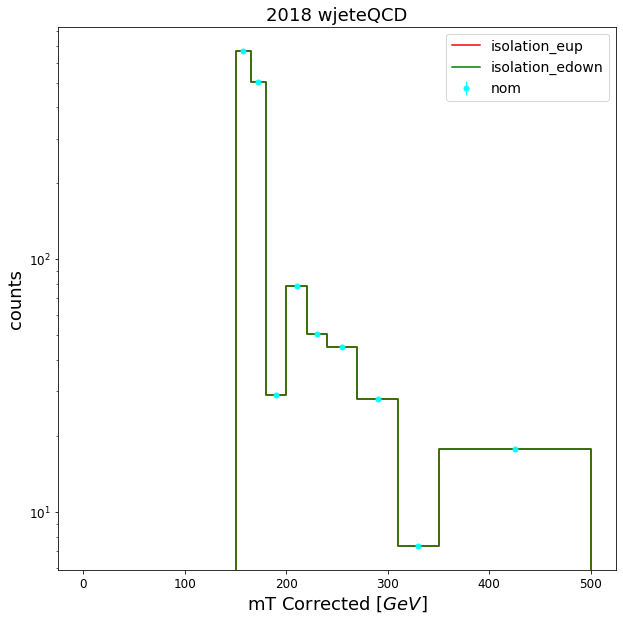

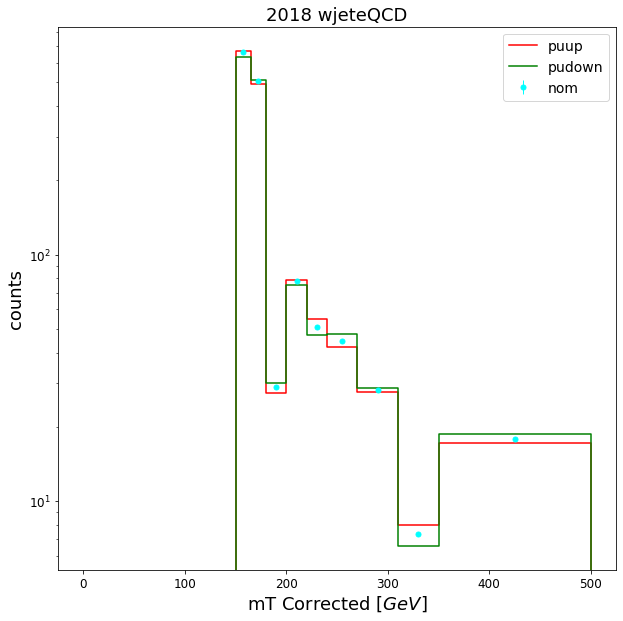

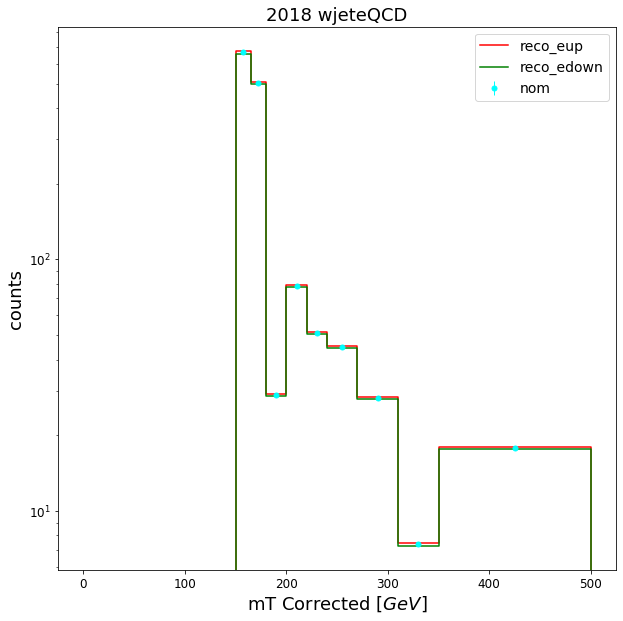

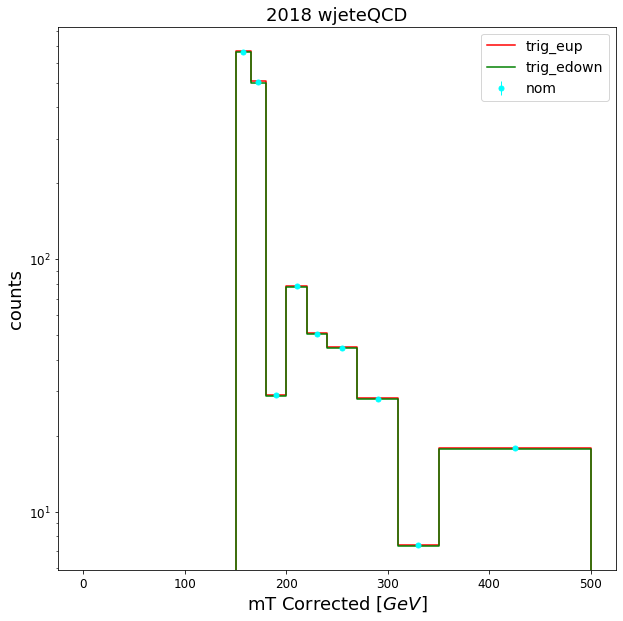

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
import re
cr = 'wjete'
p ='QCD'
# for p in bkg_hists['template'].identifiers('process'):
systematics = []
for syst in bkg_hists['template'].integrate('region', cr).integrate('process', p).identifiers('systematic'):
    if (re.search("Up$", str(syst))):
        systematics.append(str(syst)[:-2])
# sys = 'pu'


for sys in systematics:
    bins = bkg_hists['template'].integrate('region', cr).integrate("systematic",sys+"Down").axis("mT_corrected").edges()[()]
    down = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Down').integrate('process',p).integrate('npvs').values()[()]
    nom = bkg_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('process',p).integrate('npvs').values()[()]
    up = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Up').integrate('process',p).integrate('npvs').values()[()]
    if "e" in cr[-1]:
        label_data = "EGamma"
    else: label_data = "SingleMuon"
    f, ax = plt.subplots(figsize=[10,10])
    #         hep.histplot(data, bins,color='black',histtype='errorbar',
    #         label=label_data)
    hep.histplot(up, bins, color='red',
    label=sys+"up")
    hep.histplot(down, bins, color='green',
    label=sys+"down")
    hep.histplot(nom, bins, color='cyan',histtype='errorbar',
    label="nom")
    ax.legend()
    ax.set_yscale('log')
    ax.set_ylabel("counts")
    ax.set_xlabel("mT Corrected $[GeV]$")
    ax.set_title("2018 "+cr+str(p))

In [26]:
nom=bkg_hists['template'].integrate('region', 'ttbare').integrate('systematic', 'nominal').sum('process').sum('npvs').values()[()]

In [27]:


up=bkg_hists['template'].integrate('region', 'ttbare').integrate('systematic', sys).integrate('process', p).sum('npvs').values()[()]

In [28]:
up[nom<=0]=1

In [29]:
up[~(nom<=0)] /= nom[~(nom<=0)]

In [30]:
up

array([1.        , 1.        , 1.07154794, 1.09696809, 1.0759898 ,
       1.02870959, 1.06859724, 1.1096434 , 1.20136757, 1.20139976,
       1.16110514])

In [8]:

def remap_histograms(hists):
    
#     mT_corrected_binning_dict = {
# #     "2018":np.linspace(0, 600, 21),
# #     "2017":np.linspace(0, 600, 21),
# #     "2016":np.linspace(0, 600, 21)
#     "2018": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500]),
#     "2017": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500]),
#     "2016": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500])
# }
    data_hists = {}
    bkg_hists = {}
    signal_hists = {}

    process = hist.Cat("process", "Process", sorting="placement")
    cats = ("process",)
    sig_map = OrderedDict()
    bkg_map = OrderedDict()
    data_map = OrderedDict()
    bkg_map["Hbb"] = ("Hbb*",)
    bkg_map["DY+jets"] = ("DY+*",)
    bkg_map["VV"] = (["WW", "WZ", "ZZ"],)
    bkg_map["ST"] = ("ST*",)
    bkg_map["TT"] = ("TT*",)
    bkg_map["W+jets"] = ("W+*")
#     bkg_map["W+HF"] = ("W+HF",)
#     bkg_map["W+LF"] = ("W+LF",)
    bkg_map["Z+jets"] = ("Z+*",)
#     bkg_map["Z+HF"] = ("Z+HF",)
#     bkg_map["Z+LF"] = ("Z+LF",)
#     bkg_map["G+jets"] = ("G+*",)
    bkg_map["QCD"] = ("QCD*",)
    data_map["SingleElectron"] = ("SingleElectron",)
    data_map["SingleMuon"] = ("SingleMuon",)
    data_map["EGamma"] = ("EGamma",)
    sig_map['Mphi-1000_Mchi-1000'] = ('*Mphi-1000_Mchi-1000*')
    sig_map['Mphi-1000_Mchi-150'] = ('*Mphi-1000_Mchi-150*')
    sig_map['Mphi-1250_Mchi-150'] = ('*Mphi-1250_Mchi-150*')
    sig_map['Mphi-1495_Mchi-750'] = ('*Mphi-1495_Mchi-750*')
    sig_map['Mphi-1500_Mchi-1000'] = ('*Mphi-1500_Mchi-1000*')
    sig_map['Mphi-1500_Mchi-150'] = ('*Mphi-1500_Mchi-150*')
    sig_map['Mphi-1700_Mchi-800'] = ('*Mphi-1700_Mchi-800*')
    sig_map['Mphi-1750_Mchi-150'] = ('*Mphi-1750_Mchi-150*')
    sig_map['Mphi-1750_Mchi-700'] = ('*Mphi-1750_Mchi-700*')
    sig_map['Mphi-195_Mchi-100'] = ('*Mphi-195_Mchi-100*')
    sig_map['Mphi-1995_Mchi-1000'] = ('*Mphi-1995_Mchi-1000*')
    sig_map['Mphi-2000_Mchi-1500'] = ('*Mphi-2000_Mchi-1500*')
    sig_map['Mphi-2000_Mchi-150'] = ('*Mphi-2000_Mchi-150*')
    sig_map['Mphi-2000_Mchi-500'] = ('*Mphi-2000_Mchi-500*')
    sig_map['Mphi-200_Mchi-150'] = ('*Mphi-200_Mchi-150*')
    sig_map['Mphi-200_Mchi-50'] = ('*Mphi-200_Mchi-50*')
    sig_map['Mphi-2495_Mchi-1250'] = ('*Mphi-2495_Mchi-1250*')
    sig_map['Mphi-2500_Mchi-2000'] = ('*Mphi-2500_Mchi-2000*')
    sig_map['Mphi-2500_Mchi-750'] = ('*Mphi-2500_Mchi-750*')
    sig_map['Mphi-295_Mchi-150'] = ('*Mphi-295_Mchi-150*')
    sig_map['Mphi-2995_Mchi-1500'] = ('*Mphi-2995_Mchi-1500*')
    sig_map['Mphi-3000_Mchi-1000'] = ('*Mphi-3000_Mchi-1000*')
    sig_map['Mphi-3000_Mchi-2000'] = ('*Mphi-3000_Mchi-2000*')
    sig_map['Mphi-300_Mchi-100'] = ('*Mphi-300_Mchi-100*')
    sig_map['Mphi-300_Mchi-300'] = ('*Mphi-300_Mchi-300*')
    sig_map['Mphi-495_Mchi-250'] = ('*Mphi-495_Mchi-250*')
    sig_map['Mphi-500_Mchi-150'] = ('*Mphi-500_Mchi-150*')
    sig_map['Mphi-500_Mchi-500'] = ('*Mphi-500_Mchi-500*')
    sig_map['Mphi-750_Mchi-150'] = ('*Mphi-750_Mchi-150*')
    sig_map['Mphi-995_Mchi-500'] = ('*Mphi-995_Mchi-500*')
#     haven't processed signal yet
    for signal in hists['sig']['template'].identifiers('process'):
        if 'mchi' not in str(signal): continue
        sig_map[str(signal)] = (str(signal),)  ## signals

    for key in hists["data"].keys():
        bkg_hists[key] = hists["bkg"][key].group(cats, process, bkg_map)
        signal_hists[key] = hists["sig"][key].group(cats, process, sig_map)
        data_hists[key] = hists["data"][key].group(cats, process, data_map)

    print('initial mT_corrected binning',bkg_hists["template"].axis("mT_corrected").edges())


    bkg_hists["template"] = bkg_hists["template"].rebin(
        "mT_corrected", hist.Bin("mT_corrected", "mT_corrected", mT_corrected_binning)
    )
    signal_hists["template"] = signal_hists["template"].rebin(
        "mT_corrected", hist.Bin("mT_corrected", "mT_corrected", mT_corrected_binning)
    )
    data_hists["template"] = data_hists["template"].rebin(
        "mT_corrected", hist.Bin("mT_corrected", "mT_corrected", mT_corrected_binning)
    )

    hists = {"bkg": bkg_hists, "data": data_hists, "sig":signal_hists}
    print('new mT_corrected binning',bkg_hists["template"].axis("mT_corrected").edges())
    return hists

In [9]:
year = '2018'

mT_corrected_binning_dict = {
    "2018":np.array([120., 150., 180., 210.,  270., 390.,
        510.]),
    "2017":np.array([120., 150., 180., 210.,  270., 390.,
        510.]),
    "2016":np.array([120., 150., 180., 210.,  270., 390.,
        510.])

}
mT_corrected_binning = mT_corrected_binning_dict[year]
mT_correctedbins = np.array(mT_corrected_binning)
nmT_corrected = len(mT_correctedbins) - 1

###
# Extract histograms from input file
###

print("Grouping histograms")
hists = load("../../../hists/UL_lep_monotop_v1_test_" + year + ".scaled")
hists = remap_histograms(hists)
data_hists = hists["data"]
bkg_hists = hists["bkg"]
signal_hists = hists["sig"]

###
# Preparing histograms for fit
##

# data = {}
# for r in data_hists["template"].identifiers("region"):
#     data[str(r)] = data_hists["template"].integrate("region", r)

# background = {}
# for r in bkg_hists["template"].identifiers("region"):
#     background[str(r)] = bkg_hists["template"].integrate("region", r)

# signal = {}
# for r in signal_hists["template"].identifiers("region"):
#     signal[str(r)] = signal_hists["template"].integrate("region", r)

Grouping histograms
initial mT_corrected binning [120. 150. 180. 210. 240. 270. 300. 330. 360. 390. 420. 450. 480. 510.
 540. 570. 600.]
new mT_corrected binning [120. 150. 180. 210. 270. 390. 510.]


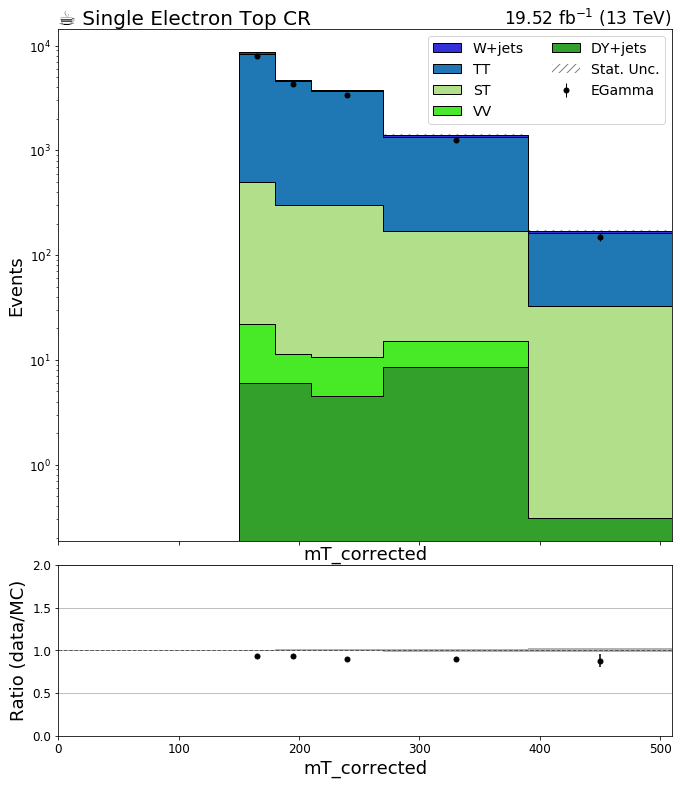

In [16]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'ttbare'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if 'template' not in key: continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'mT_corrected' not in key:continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate("systematic", sys).integrate('region',j).integrate('npvs')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j).integrate('npvs'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate("systematic", sys).integrate('region',j).integrate('npvs').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate("systematic", sys).integrate('region',j).integrate('npvs').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"19.52 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
#         fig.savefig(os.path.join(plot_path, plot_name))

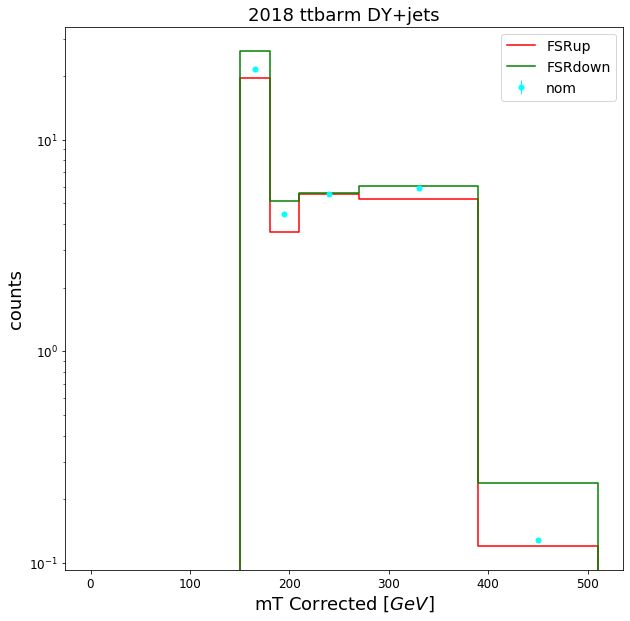

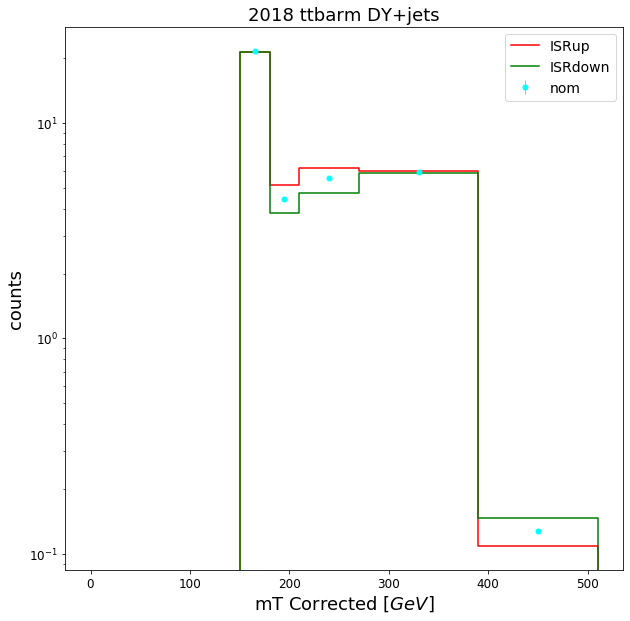

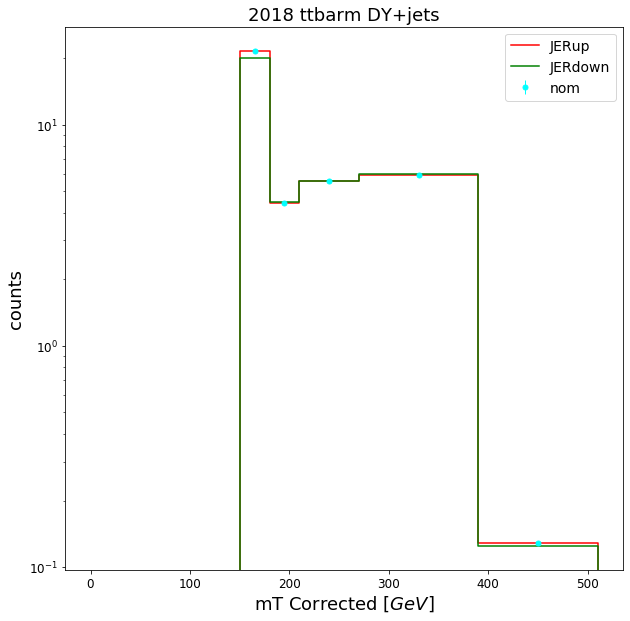

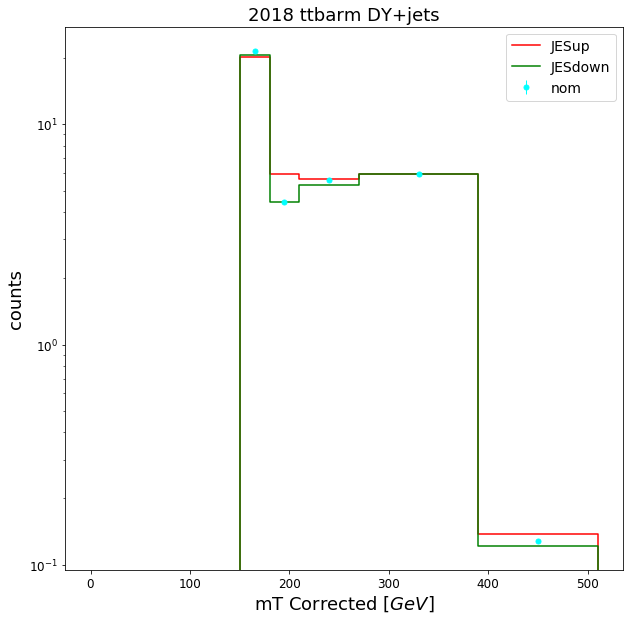

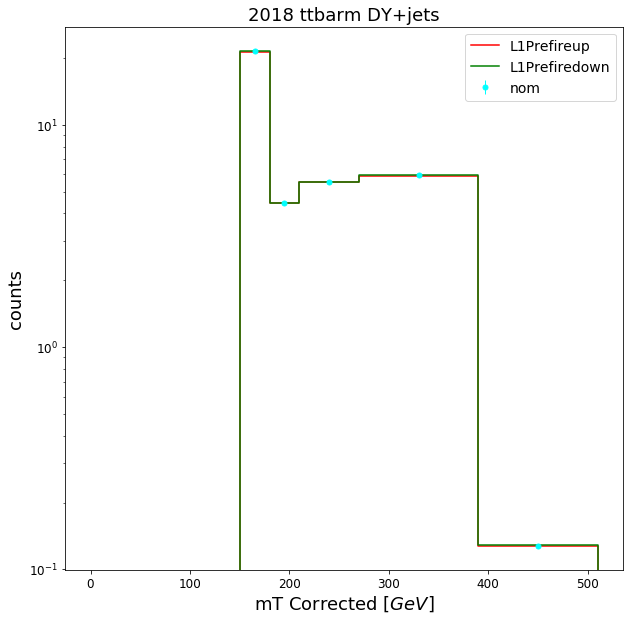

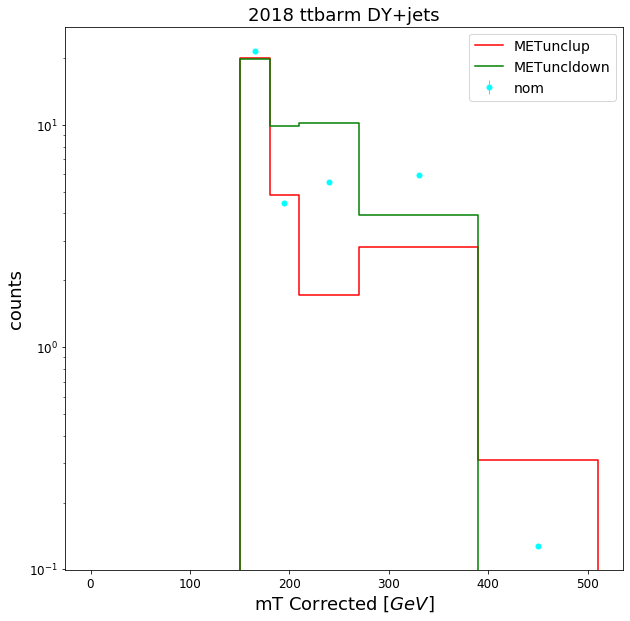

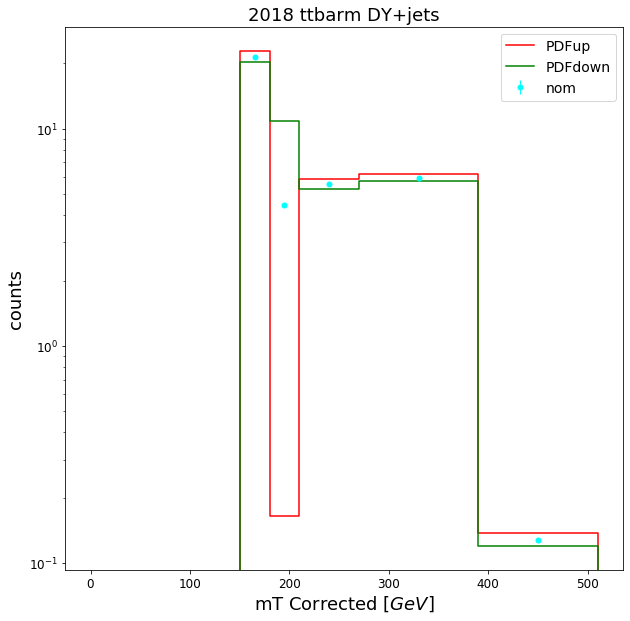

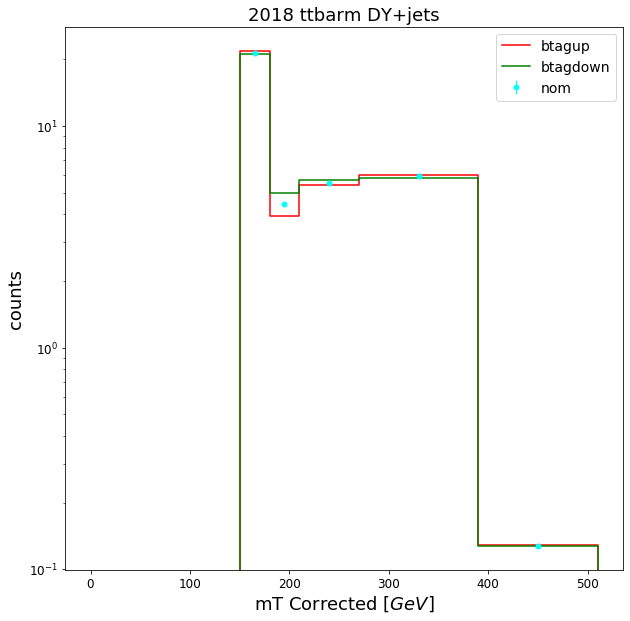

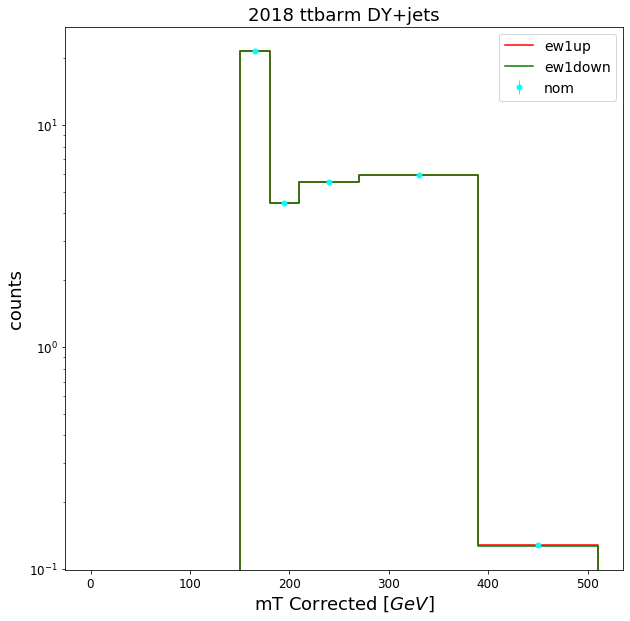

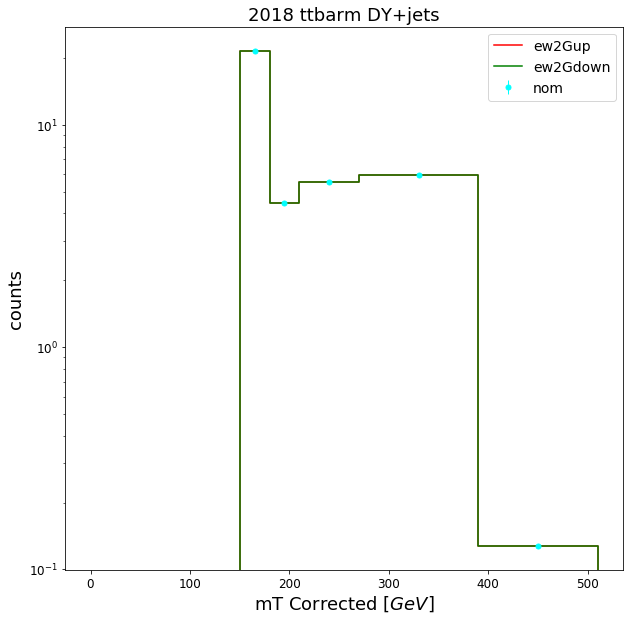

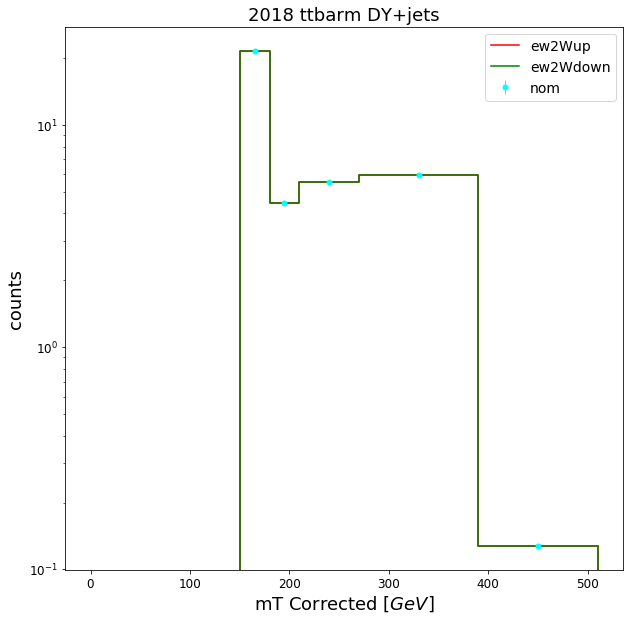

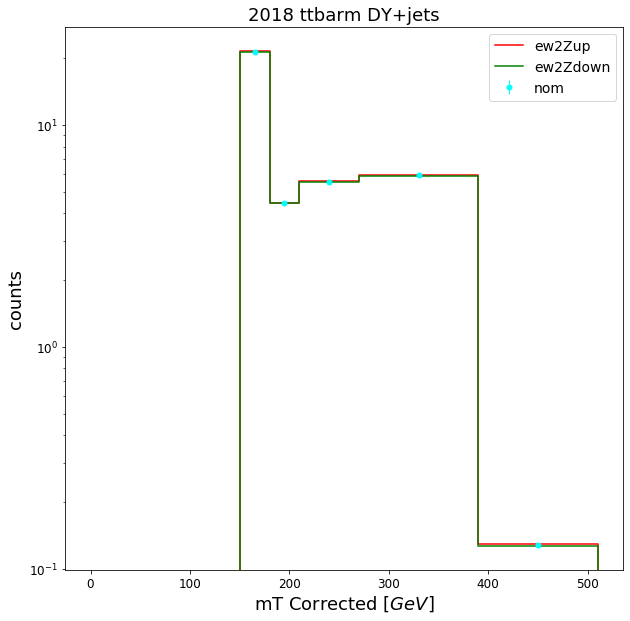

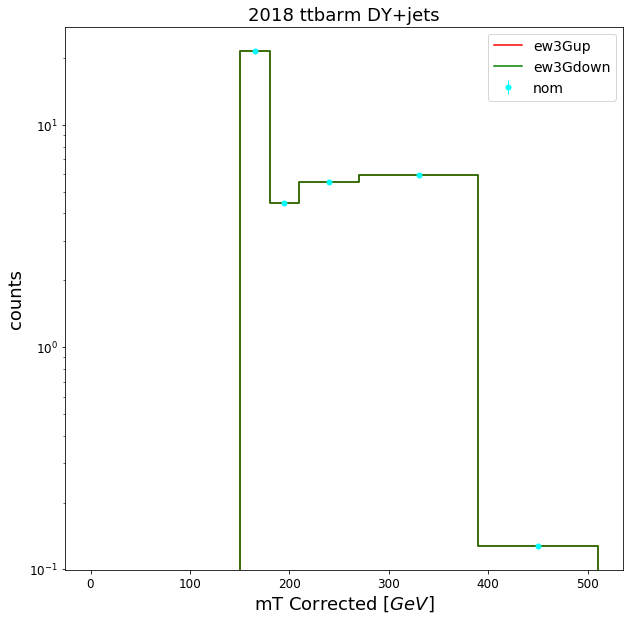

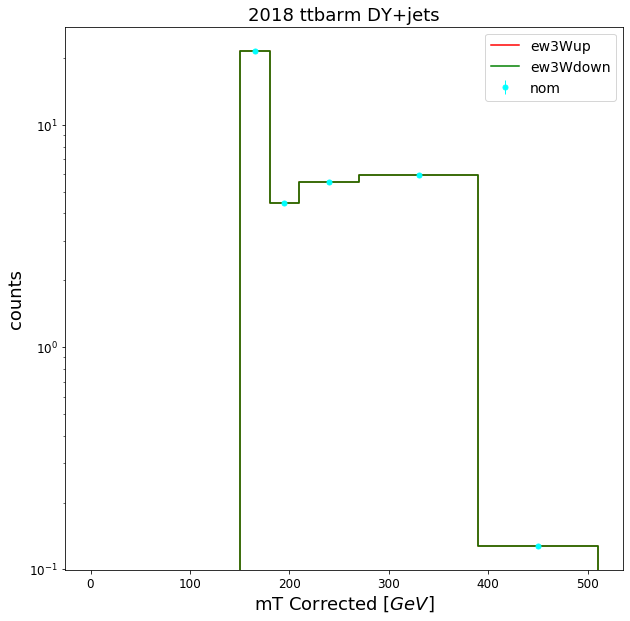

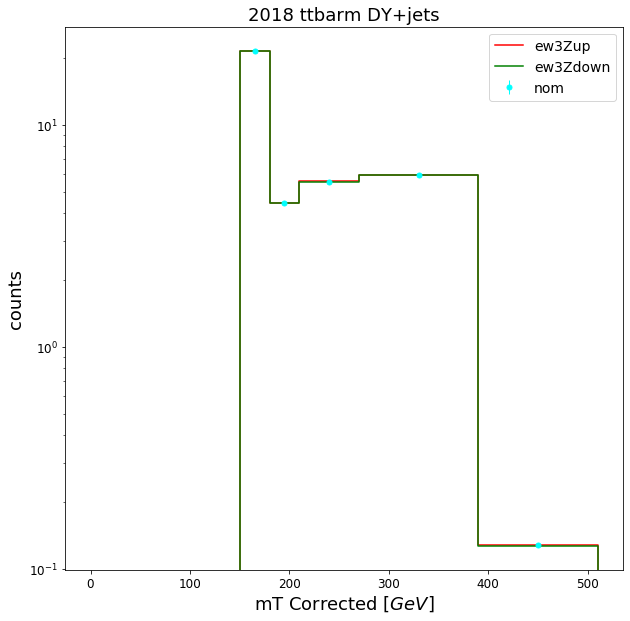

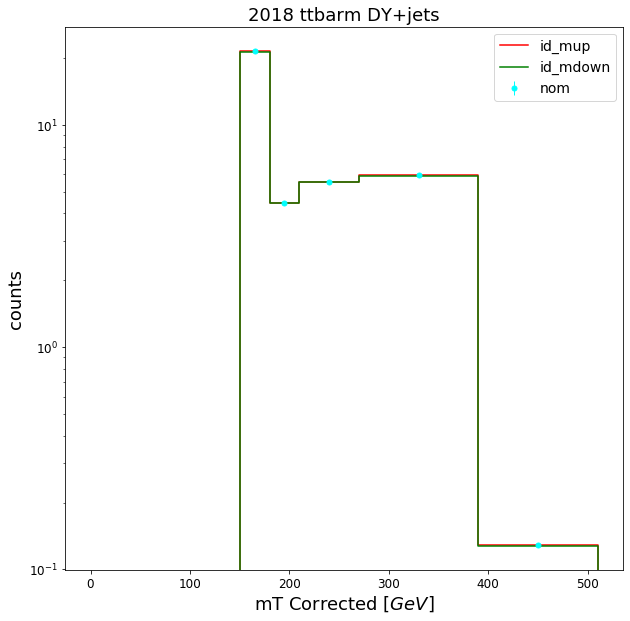

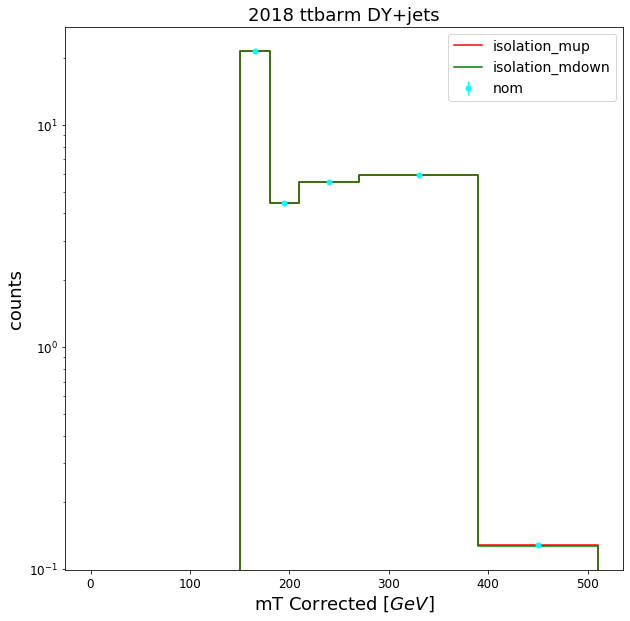

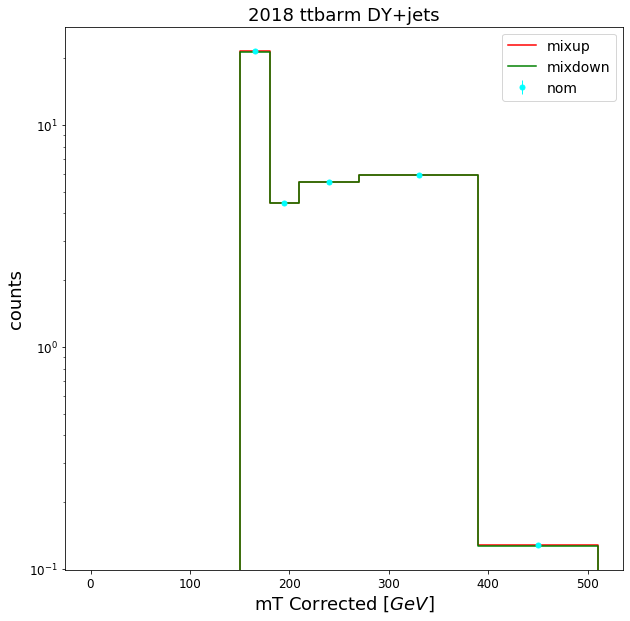

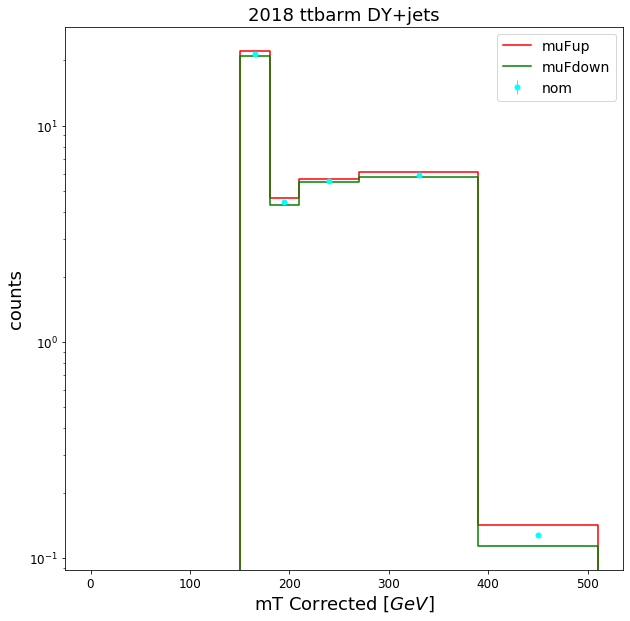

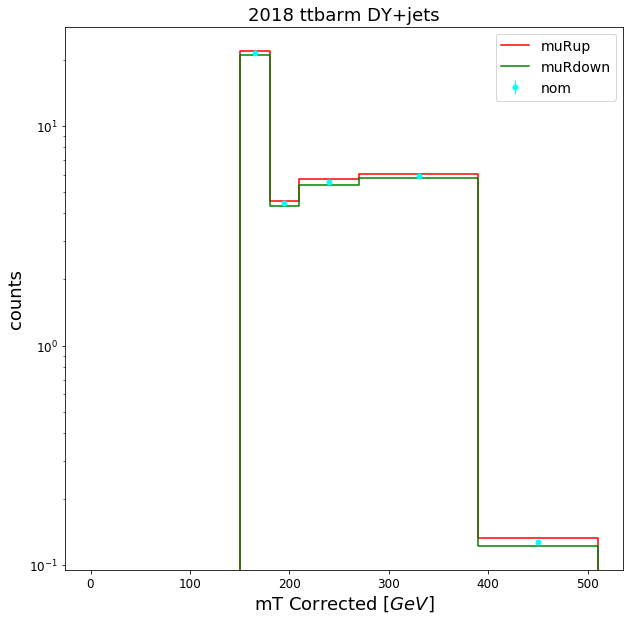

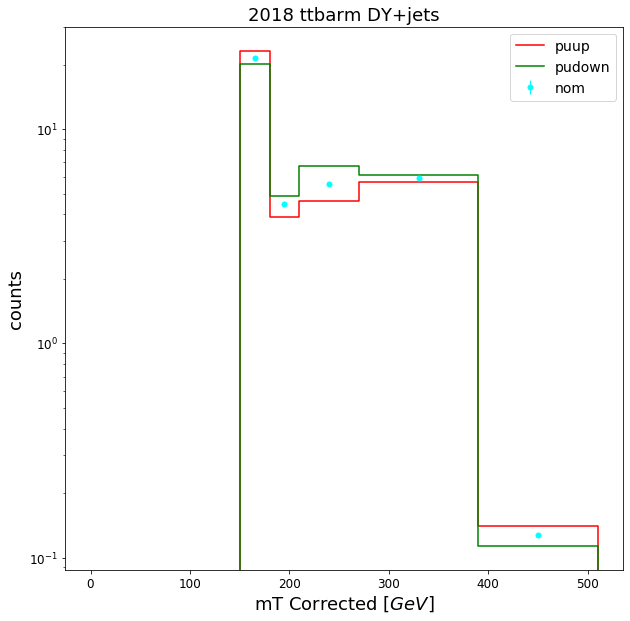

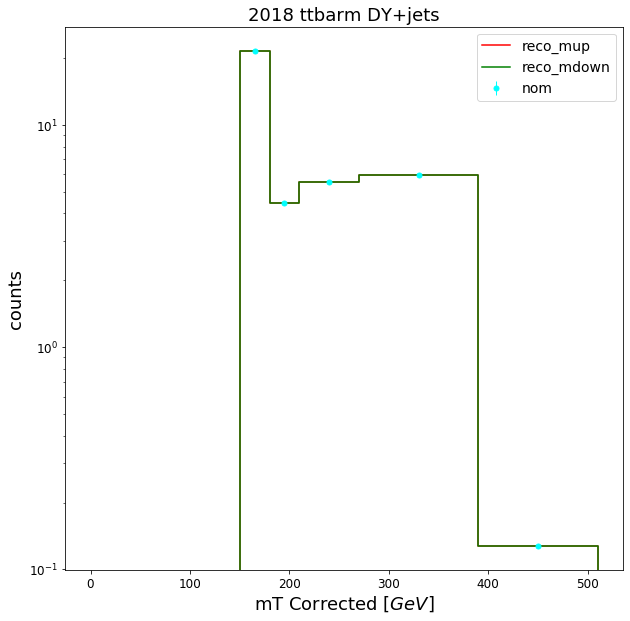

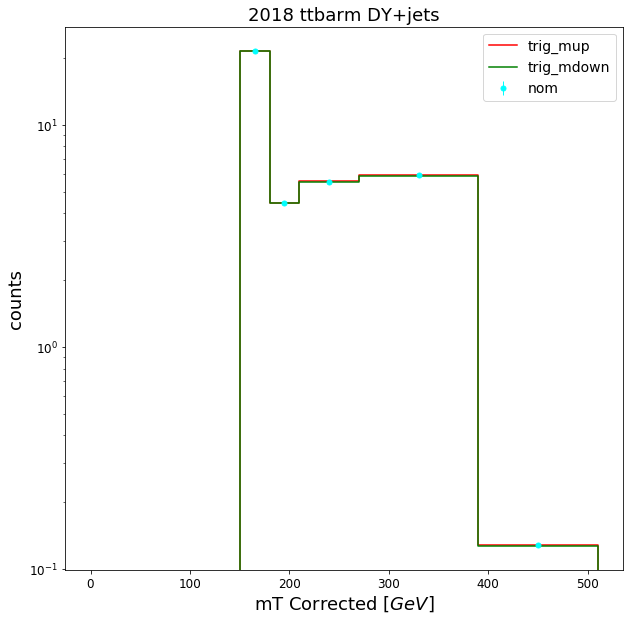

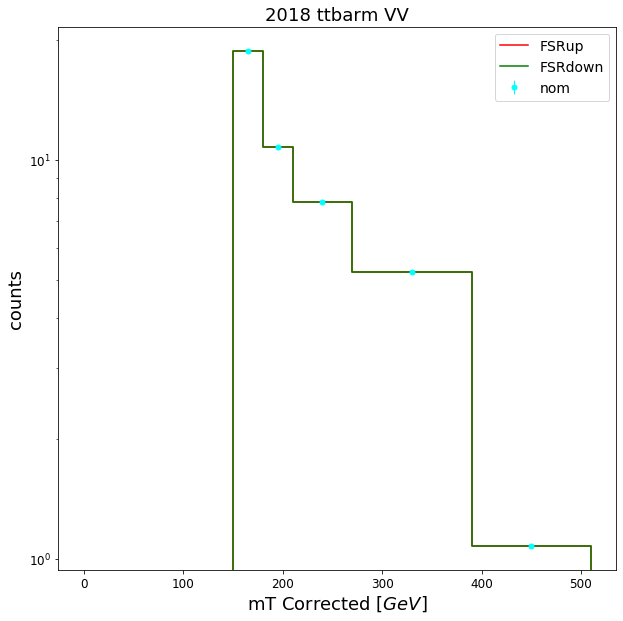

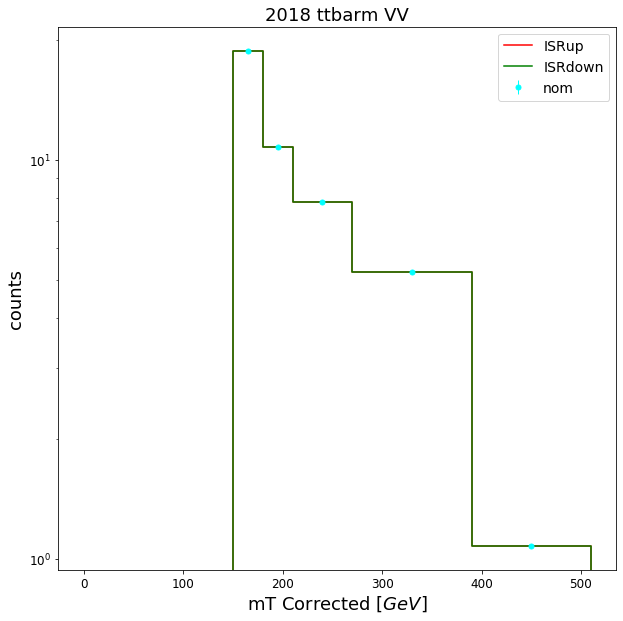

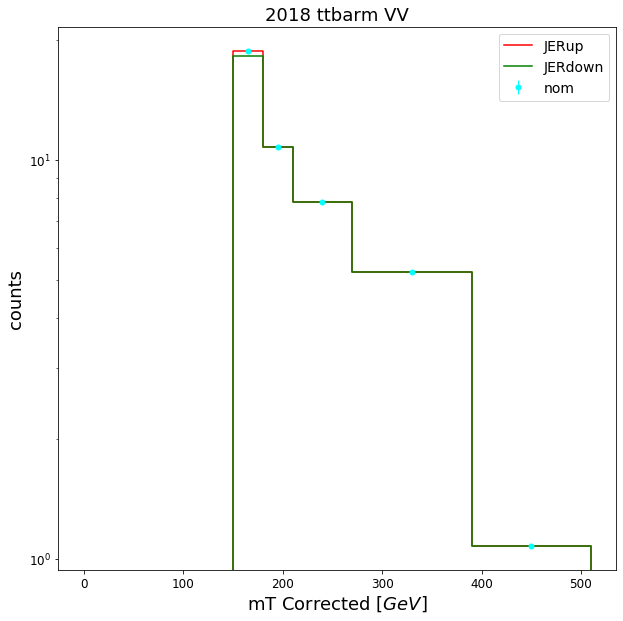

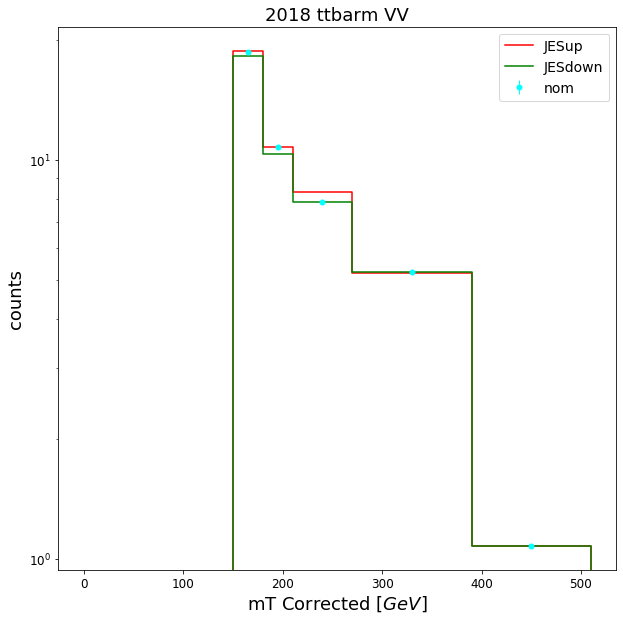

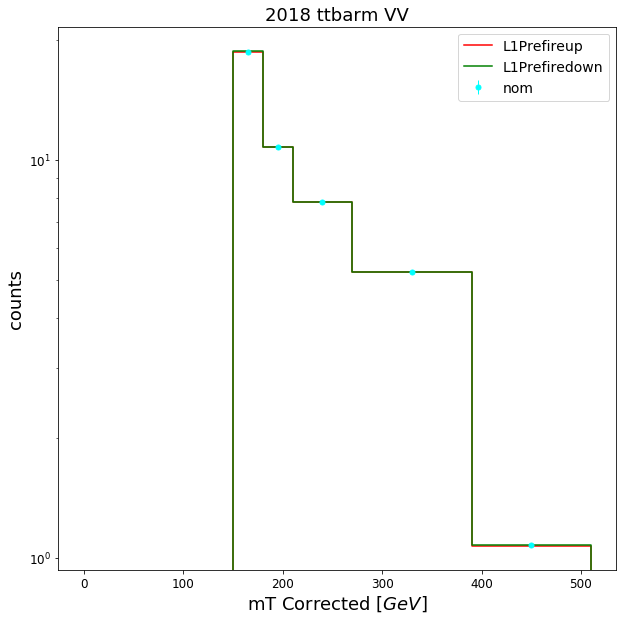

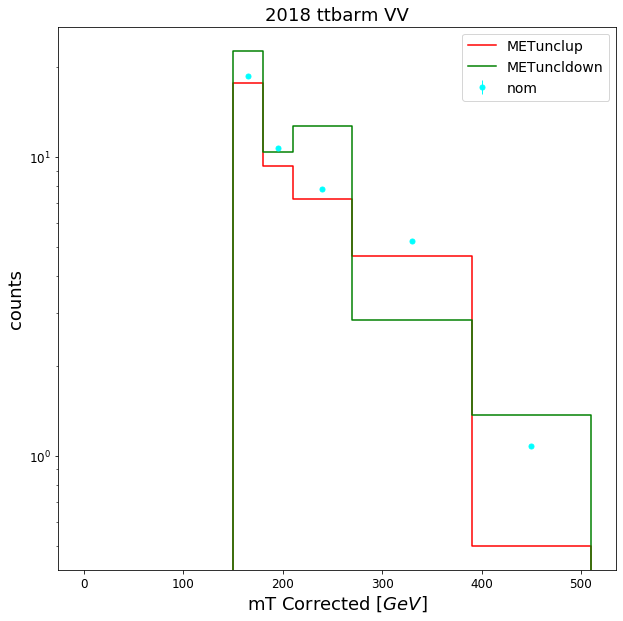

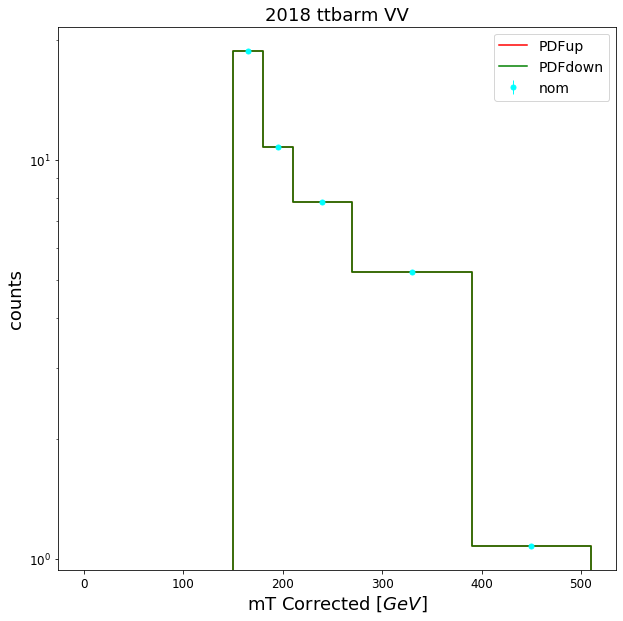

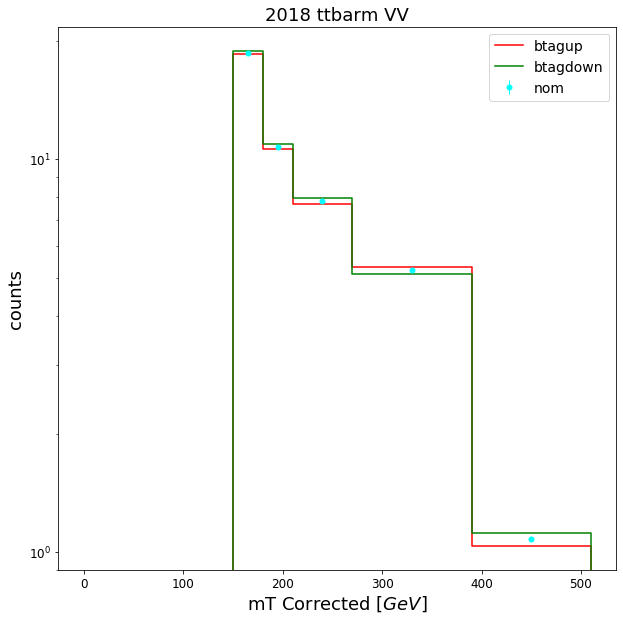

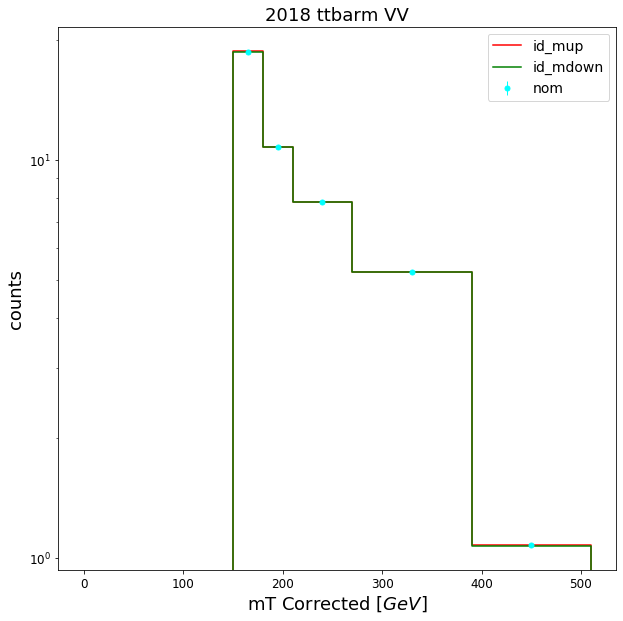

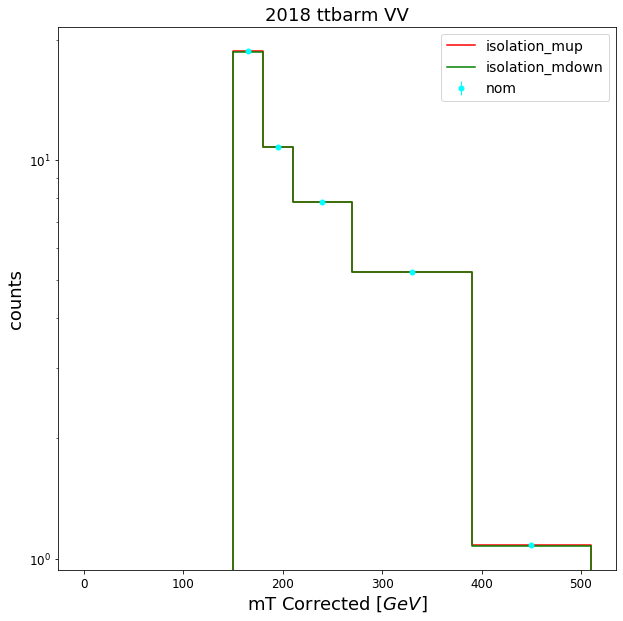

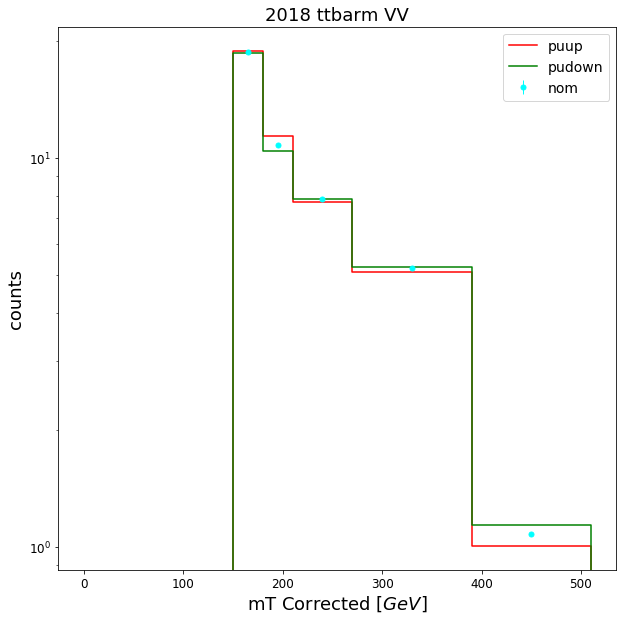

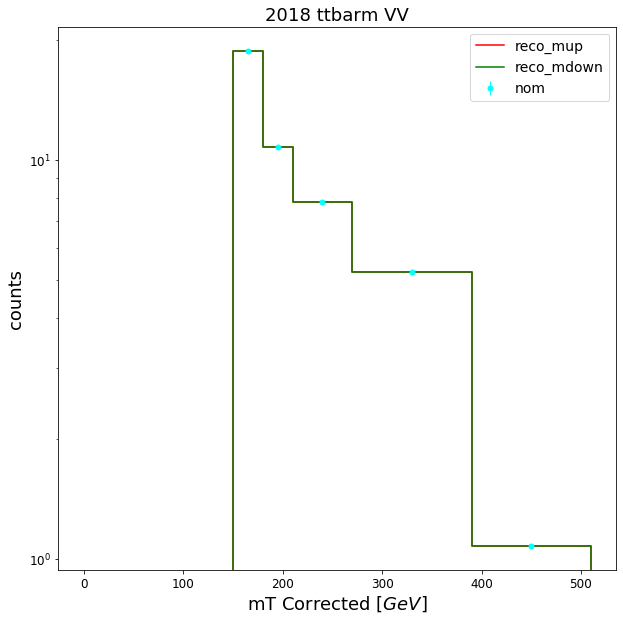

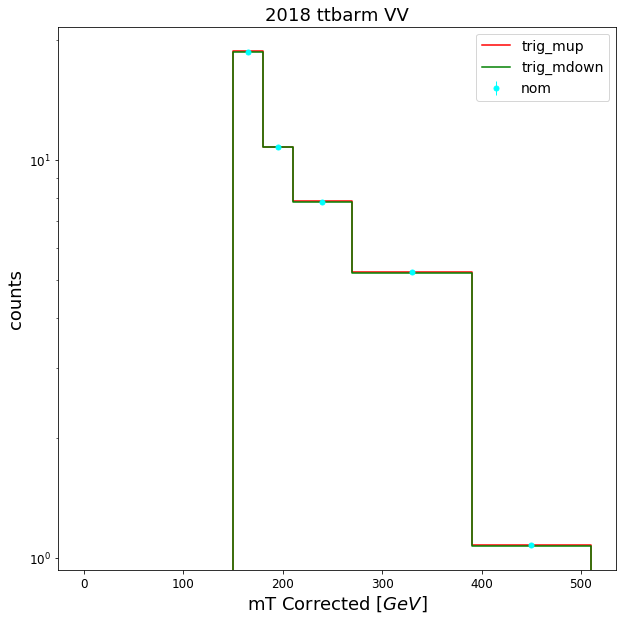

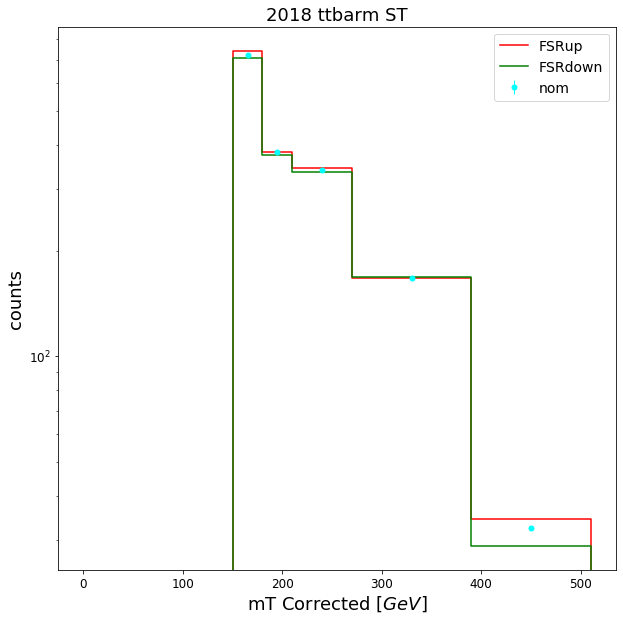

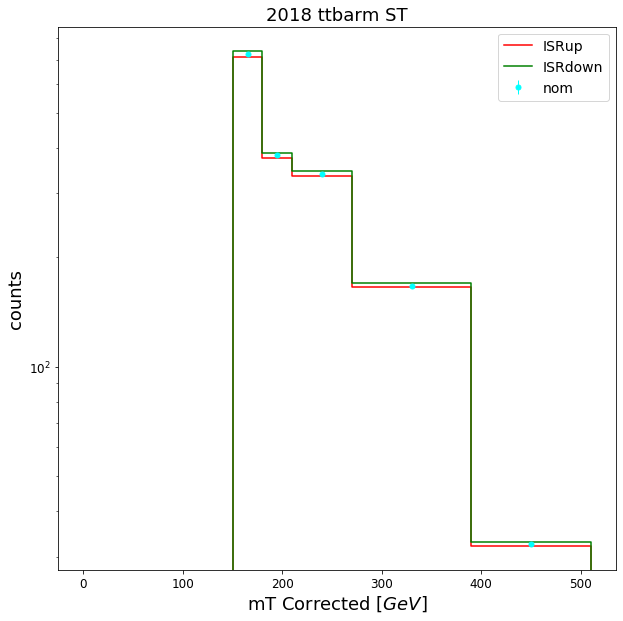

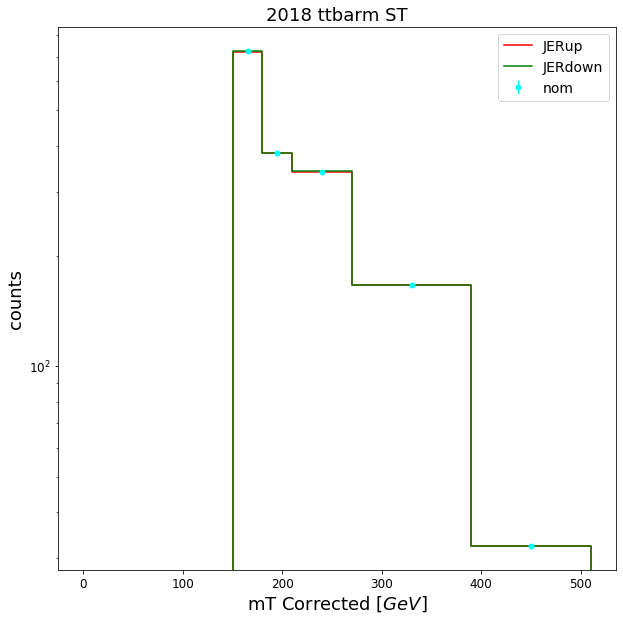

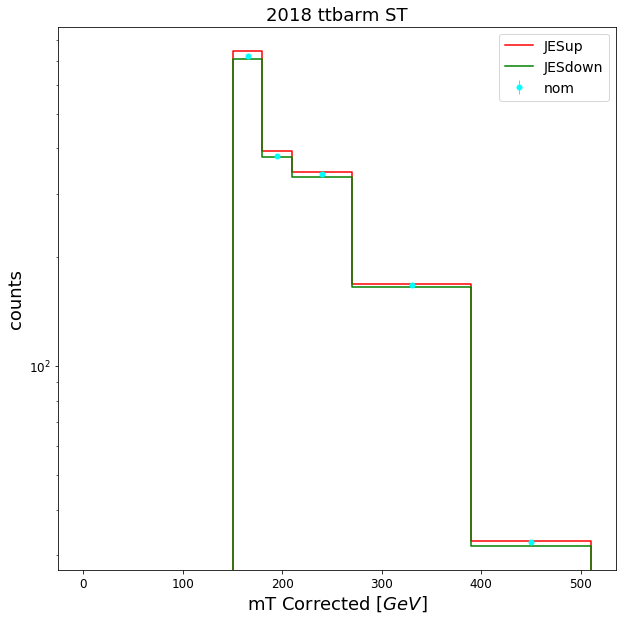

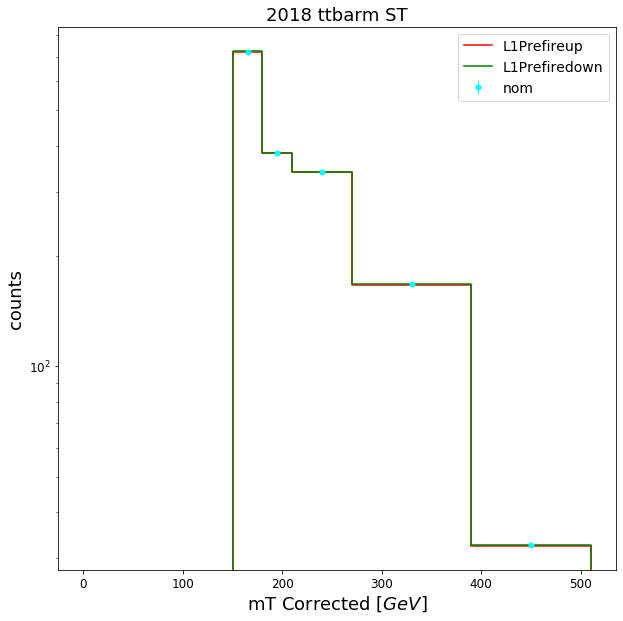

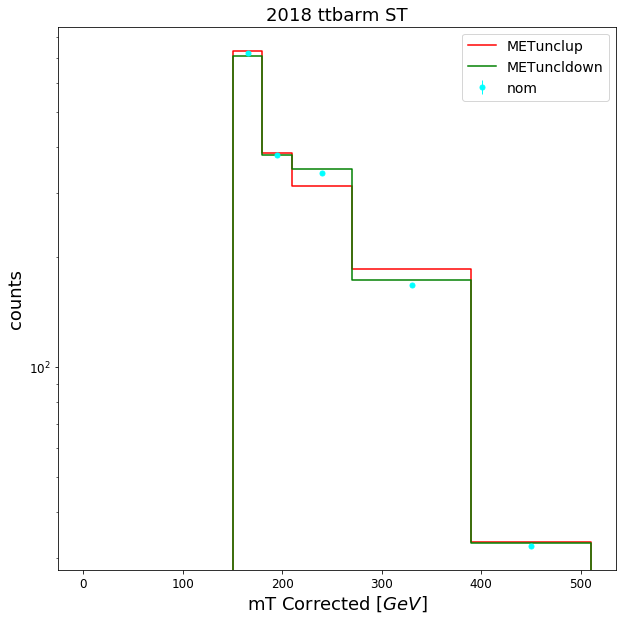

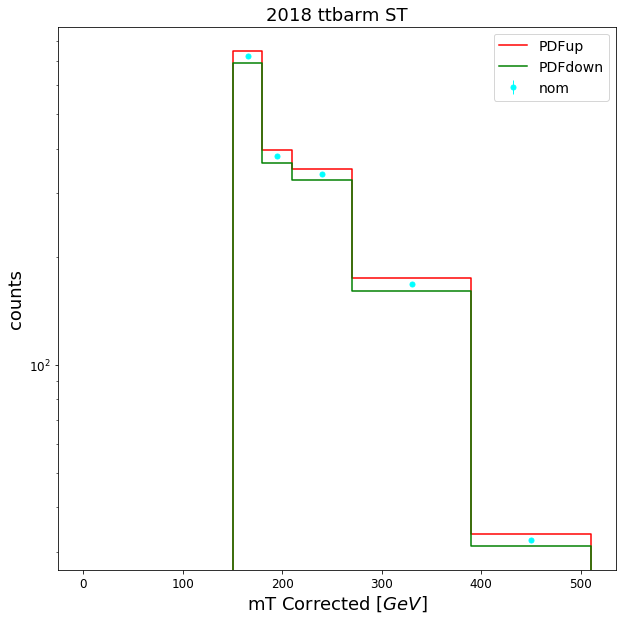

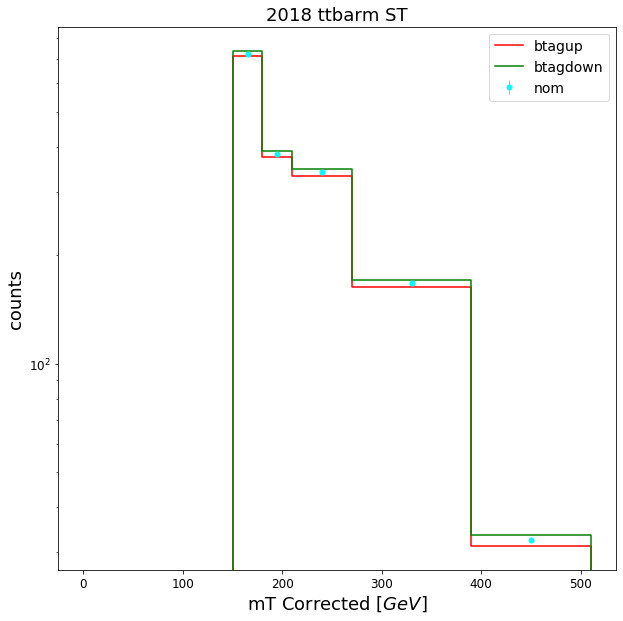

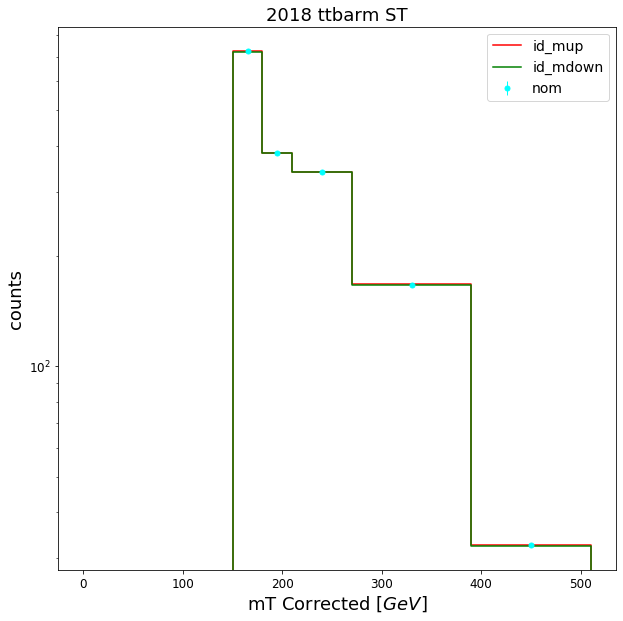

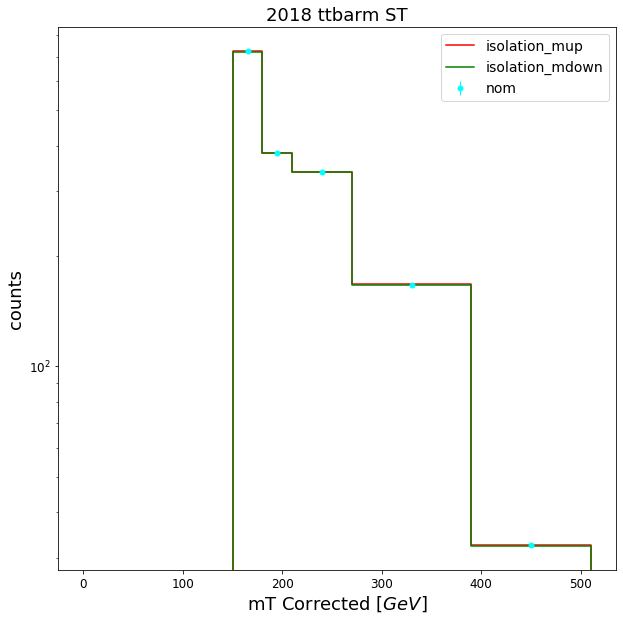

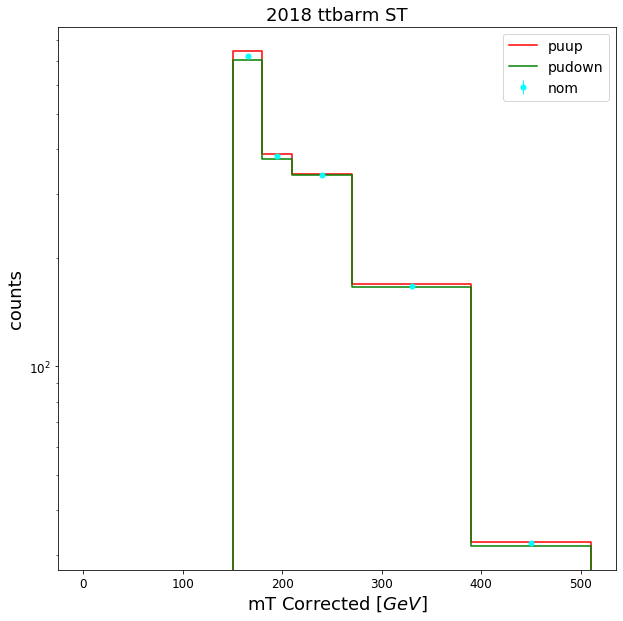

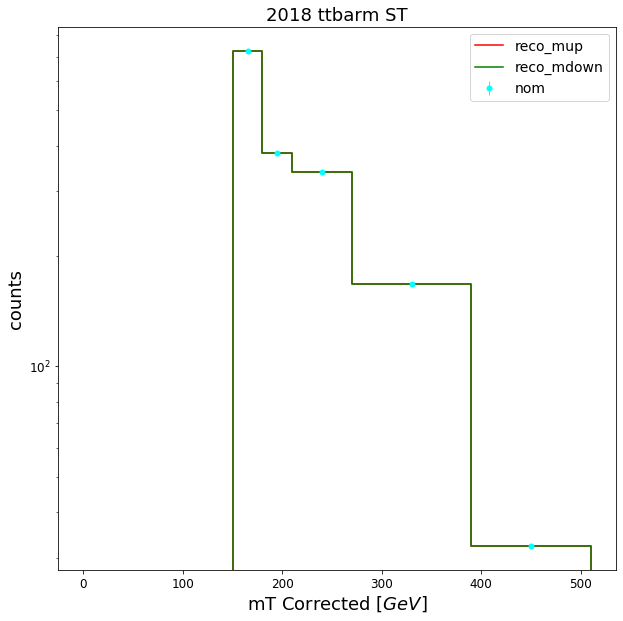

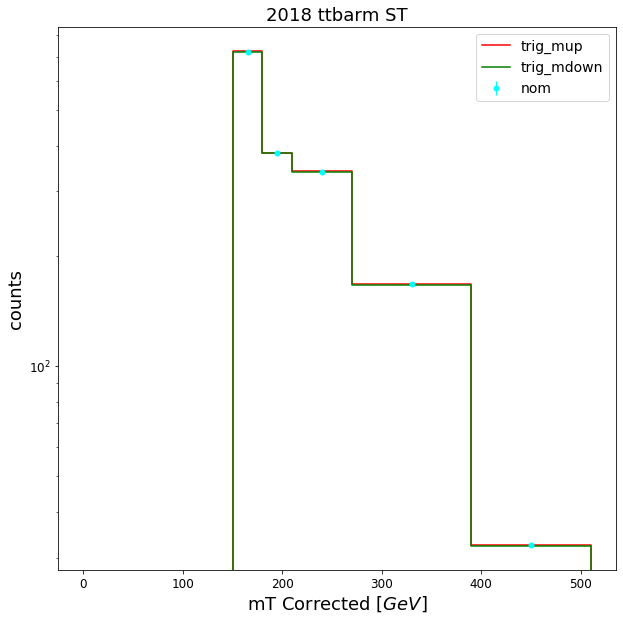

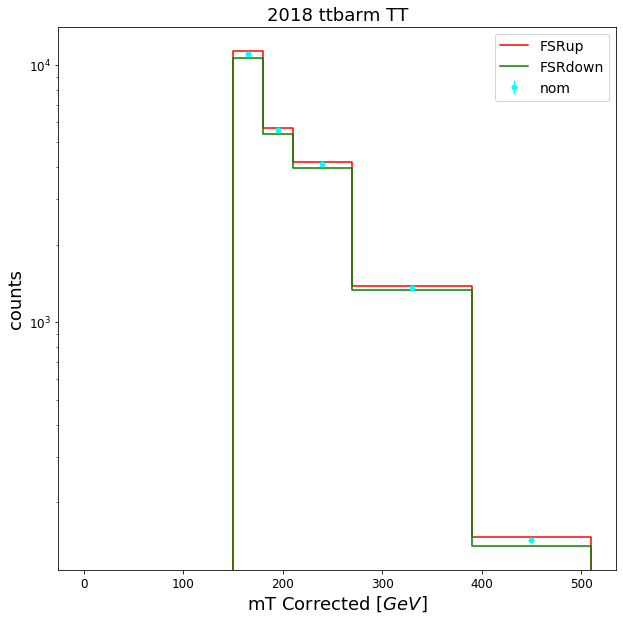

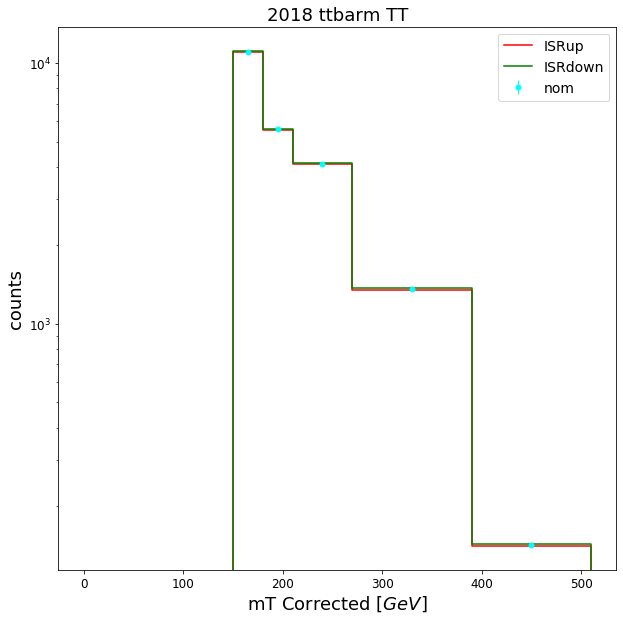

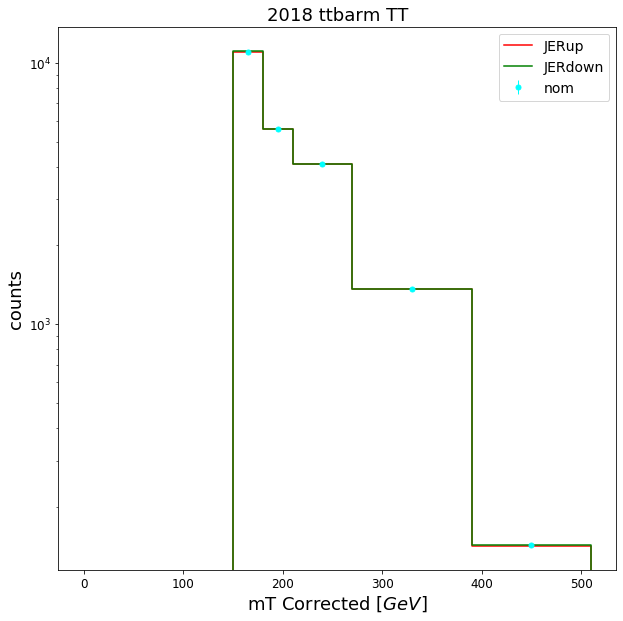

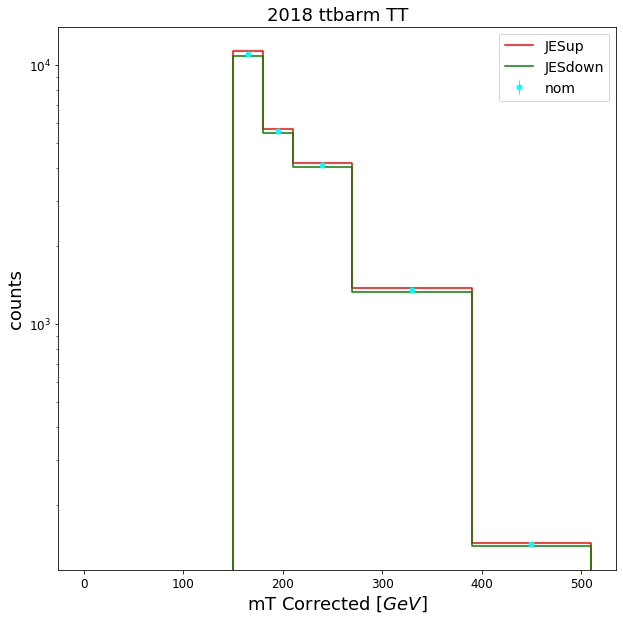

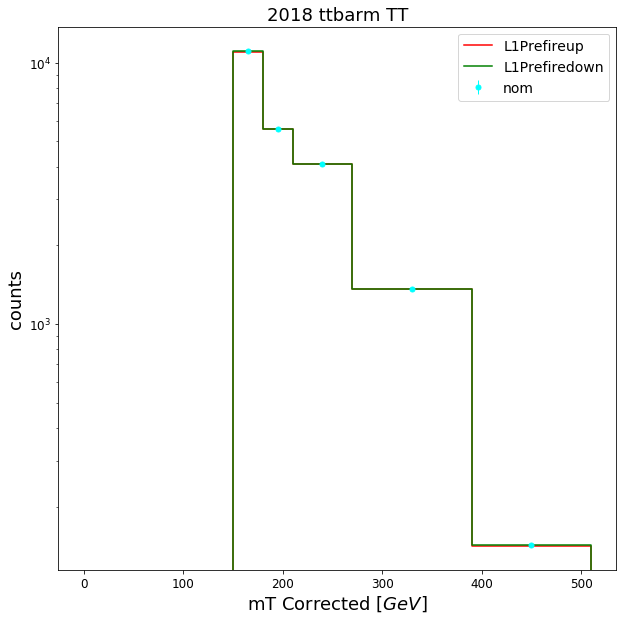

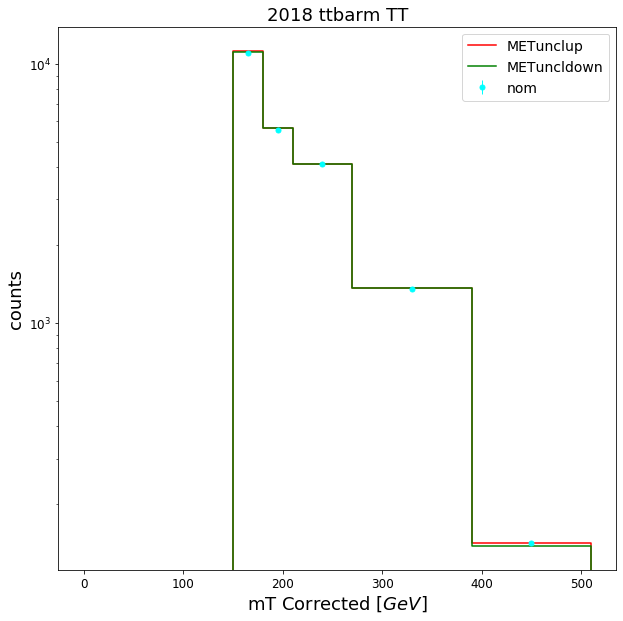

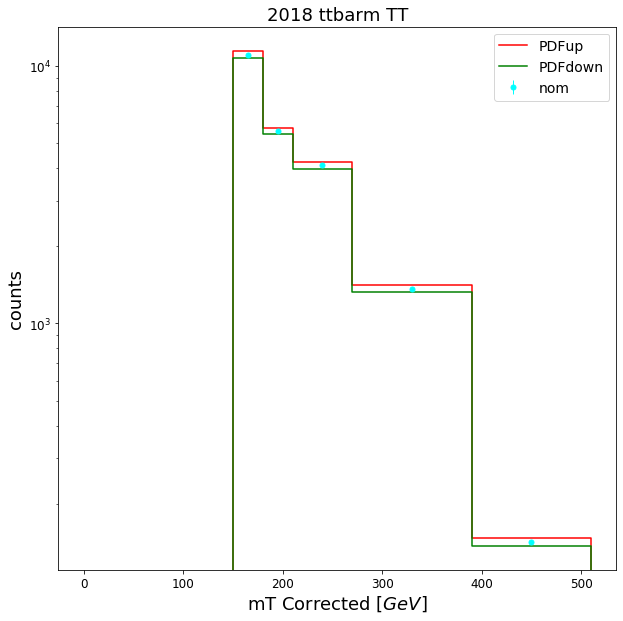

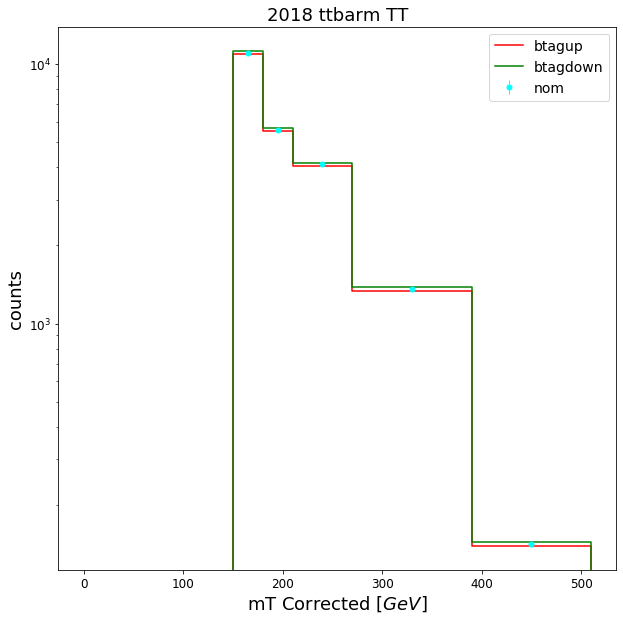

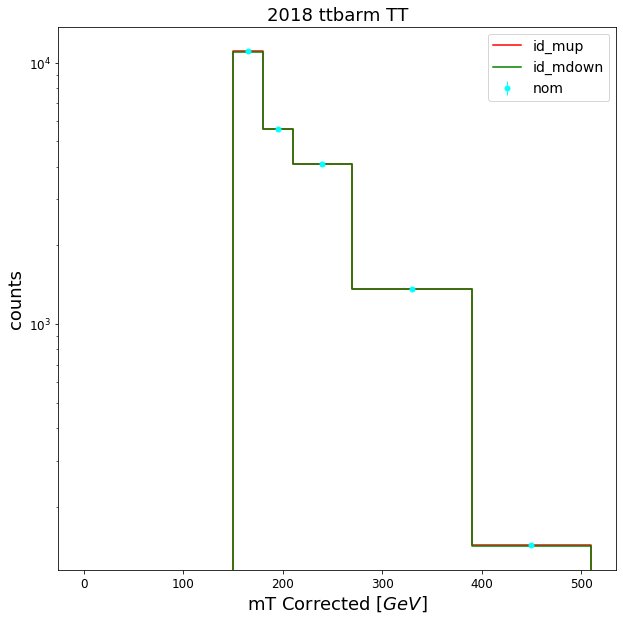

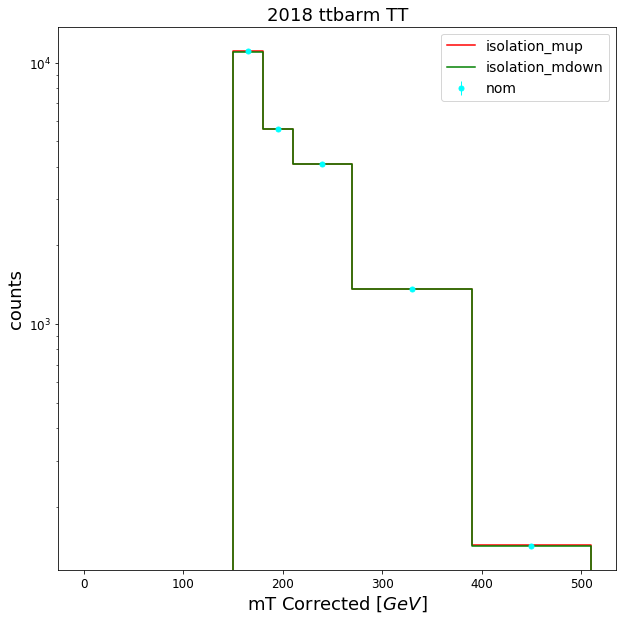

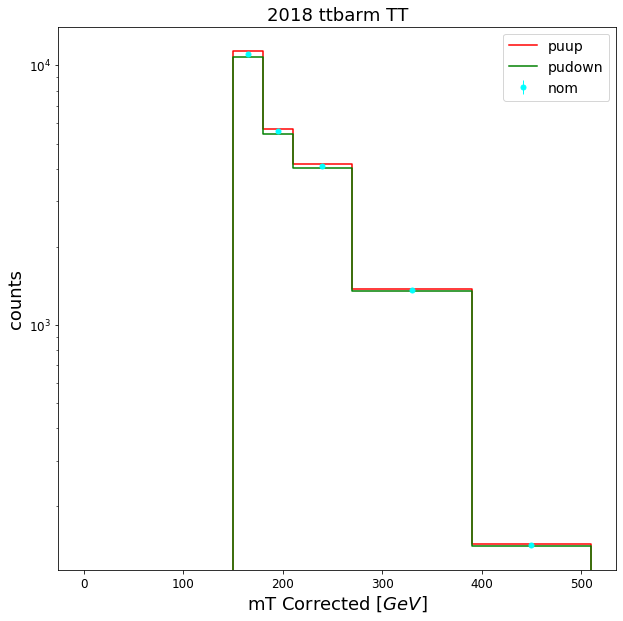

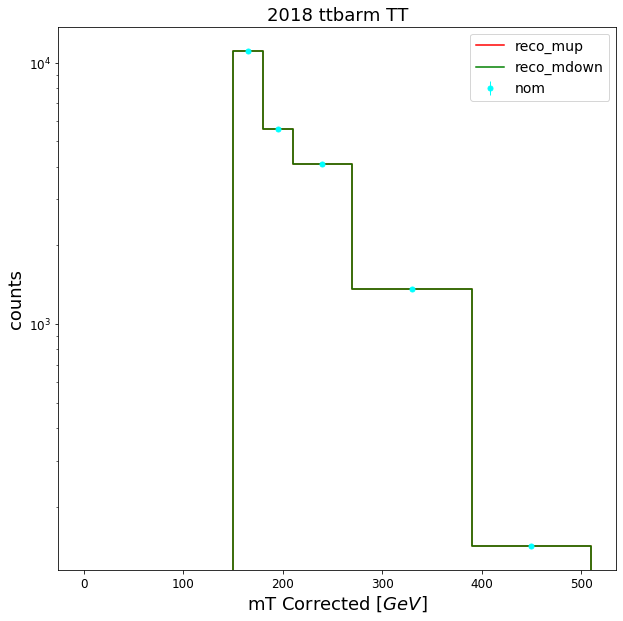

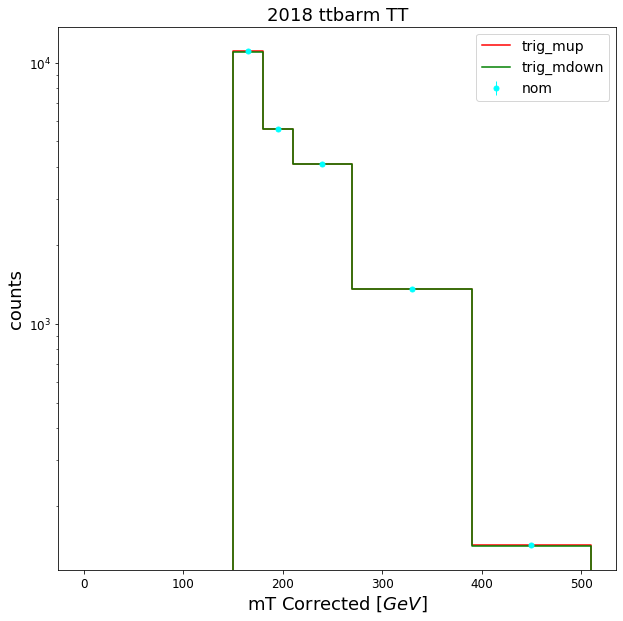

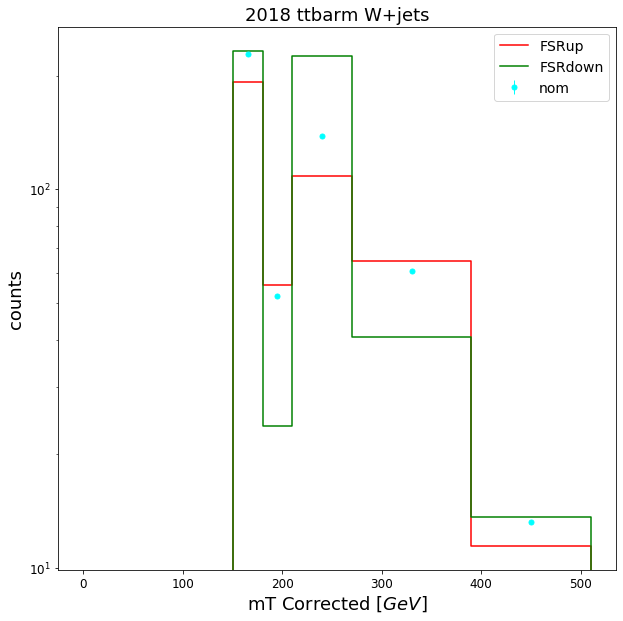

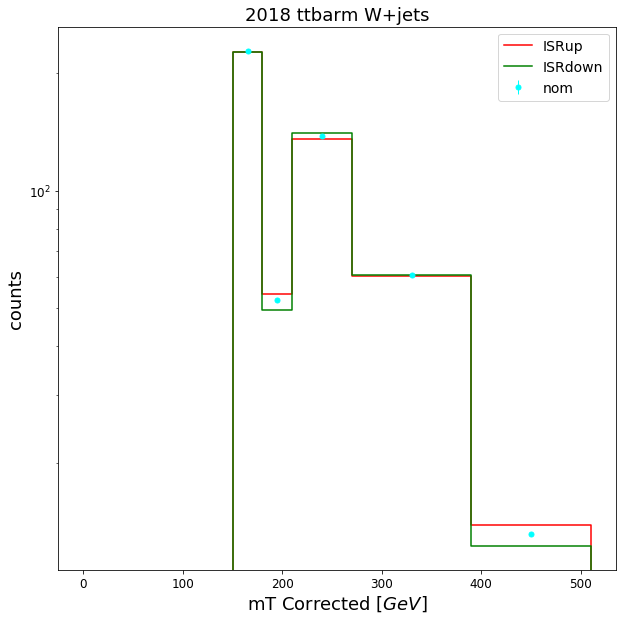

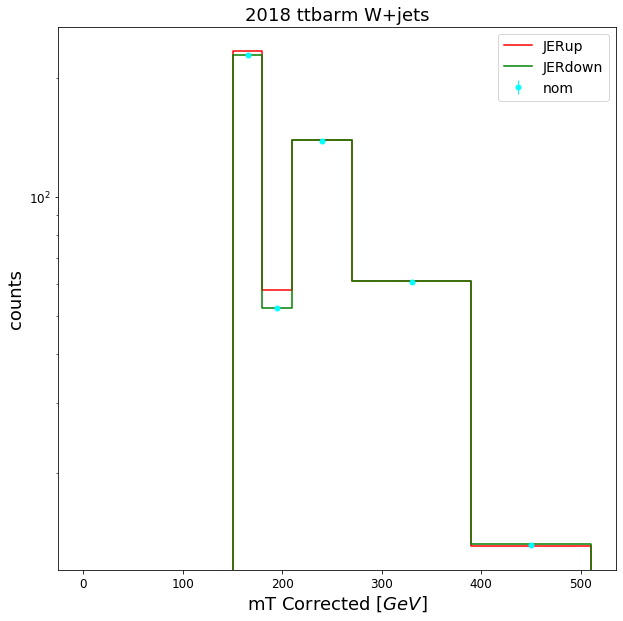

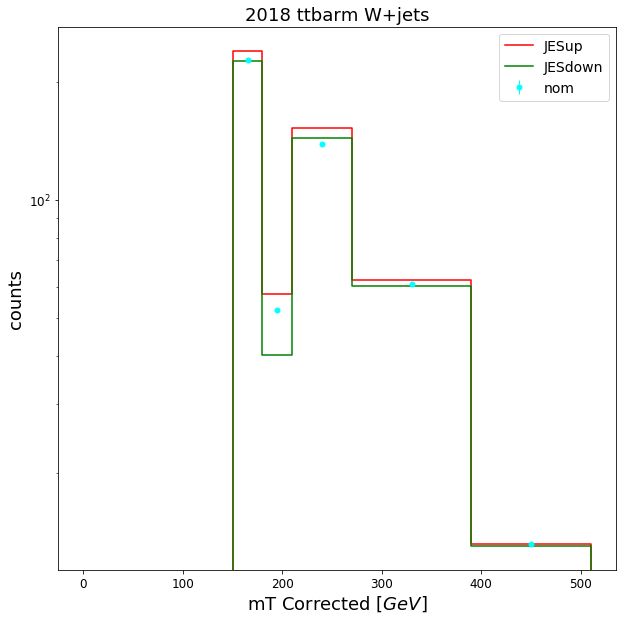

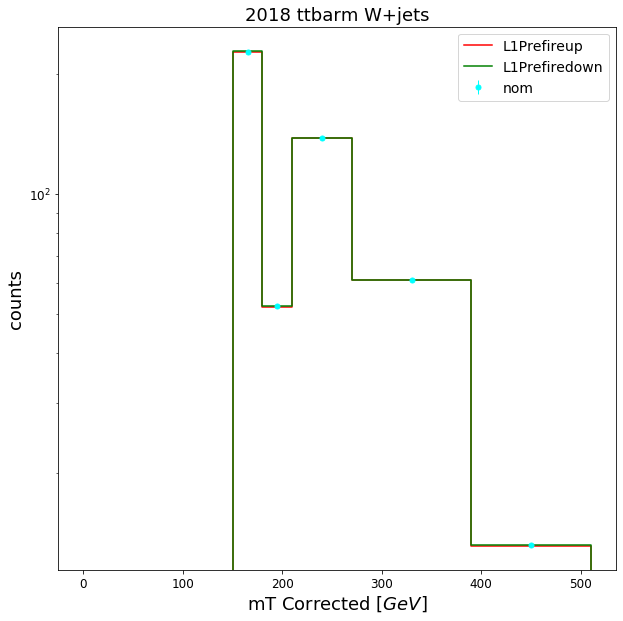

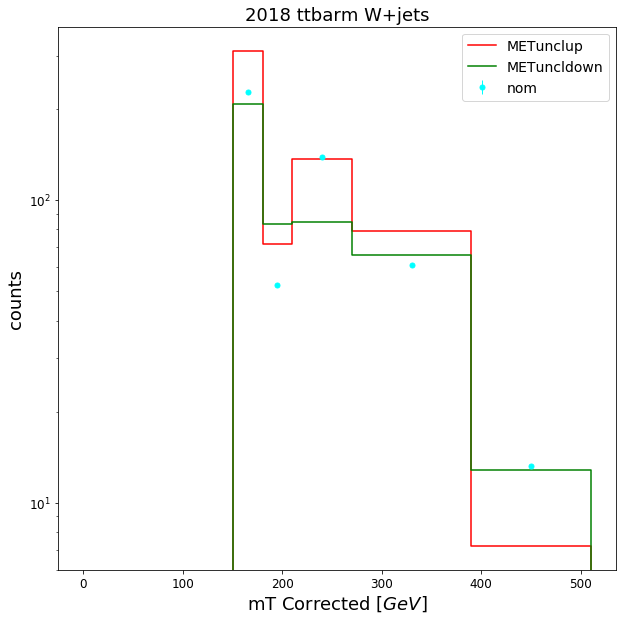

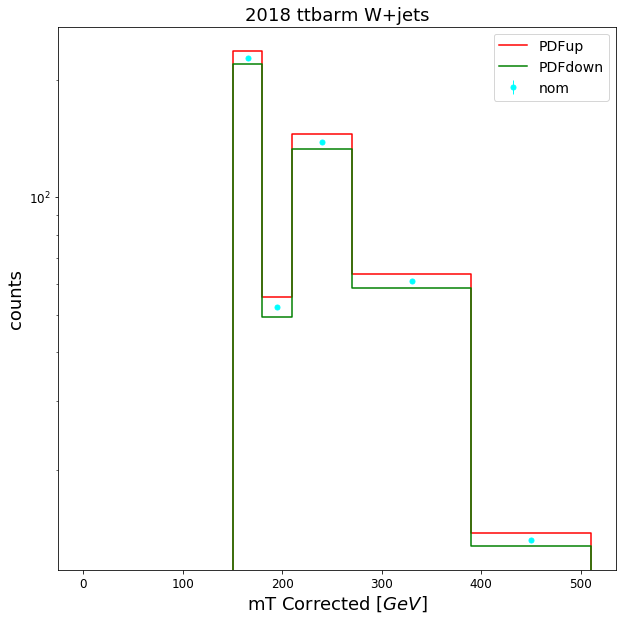

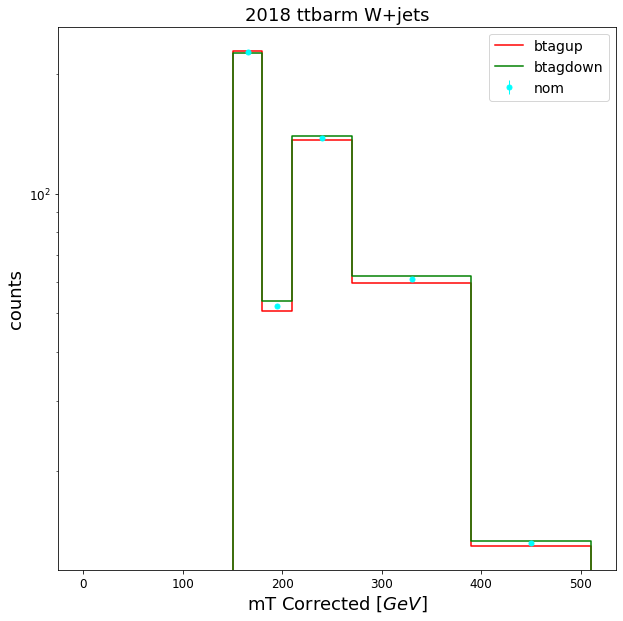

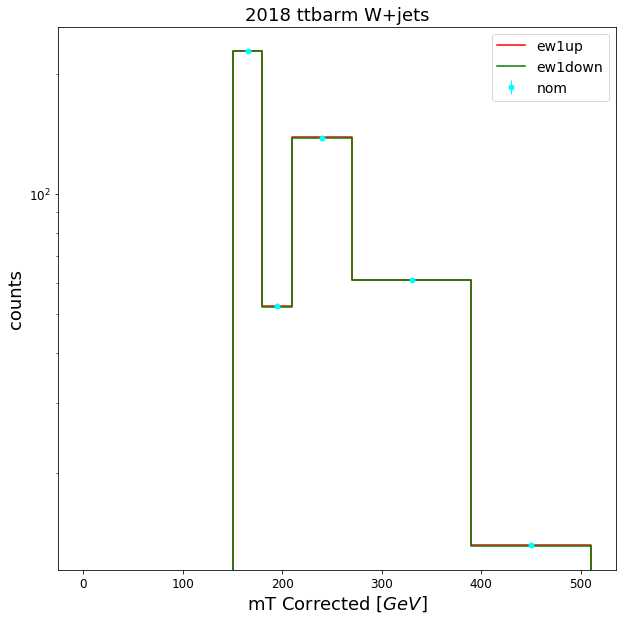

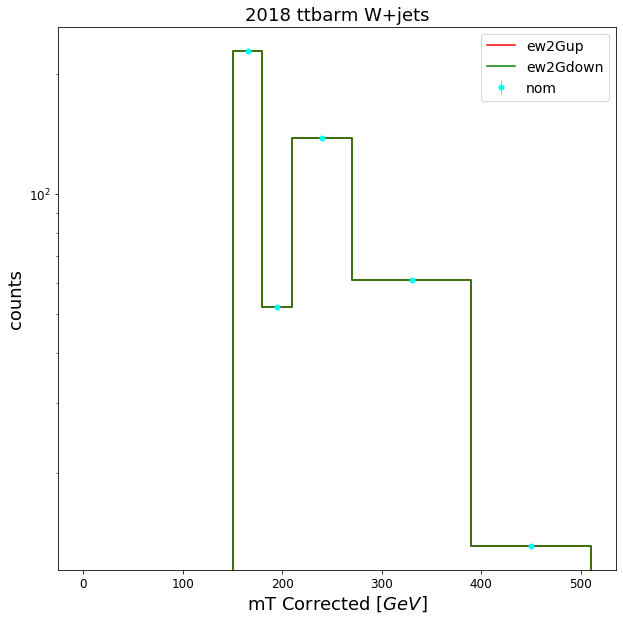

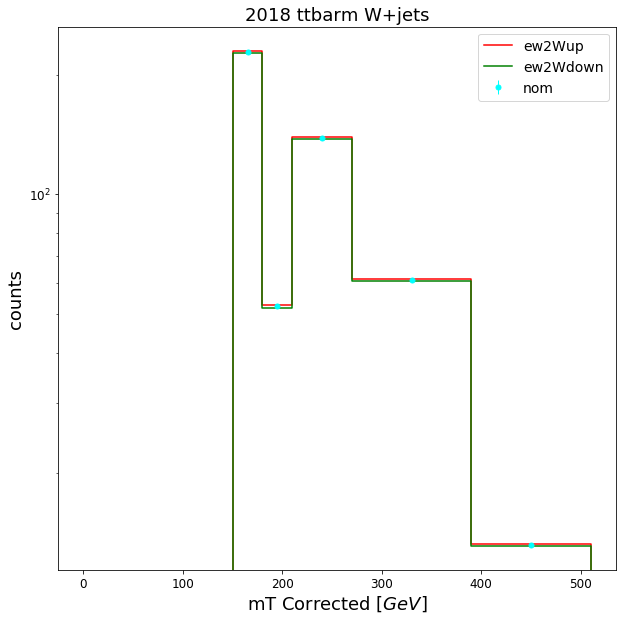

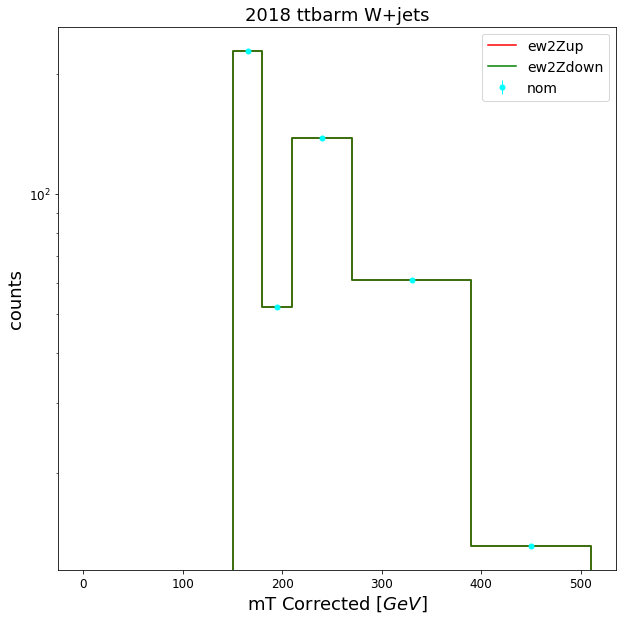

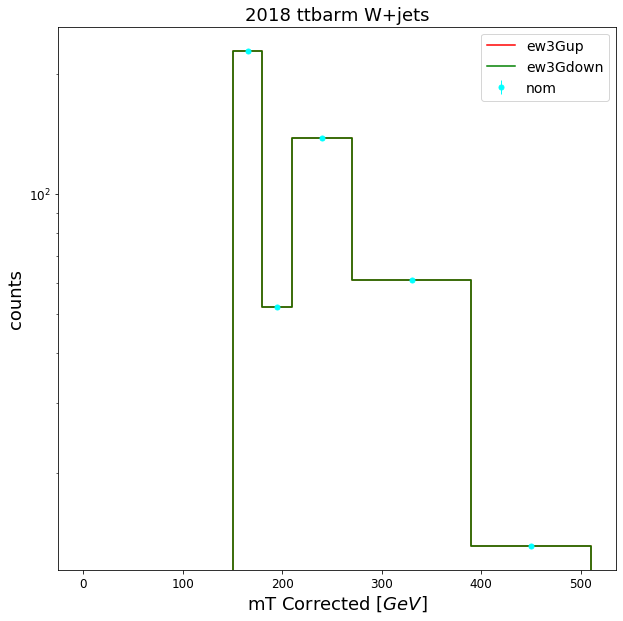

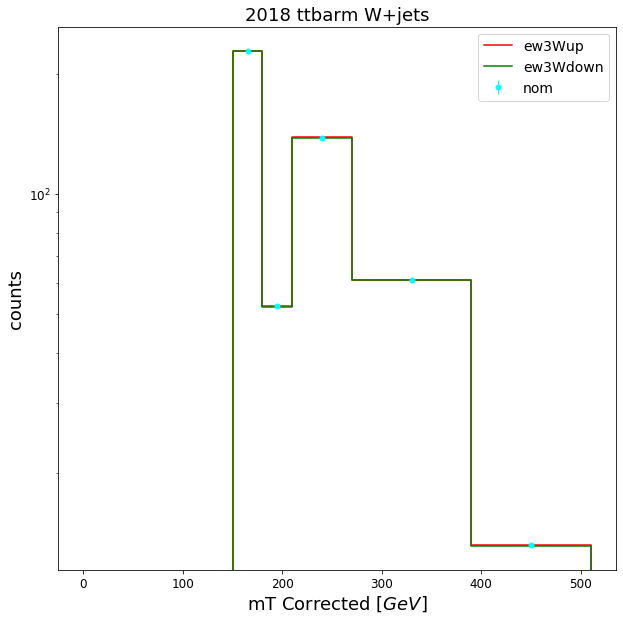

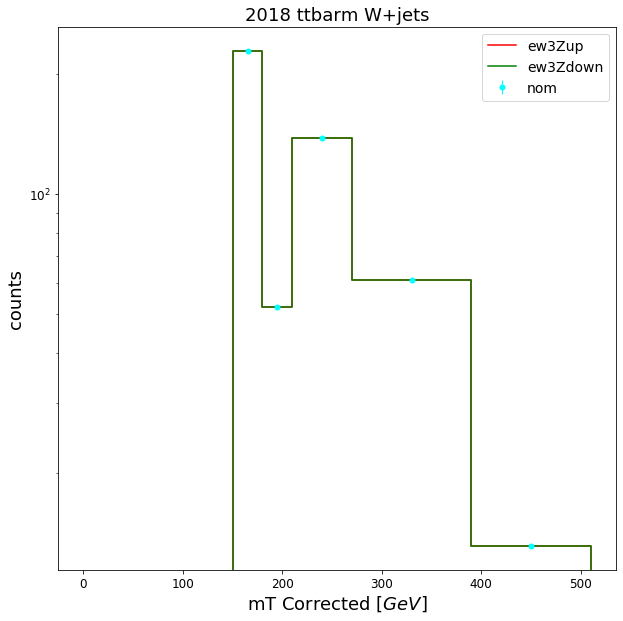

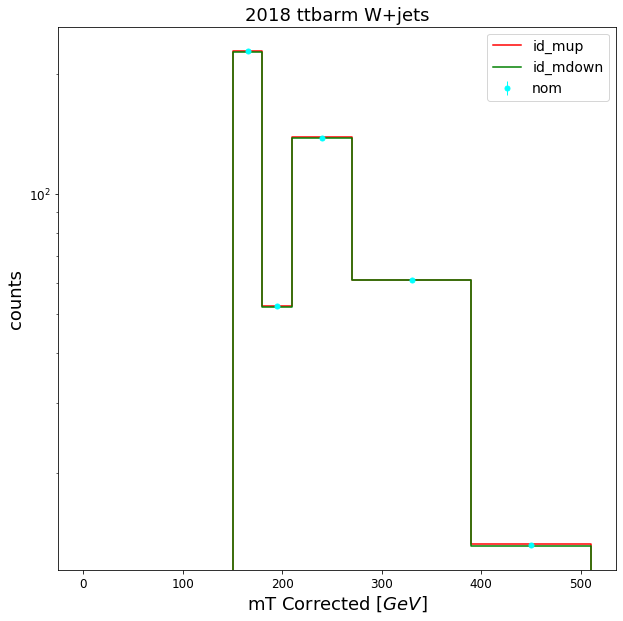

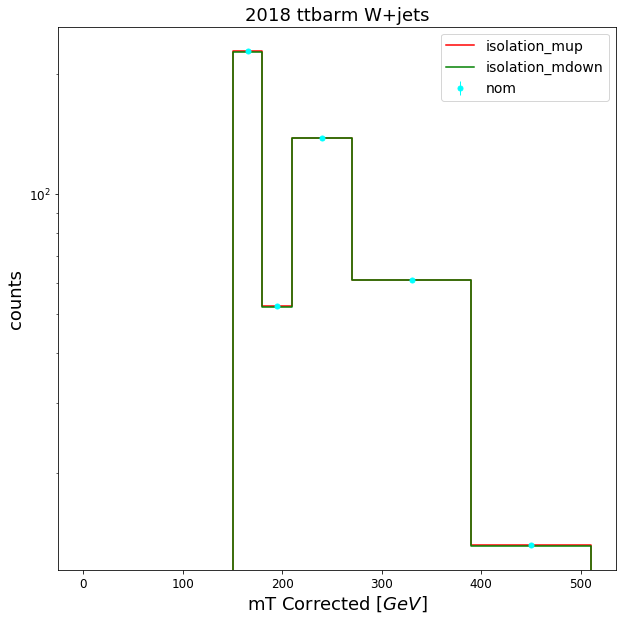

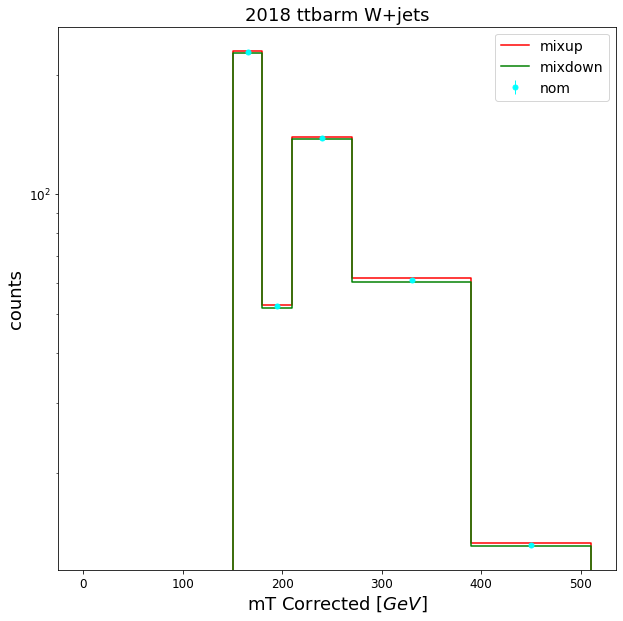

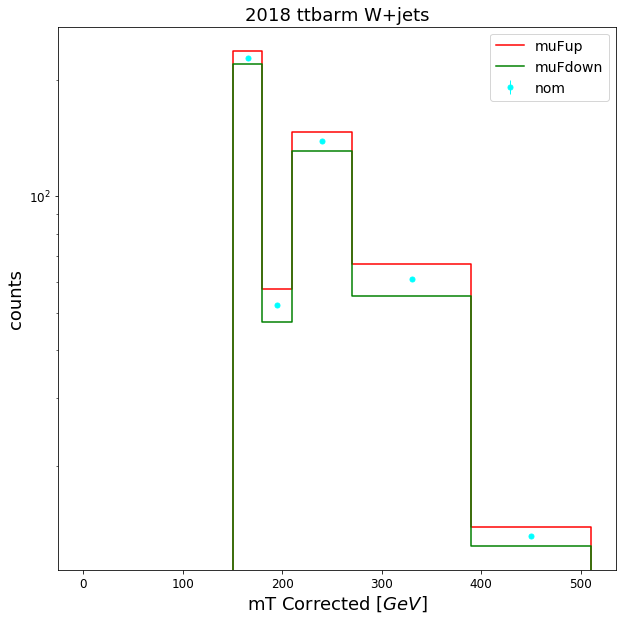

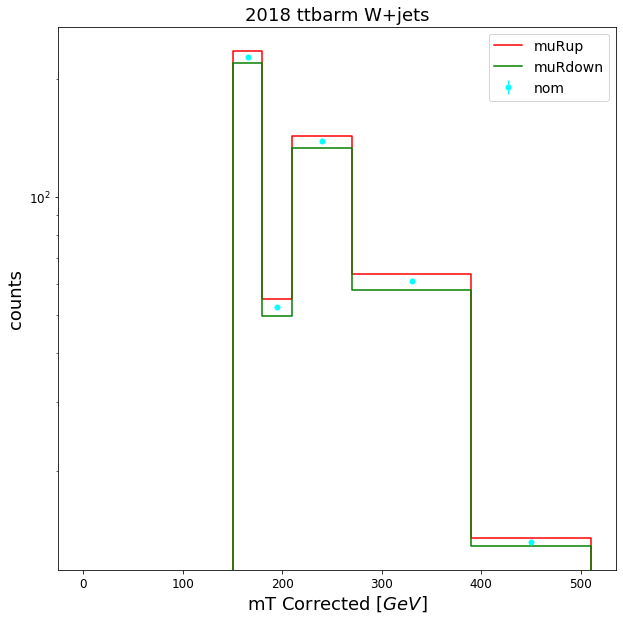

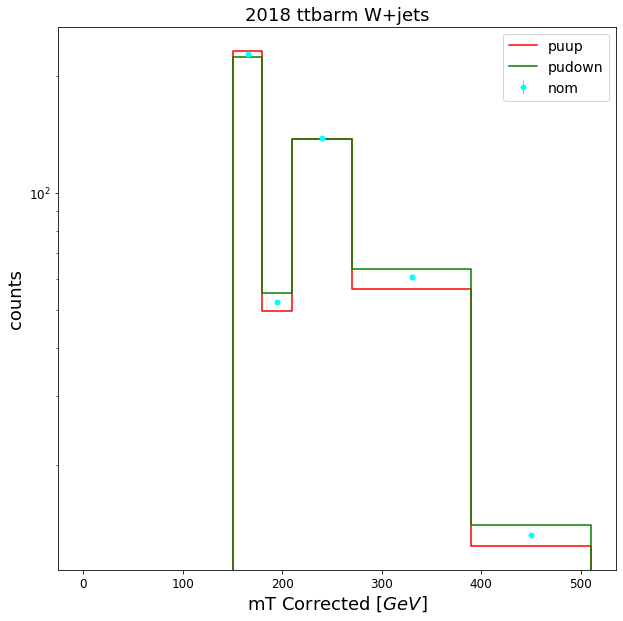

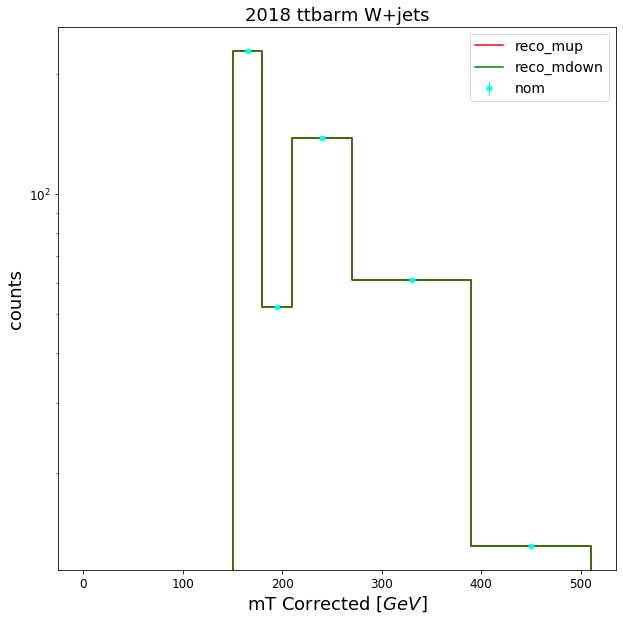

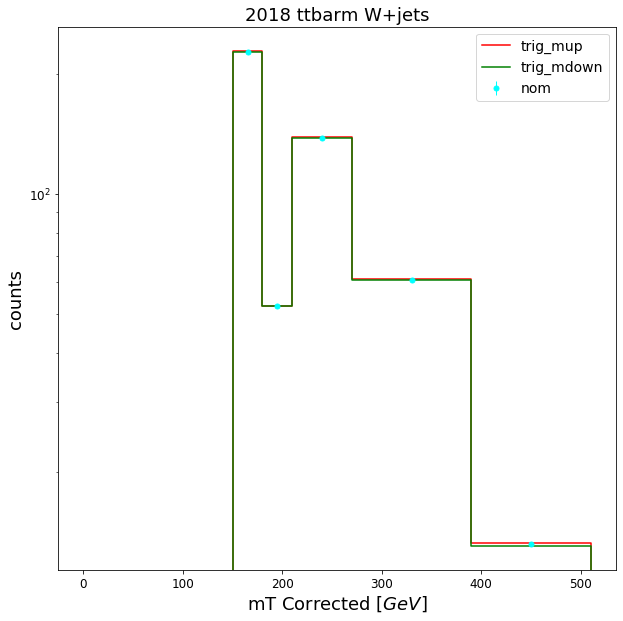

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
import re
cr = 'ttbarm'
# p ='DY+jets'
for p in bkg_hists['template'].integrate("region", cr).identifiers('process'):
#     print(p)
#     exit()
#     if "W+jets" not in str(p):continue
    systematics = []
    for syst in bkg_hists['template'].integrate('region', cr).integrate('process', p).identifiers('systematic'):
        if (re.search("Up$", str(syst))):
            systematics.append(str(syst)[:-2])
    # sys = 'pu'


    for sys in systematics:
#         if ("id_e" in sys):pass
#         elif ("JES" in sys):pass
#         elif ("JER" in sys):pass
#         elif ("METuncl" in sys): pass
#         else: continue
        bins = bkg_hists['template'].integrate('region', cr).integrate("systematic",sys+"Down").axis("mT_corrected").edges()[()]
        down = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Down').integrate('process',p).integrate('npvs').values()[()]
        nom = bkg_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('process',p).integrate('npvs').values()[()]
        up = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Up').integrate('process',p).integrate('npvs').values()[()]
#         data = data_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]

        if "e" in cr[-1]:
            label_data = "EGamma"
        else: label_data = "SingleMuon"
        f, ax = plt.subplots(figsize=[10,10])
#         hep.histplot(data, bins,color='black',histtype='errorbar',
#         label=label_data)
        hep.histplot(up, bins, color='red',
        label=sys+"up")
        hep.histplot(down, bins, color='green',
        label=sys+"down")
        hep.histplot(nom, bins, color='cyan',histtype='errorbar',
        label="nom")
        ax.legend()
        ax.set_yscale('log')
        ax.set_ylabel("counts")
        ax.set_xlabel("mT Corrected $[GeV]$")
        ax.set_title("2018 "+cr+" "+str(p))

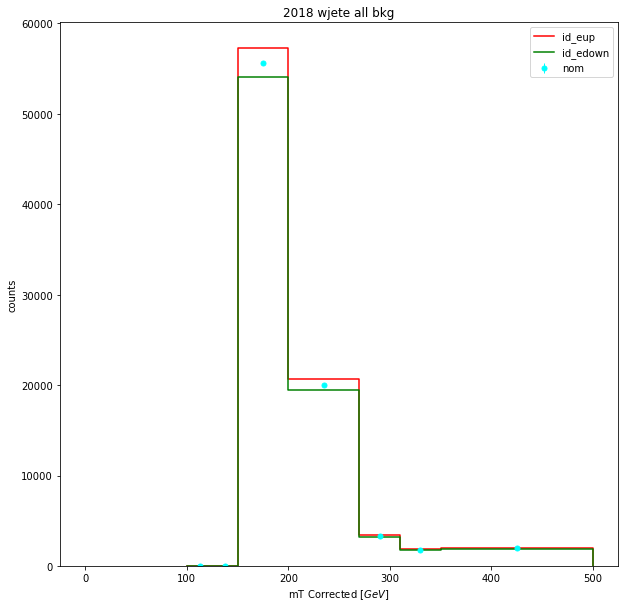

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
import re
cr = 'wjete'
systematics = []
for syst in bkg_hists['template'].integrate('region', cr).identifiers('systematic'):
    if (re.search("Up$", str(syst))):
        systematics.append(str(syst)[:-2])


for sys in systematics:
    if ("id_e" in sys):pass
#     elif ("JES" in sys):pass
#     elif ("FSR" in sys): pass
    else: continue
    bins = bkg_hists['template'].integrate('region', cr).integrate("systematic",sys+"Down").axis("mT_corrected").edges()[()]
#     data = data_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
    down = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Down').integrate('npvs').integrate('process').values()[()]
    nom = bkg_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
    up = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Up').integrate('npvs').integrate('process').values()[()]

    f, ax = plt.subplots(figsize=[10,10])
#     hep.histplot(data, bins,color='black',histtype='errorbar',
#     label="Egamma")
    hep.histplot(up, bins, color='red',
    label=sys+"up")
    hep.histplot(down, bins, color='green',
    label=sys+"down")
    hep.histplot(nom, bins, color='cyan',histtype='errorbar',
    label="nom")
    ax.legend()
#     ax.set_yscale('log')
    ax.set_ylabel("counts")
    ax.set_xlabel("mT Corrected $[GeV]$")
    ax.set_title("2018 "+cr+ " all bkg")

In [10]:
signal_hists['mT_corrected'].integrate('systematic','nominal').identifiers('process')

[<StringBin (Mphi-1000_Mchi-1000) instance at 0x7f5ee62fa390>,
 <StringBin (Mphi-1000_Mchi-150) instance at 0x7f5ee62fa3c8>,
 <StringBin (Mphi-1250_Mchi-150) instance at 0x7f5ee62fa400>,
 <StringBin (Mphi-1495_Mchi-750) instance at 0x7f5ee62fa438>,
 <StringBin (Mphi-1500_Mchi-1000) instance at 0x7f5ee62fa470>,
 <StringBin (Mphi-1500_Mchi-150) instance at 0x7f5ee62fa4a8>,
 <StringBin (Mphi-1700_Mchi-800) instance at 0x7f5ee62fa4e0>,
 <StringBin (Mphi-1750_Mchi-150) instance at 0x7f5ee62fa518>,
 <StringBin (Mphi-1750_Mchi-700) instance at 0x7f5ee62fa550>,
 <StringBin (Mphi-195_Mchi-100) instance at 0x7f5ee62fa588>,
 <StringBin (Mphi-1995_Mchi-1000) instance at 0x7f5ee62fa5c0>,
 <StringBin (Mphi-2000_Mchi-1500) instance at 0x7f5ee62fa5f8>,
 <StringBin (Mphi-2000_Mchi-150) instance at 0x7f5ee62fa630>,
 <StringBin (Mphi-2000_Mchi-500) instance at 0x7f5ee62fa668>,
 <StringBin (Mphi-200_Mchi-150) instance at 0x7f5ee62fa6a0>,
 <StringBin (Mphi-200_Mchi-50) instance at 0x7f5ee62fa6d8>,
 <String

In [14]:
signal_hists['mT_corrected'].integrate('systematic','nominal').integrate('process', ["Mphi-1000_Mchi-1000", 'Mphi-1000_Mchi-150'])

<Hist (region,mT_corrected) instance at 0x7f5ed15b9550>

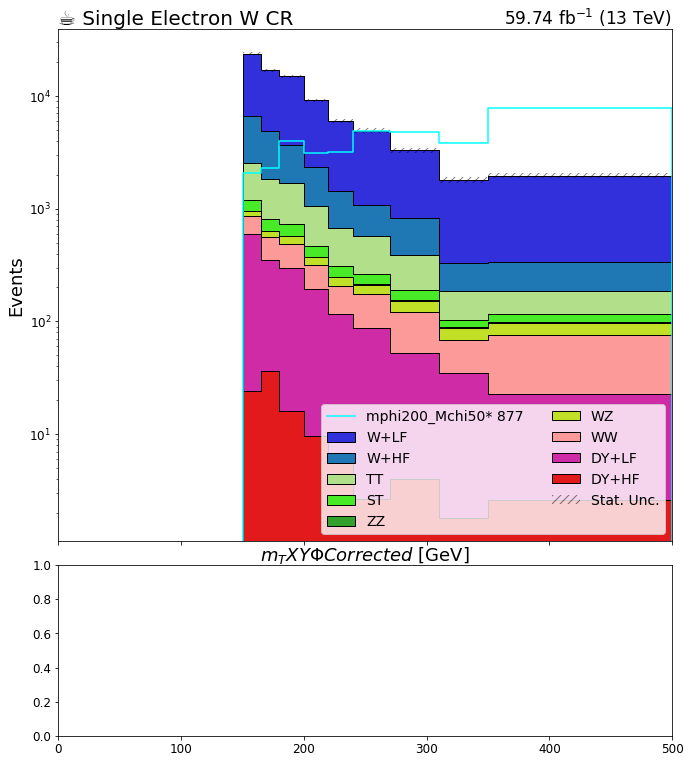

In [42]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'wjete'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
#     if key=='sumw': continue
#     if key=='template': continue
#     if key=='cutflow': continue
#     if key=='W_gen_pT':continue
#     if key=='Z_gen_pT': continue
    if 'mT_corrected' not in key: continue
#     if key!='mT_corrected': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region) : continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']
# '#a6cee3'

        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
#         plot.plot1d(data_hists[key].integrate('systematic','nominal').integrate('region',j)[data[year][str(j)]],            
#                 overlay="process",
#                 ax=ax,
#                 clear=False,
#                 error_opts=data_err_opts
#                    )

        plot.plot1d(bkg_hists[key].integrate('systematic','nominal').integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        mphi200_Mchi50= signal_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process','Mphi-1250_Mchi-150').values()[()]
        hep.histplot(mphi200_Mchi50*877, bins, color='cyan',label="mphi200_Mchi50* 877",ax=ax)
        
#         plot.plotratio(data_hists[key].integrate('systematic','nominal').integrate('region',j).integrate('process',data[year][str(j)]), 
#                    bkg_hists[key].integrate('systematic','nominal').integrate('region',j).sum('process'),
#                    ax=rax,
# #                    overflow='over',
#                    error_opts=data_err_opts,
#                    denom_fill_opts={},
#                    guide_opts={},
#                    unc='num'
#                    )
        
#         rax.set_ylabel('Ratio (data/MC)')
#         rax.set_ylim(0.,2.)
#         rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
#         fig.savefig(os.path.join(plot_path, plot_name))

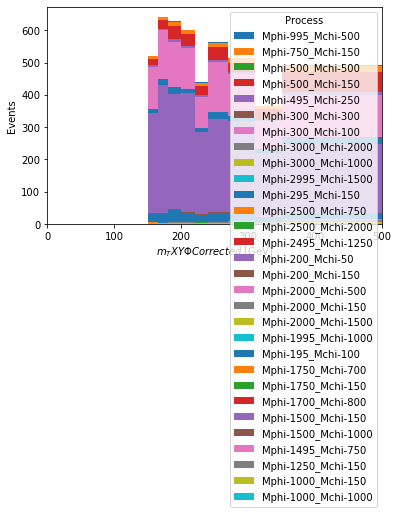

In [7]:
plot.plot1d(signal_hists['mT_corrected'].integrate('systematic','nominal').integrate('region','wjete'),
                overlay="process",
#                 ax=ax,
                clear=True,
                stack=True,
#                 fill_opts=fill_opts,
#                 error_opts=error_opts
                   )

Text(0.5, 1.0, '2018 sre')

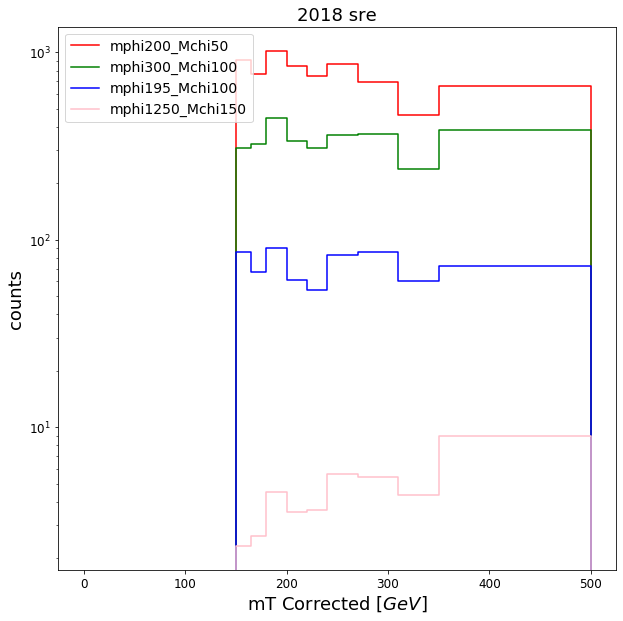

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
import re
cr = 'sre'





bins = signal_hists['template'].integrate('region', cr).integrate("systematic",'nominal').axis("mT_corrected").edges()[()]
#     data = data_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
mphi200_Mchi50 = signal_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process','Mphi-200_Mchi-50').values()[()]
mphi300_Mchi100 = signal_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process','Mphi-300_Mchi-100').values()[()]
mphi195_Mchi100 = signal_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process','Mphi-195_Mchi-100').values()[()]
mphi1250_Mchi150 = signal_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process','Mphi-1250_Mchi-150').values()[()]
# mphi200_Mchi50 = signal_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process','Mphi-200_Mchi-50').values()[()]

f, ax = plt.subplots(figsize=[10,10])
#     hep.histplot(data, bins,color='black',histtype='errorbar',
#     label="Egamma")
hep.histplot(mphi200_Mchi50, bins, color='red',label="mphi200_Mchi50")
hep.histplot(mphi300_Mchi100, bins, color='green',label="mphi300_Mchi100")
hep.histplot(mphi195_Mchi100, bins, color='blue',label="mphi195_Mchi100")
hep.histplot(mphi1250_Mchi150, bins, color='pink',label="mphi1250_Mchi150")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]$")
ax.set_title("2018 "+cr)